# 2. Data Preparation

Upload zip & read all CSV files 🗃️

In [1]:
# ============================================================
# LOAD ALL 20YY GNSS SCINTILLATION DATA
# Input : 20YY.zip
# Output: df (combined satellite-level observations)
# ============================================================

import pandas as pd
import numpy as np

from io import BytesIO
from zipfile import ZipFile
from google.colab import files


# ============================================================
# 1. UPLOAD ZIP FILE
# ============================================================

uploaded = files.upload()

if not uploaded:
    raise ValueError("No ZIP file uploaded.")

zip_name = next(iter(uploaded))

if not zip_name.lower().endswith(".zip"):
    raise ValueError("Please upload a ZIP file.")


# ============================================================
# 2. READ ALL CSV FILES
# ============================================================

dataframes = []
failed_files = []

with ZipFile(BytesIO(uploaded[zip_name])) as archive:

    csv_files = sorted(
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
        and "__MACOSX" not in name
        and not name.rsplit("/", 1)[-1].startswith("._")
    )

    if not csv_files:
        raise ValueError("No CSV files found in the ZIP archive.")

    print("ZIP file:", zip_name)
    print("CSV files found:", len(csv_files))

    for file_name in csv_files:

        try:
            daily_df = pd.read_csv(
                BytesIO(archive.read(file_name)),
                skiprows=2,              # Skip introductory lines
                header=0,                # Third line contains headers
                usecols=range(19),       # Ignore extra trailing field
                skipinitialspace=True,
                encoding="utf-8-sig"
            )

            # Clean column names.
            daily_df.columns = (
                daily_df.columns.astype(str).str.strip()
            )

            # Remove completely empty rows.
            daily_df = daily_df.dropna(how="all")

            if not daily_df.empty:
              dataframes.append(daily_df)

        except Exception as error:
            failed_files.append((file_name, str(error)))


# ============================================================
# 3. CHECK LOADING RESULTS
# ============================================================

print("\n========== FILE LOADING SUMMARY ==========")

print("Total CSV files:", len(csv_files))
print("Successfully loaded:", len(dataframes))
print("Failed files:", len(failed_files))

if failed_files:
    print("\nFiles that could not be read:")

    for name, error in failed_files:
        print(f"{name}: {error}")

if not dataframes:
    raise ValueError(
        "No CSV files could be loaded. Check the file structure."
    )


# ============================================================
# 4. COMBINE ALL DAILY DATA INTO df
# ============================================================

# Ensure every file has the same columns.
reference_columns = dataframes[0].columns.tolist()

for i, daily_df in enumerate(dataframes):

    if daily_df.columns.tolist() != reference_columns:
        raise ValueError(
            f"Inconsistent columns in loaded file number {i + 1}."
        )

df = pd.concat(
    dataframes,
    ignore_index=True
)

# Remove completely empty rows and columns.
df = (
    df.dropna(how="all")
      .dropna(axis=1, how="all")
)


# ============================================================
# 5. VALIDATE AND SORT CHRONOLOGICALLY
# ============================================================

required_columns = [
    "YYYY", "MM", "DD", "Second", "PRN"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert sorting fields to numeric.
sort_columns = []

for col in required_columns:

    sort_col = f"_sort_{col}"

    df[sort_col] = pd.to_numeric(
        df[col], errors="coerce"
    )

    sort_columns.append(sort_col)

# Reject invalid date, time or PRN values.
# Do not restrict observations to the ZIP filename year.

if df[sort_columns].isna().any().any():
    raise ValueError(
        "Invalid date, time or PRN values detected."
    )

# Sort observations using their actual recorded values.
df = (
    df.sort_values(
        sort_columns,
        kind="stable"
    )
    .drop(columns=sort_columns)
    .reset_index(drop=True)
)


# ============================================================
# 6. CREATE DATE COLUMN FOR EASY INSPECTION
# ============================================================

df["_DATE"] = pd.to_datetime(
    {
        "year": pd.to_numeric(df["YYYY"]),
        "month": pd.to_numeric(df["MM"]),
        "day": pd.to_numeric(df["DD"])
    },
    errors="coerce"
)

if df["_DATE"].isna().any():
    raise ValueError("Invalid calendar dates detected.")

df = df.sort_values(
    ["_DATE", "Second", "PRN"],
    kind="stable"
).reset_index(drop=True)


print("\n========== OBSERVATIONS BY YEAR ==========")

year_counts = (
    pd.to_numeric(df["YYYY"])
    .value_counts()
    .sort_index()
)

print(year_counts.to_string())

print("\nYears found in dataset:")
print(sorted(pd.to_numeric(df["YYYY"]).unique()))


ADAPTER: supplying original 2019.zip to files.upload()
ZIP file: 2019.zip
CSV files found: 221

========== FILE LOADING SUMMARY ==========
Total CSV files: 221
Successfully loaded: 221
Failed files: 0

========== OBSERVATIONS BY YEAR ==========
YYYY
2019    2733017
2020          9

Years found in dataset:
[np.int64(2019), np.int64(2020)]


Data Preprocessing (Cleaning 🧼 🧹 🧽 )

[Reference](https://chatgpt.com/s/t_6af001d1208c8191ae072d3917d6b54e)

INITIAL DATA QUALITY ASSESSMENT
Total observations: 2733026
Total columns: 20

Missing values in original dataset:
YYYY                                 0
MM                                   0
DD                                   0
Second                               0
Total satellite                      0
PRN                                  0
Azimuth                              0
Elevation                            0
L1 CNo                               0
Total S4                             0
Correction to total S4               0
60-second phase sigma                0
Average of Carrier divergence        0
Sigma of Carrier Divergence          0
TEC at TOW                       54090
L1 Lock time                         0
Channel status                       0
L2 Lock Time                         0
L2 CNo                               0
_DATE                                0
dtype: int64

Duplicate observations:
Duplicate rows: 0

Date coverage:
Start: 2019-01-01 00:00:00
End: 2

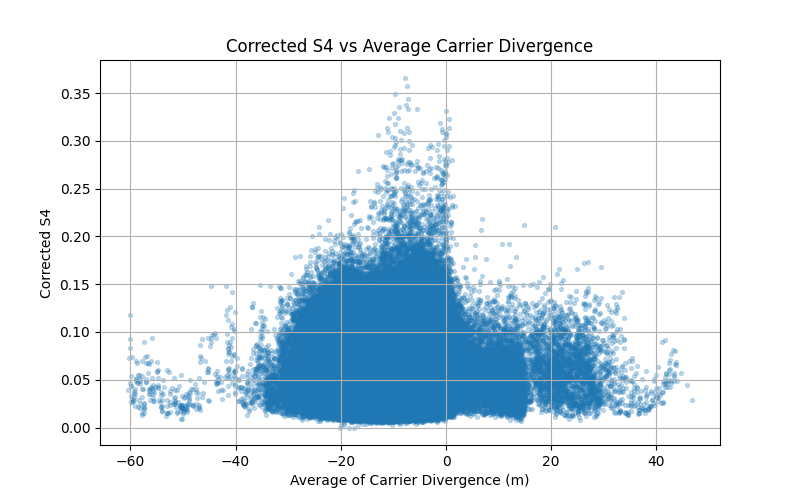

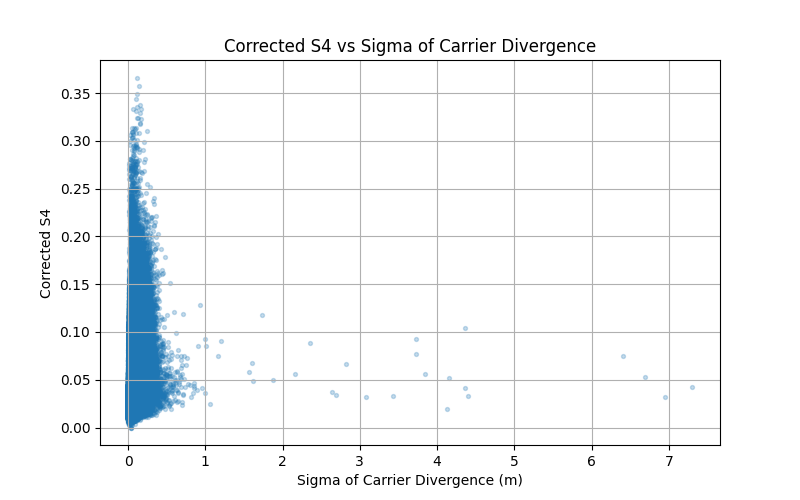

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# GNSS S4 PREPROCESSING — 2016
# Uses the existing DataFrame: df
#
# Target: Corrected S4 - Amplitude scintillation
# S4 threshold for later classification: 0.20
#
# Quality criteria:
#   L1 Lock time > 60 seconds
#   Elevation > 25 degrees
#
# Output:
#   df_clean
#   One additional column: Corrected_S4
# ============================================================


# ============================================================
# 1. ESTABLISH THE SCIENTIFIC DEFINITION OF THE TARGET
# ============================================================

# S4 is the amplitude scintillation index.
# It measures the normalised standard deviation of received
# signal intensity.
#
# Corrected S4 will be used as the target measurement.
#
# Proposed threshold for the later binary classification:
#   Corrected S4 < 0.20  : Non-scintillation / below threshold
#   Corrected S4 >= 0.20 : Scintillation
#
# The threshold is an operational choice, not a universal
# boundary applicable to every receiver or study.

S4_THRESHOLD = 0.20


# ============================================================
# 1.5. INITIAL DATA QUALITY ASSESSMENT
# ============================================================

print("\nINITIAL DATA QUALITY ASSESSMENT")

print("Total observations:", len(df))
print("Total columns:", len(df.columns))

print("\nMissing values in original dataset:")
print(df.isna().sum())

print("\nDuplicate observations:")

duplicate_count = df.duplicated(
    subset=["_DATE", "Second", "PRN"]
).sum()

print("Duplicate rows:", duplicate_count)

print("\nDate coverage:")
print("Start:", df["_DATE"].min())
print("End:", df["_DATE"].max())
print("Unique dates:", df["_DATE"].nunique())

print("\nSatellite coverage:")
print("Unique PRNs:", df["PRN"].nunique())
print("PRNs:", sorted(df["PRN"].dropna().unique()))


# ============================================================
# 2. APPLY RECEIVER-SPECIFIC QUALITY CRITERIA
# ============================================================

# README recommendations:
# L1 Lock time > 60 seconds
# Elevation > 25 degrees

df_clean = df.copy()

initial_rows = len(df_clean)

# Record observations removed by each criterion.
# Sequential filtering prevents double-counting.

# ------------------------------------------------------------
# FILTER 1: L1 LOCK TIME
# ------------------------------------------------------------

before_lock = len(df_clean)

df_clean = df_clean.loc[
    df_clean["L1 Lock time"] > 60
].copy()

removed_lock = before_lock - len(df_clean)

# ------------------------------------------------------------
# FILTER 2: ELEVATION
# ------------------------------------------------------------

before_elevation = len(df_clean)

df_clean = df_clean.loc[
    df_clean["Elevation"] > 25
].copy()

removed_elevation = before_elevation - len(df_clean)

# ------------------------------------------------------------
# QUALITY FILTER SUMMARY
# ------------------------------------------------------------

print("\nRECEIVER-SPECIFIC QUALITY FILTERING")

print("Initial observations:", initial_rows)

print("Removed by L1 Lock time:", removed_lock)

print("Removed by Elevation:", removed_elevation)

print("Total observations removed:",
      removed_lock + removed_elevation)

print("Remaining observations:", len(df_clean))


# ============================================================
# 3. CORRECT THE S4 MEASUREMENT
# ============================================================

# The GSV4004B manual specifies an RSS correction:
#
# Corrected S4 = sqrt(Total S4^2 - Correction S4^2)
#
# If the correction is greater than Total S4, corrected S4
# is set to zero.

df_clean["Corrected_S4"] = np.sqrt(
    np.maximum(
        0,
        df_clean["Total S4"]**2 -
        df_clean["Correction to total S4"]**2
    )
)

print("\nSTEP 3: S4 CORRECTION")
print("Corrected S4 calculated.")
print("Corrected S4 minimum:", df_clean["Corrected_S4"].min())
print("Corrected S4 maximum:", df_clean["Corrected_S4"].max())


# ------------------------------------------------------------
# CORRECTED S4 STATISTICAL SUMMARY
# ------------------------------------------------------------

print("\nCORRECTED S4 STATISTICS")

print(
    df_clean["Corrected_S4"].describe()
)

print(
    "\nNegative corrected S4 values:",
    (df_clean["Corrected_S4"] < 0).sum()
)

print(
    "Missing corrected S4 values:",
    df_clean["Corrected_S4"].isna().sum()
)

print(
    "Infinite corrected S4 values:",
    np.isinf(df_clean["Corrected_S4"]).sum()
)


# ============================================================
# 4. REMOVE INVALID MEASUREMENTS AND PHYSICALLY IMPOSSIBLE VALUES
# ============================================================

# Check the validity of the observation date, time, PRN,
# satellite geometry and S4 measurements.
#
# S4 is NOT restricted to a maximum of 1 because values
# greater than 1 can occur during severe scintillation.

valid_mask = (
    df_clean["_DATE"].notna() &

    np.isfinite(df_clean["Second"]) &
    df_clean["Second"].between(0, 86399.999) &

    np.isfinite(df_clean["PRN"]) &
    (df_clean["PRN"] > 0) &
    (df_clean["PRN"] % 1 == 0) &

    np.isfinite(df_clean["Azimuth"]) &
    df_clean["Azimuth"].between(0, 360, inclusive="left") &

    np.isfinite(df_clean["Elevation"]) &
    df_clean["Elevation"].between(0, 90) &

    np.isfinite(df_clean["Total S4"]) &
    (df_clean["Total S4"] >= 0) &

    np.isfinite(df_clean["Correction to total S4"]) &
    (df_clean["Correction to total S4"] >= 0) &

    np.isfinite(df_clean["Corrected_S4"]) &
    (df_clean["Corrected_S4"] >= 0)
)

before_invalid_removal = len(df_clean)

df_clean = df_clean.loc[valid_mask].copy()

print("\nSTEP 4: INVALID MEASUREMENT REMOVAL")
print("Observations before removal:", before_invalid_removal)
print("Observations after removal:", len(df_clean))
print("Invalid observations removed:",
      before_invalid_removal - len(df_clean))

# ============================================================
# 4.5. DEFINE THE SCINTILLATION REFERENCE LABEL
# ============================================================

# Reference threshold:
# Corrected S4 < 0.20  = 0 (Below scintillation threshold)
# Corrected S4 >= 0.20 = 1 (Meets scintillation threshold)

S4_THRESHOLD = 0.20

df_clean["LABEL"] = (
    df_clean["Corrected_S4"] >= S4_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# REFERENCE LABEL DISTRIBUTION
# ------------------------------------------------------------

label_counts = df_clean["LABEL"].value_counts().sort_index()

label_percentages = (
    df_clean["LABEL"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

label_summary = pd.DataFrame({
    "Observations": label_counts,
    "Percentage (%)": label_percentages
})

label_summary.index = [
    "Below S4 threshold (0)",
    "Meets S4 threshold (1)"
]

print("\nSCINTILLATION REFERENCE LABEL DISTRIBUTION")

print(label_summary)

print("\nS4 reference threshold:", S4_THRESHOLD)

print("Total labelled observations:", len(df_clean))

# ============================================================
# 4.6. VERIFY CORRECTED S4 AND LABEL CONSISTENCY
# ============================================================

# Confirm that LABEL matches the corrected S4 threshold.

label_mismatch = (
    df_clean["LABEL"] !=
    (df_clean["Corrected_S4"] >= S4_THRESHOLD).astype(int)
).sum()

print("\nREFERENCE LABEL VERIFICATION")

print("Incorrect LABEL assignments:", label_mismatch)

print(
    "Minimum corrected S4:",
    df_clean["Corrected_S4"].min()
)

print(
    "Maximum corrected S4:",
    df_clean["Corrected_S4"].max()
)

print(
    "Mean corrected S4:",
    df_clean["Corrected_S4"].mean()
)

print(
    "Median corrected S4:",
    df_clean["Corrected_S4"].median()
)

print(
    "Standard deviation:",
    df_clean["Corrected_S4"].std()
)

# ============================================================
# 5. IDENTIFY MULTIPATH CONTAMINATION
# ============================================================

# Carrier divergence measurements can help identify
# observations potentially affected by multipath.
#
# No universal carrier-divergence cutoff is imposed here.
# Therefore, observations are investigated rather than
# automatically deleted.

print("\nSTEP 5: MULTIPATH INVESTIGATION")

print("\nCarrier divergence summary:")
print(
    df_clean[
        [
            "Average of Carrier divergence",
            "Sigma of Carrier Divergence"
        ]
    ].describe()
)

# Plot 1: Corrected S4 against average carrier divergence

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Average of Carrier divergence"],
    df_clean["Corrected_S4"],
    alpha=0.25,
    s=8
)

plt.xlabel("Average of Carrier Divergence (m)")
plt.ylabel("Corrected S4")
plt.title("Corrected S4 vs Average Carrier Divergence")
plt.grid(True)
plt.show()


# Plot 2: Corrected S4 against carrier divergence sigma

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Sigma of Carrier Divergence"],
    df_clean["Corrected_S4"],
    alpha=0.25,
    s=8
)

plt.xlabel("Sigma of Carrier Divergence (m)")
plt.ylabel("Corrected S4")
plt.title("Corrected S4 vs Sigma of Carrier Divergence")
plt.grid(True)
plt.show()


# Check correlations as supporting diagnostic information

print("\nCorrelation with Corrected S4:")

print(
    df_clean[
        [
            "Corrected_S4",
            "Average of Carrier divergence",
            "Sigma of Carrier Divergence"
        ]
    ].corr()["Corrected_S4"]
)

print(
    "\nIMPORTANT:"
    "\nHigh carrier divergence may indicate multipath contamination."
    "\nDo not remove observations using an arbitrary cutoff."
    "\nReview the plots before deciding whether an additional"
    "\nreceiver-specific multipath rejection rule is justified."
)


# ============================================================
# 6. HANDLE MISSING VALUES CORRECTLY
# ============================================================

# Missing TEC does not invalidate an otherwise valid S4
# observation. Therefore, retain rows with missing TEC.
#
# Missing target measurements have already been excluded
# in Step 4.
#
# Optional predictor missing values are retained at this
# preprocessing stage. They can be handled later using
# training-data-only imputation.

print("\nSTEP 6: MISSING VALUE CHECK")

print("Missing values in each column:")

print(df_clean.isna().sum())

print(
    "\nMissing TEC observations:",
    df_clean["TEC at TOW"].isna().sum()
)

print(
    "Observations retained despite missing TEC:",
    df_clean["TEC at TOW"].isna().sum()
)


# ============================================================
# 7. CHECK DUPLICATE OBSERVATIONS AND DATA CONTINUITY
# ============================================================

# An observation is identified by:
#   Date + Second + PRN
#
# Duplicate observations are reported but not automatically
# removed. Their cause should be investigated first.

duplicate_mask = df_clean.duplicated(
    subset=["_DATE", "Second", "PRN"],
    keep=False
)

duplicates = df_clean.loc[duplicate_mask].sort_values(
    ["_DATE", "PRN", "Second"]
)

print("\nSTEP 7: DUPLICATE OBSERVATIONS")

print("Number of duplicate rows:", len(duplicates))
print(
    "Number of duplicated observation groups:",
    df_clean.duplicated(
        subset=["_DATE", "Second", "PRN"]
    ).sum()
)

if len(duplicates) > 0:
    print("\nExample duplicate observations:")
    print(
        duplicates[
            ["_DATE", "Second", "PRN", "Corrected_S4"]
        ].head(10)
    )
else:
    print("No duplicate observations found.")


# ------------------------------------------------------------
# CHECK DATA CONTINUITY
# ------------------------------------------------------------

# The receiver provides minutely observations.
# Check time differences for each satellite on each date.
#
# A difference greater than 60 seconds indicates a gap
# between consecutive observations.
#
# Gaps are reported, not interpolated or filled.

ordered = df_clean.sort_values(
    ["_DATE", "PRN", "Second"]
)

time_differences = (
    ordered.groupby(["_DATE", "PRN"])["Second"].diff()
)

gaps = time_differences[time_differences > 60]

print("\nDATA CONTINUITY")

print("Number of time gaps greater than 60 seconds:", len(gaps))

if len(gaps) > 0:
    print("Largest time gap (seconds):", gaps.max())
else:
    print("No gaps greater than 60 seconds found.")


# ============================================================
# FINAL PREPROCESSING SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("FINAL PREPROCESSING SUMMARY")
print("=" * 55)

print("Original observations:", len(df))
print("Final cleaned observations:", len(df_clean))

print("Observation dates:", df_clean["_DATE"].nunique())
print("Unique satellite PRNs:", df_clean["PRN"].nunique())

print(
    "Date range:",
    df_clean["_DATE"].min(),
    "to",
    df_clean["_DATE"].max()
)

print(
    "Corrected S4 range:",
    df_clean["Corrected_S4"].min(),
    "to",
    df_clean["Corrected_S4"].max()
)

print("Final number of columns:", len(df_clean.columns))

print("\nREFERENCE LABEL COUNTS")

print("LABEL 0:", (df_clean["LABEL"] == 0).sum())
print("LABEL 1:", (df_clean["LABEL"] == 1).sum())

print("\nMISSING PREDICTOR VALUES")

predictor_features = [
    "L1 CNo",
    "L2 CNo",
    "Elevation",
    "Azimuth",
    "TEC at TOW",
    "Average of Carrier divergence",
    "Sigma of Carrier Divergence",
    "Total satellite"
]

print(df_clean[predictor_features].isna().sum())

print("\nCORRECTED S4 SUMMARY")

print(df_clean["Corrected_S4"].describe())

print("\nFinal DataFrame: df_clean")

Data Preprocessing (TARGET 🎯  AND DATA SPLIT)


[Reference](https://chatgpt.com/s/t_6af00195dfb88191920e0e096b1218fb)

STEP 1: CORRECTED S4 DISTRIBUTION
count    1.783960e+06
mean     4.609892e-02
std      2.327560e-02
min      0.000000e+00
25%      2.908608e-02
50%      4.116892e-02
75%      5.802474e-02
max      3.663138e-01
Name: Corrected_S4, dtype: float64
PLOT: cell_09_plot_003.png

STEP 2: CREATE BINARY CLASSIFICATION LABEL
Label definition:
0 = Corrected S4 < 0.20
1 = Corrected S4 >= 0.20

STEP 3: CLASS DISTRIBUTION AT THRESHOLD 0.20
            Class   Count  Percentage
Non-scintillation 1783376   99.967264
    Scintillation     584    0.032736

STEP 4: SENSITIVITY ANALYSIS AT THRESHOLD 0.30
            Class   Count  Percentage
Non-scintillation 1783928   99.998206
    Scintillation      32    0.001794

Maximum corrected S4: 0.36631378625435324

STEP 5: FEATURE SELECTION

Selected model input features:
- L1 CNo
- L2 CNo
- Azimuth_sin
- Azimuth_cos
- Elevation
- Average of Carrier divergence
- Corrected_S4
- TEC at TOW
- Sigma of Carrier Divergence

Reference column: LABEL
Evaluation measureme

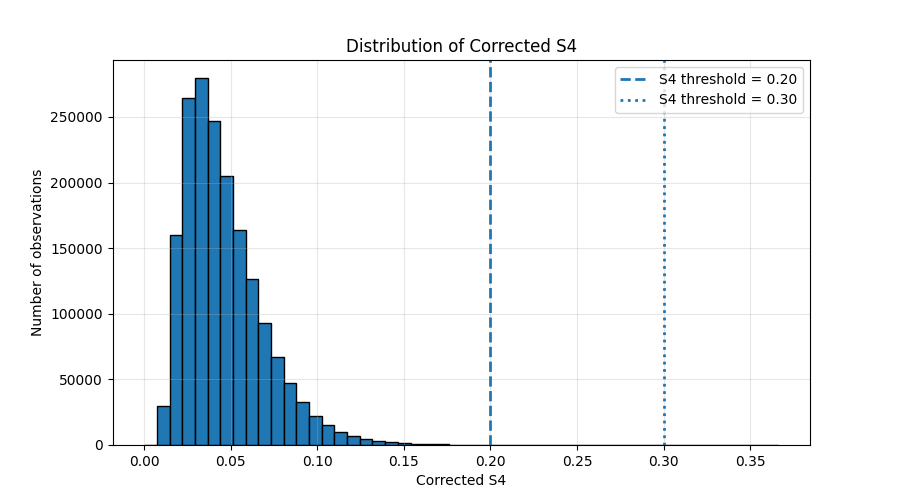

In [3]:
# ============================================================
# GNSS SCINTILLATION CLASSIFICATION — TARGET AND DATA SPLIT
#
# Uses existing DataFrame: df_clean
#
# Target:
#   Corrected_S4 < 0.20  = 0
#   Corrected_S4 >= 0.20 = 1
#
# Chronological split:
#   70% Training
#   15% Validation
#   15% Testing
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. CHECK CORRECTED S4 DISTRIBUTION
# ============================================================

print("=" * 60)
print("STEP 1: CORRECTED S4 DISTRIBUTION")
print("=" * 60)

print(df_clean["Corrected_S4"].describe())

# Plot distribution

plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["Corrected_S4"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    0.20,
    linestyle="--",
    linewidth=2,
    label="S4 threshold = 0.20"
)

plt.axvline(
    0.30,
    linestyle=":",
    linewidth=2,
    label="S4 threshold = 0.30"
)

plt.xlabel("Corrected S4")
plt.ylabel("Number of observations")
plt.title("Distribution of Corrected S4")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 2. CREATE BINARY LABEL USING 0.20
# ============================================================

print("\n" + "=" * 60)
print("STEP 2: CREATE BINARY CLASSIFICATION LABEL")
print("=" * 60)

S4_THRESHOLD = 0.20

df_clean["LABEL"] = (
    df_clean["Corrected_S4"] >= S4_THRESHOLD
).astype(int)

print("Label definition:")
print("0 = Corrected S4 < 0.20")
print("1 = Corrected S4 >= 0.20")


# ============================================================
# 3. COUNT CLASS 0 AND CLASS 1
# ============================================================

print("\n" + "=" * 60)
print("STEP 3: CLASS DISTRIBUTION AT THRESHOLD 0.20")
print("=" * 60)

class_counts = df_clean["LABEL"].value_counts().sort_index()

class_percentages = (
    df_clean["LABEL"].value_counts(normalize=True).sort_index() * 100
)

class_summary = pd.DataFrame({
    "Class": ["Non-scintillation", "Scintillation"],
    "Count": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ],
    "Percentage": [
        class_percentages.get(0, 0),
        class_percentages.get(1, 0)
    ]
})

print(class_summary.to_string(index=False))


# ============================================================
# 4. CHECK 0.30 AS A SENSITIVITY THRESHOLD
# ============================================================

print("\n" + "=" * 60)
print("STEP 4: SENSITIVITY ANALYSIS AT THRESHOLD 0.30")
print("=" * 60)

# Temporary labels: no additional column is created.

labels_030 = (
    df_clean["Corrected_S4"] >= 0.30
).astype(int)

counts_030 = labels_030.value_counts().sort_index()

percentages_030 = (
    labels_030.value_counts(normalize=True).sort_index() * 100
)

sensitivity_summary = pd.DataFrame({
    "Class": ["Non-scintillation", "Scintillation"],
    "Count": [
        counts_030.get(0, 0),
        counts_030.get(1, 0)
    ],
    "Percentage": [
        percentages_030.get(0, 0),
        percentages_030.get(1, 0)
    ]
})

print(sensitivity_summary.to_string(index=False))

print("\nMaximum corrected S4:", df_clean["Corrected_S4"].max())

if df_clean["Corrected_S4"].max() < 0.30:
    print(
        "WARNING: No observations meet the 0.30 threshold. "
        "This threshold cannot produce a positive class."
    )

# ------------------------------------------------------------
# CREATE CIRCULAR AZIMUTH FEATURES
# ------------------------------------------------------------

azimuth_radians = np.deg2rad(df_clean["Azimuth"])

df_clean["Azimuth_sin"] = np.sin(azimuth_radians)
df_clean["Azimuth_cos"] = np.cos(azimuth_radians)


# ============================================================
# 5. FEATURE SELECTION AND FEATURE QUALITY ASSESSMENT
# ============================================================

print("\n" + "=" * 60)
print("STEP 5: FEATURE SELECTION")
print("=" * 60)

# ------------------------------------------------------------
# 5.1 SELECT MODEL INPUT FEATURES
# ------------------------------------------------------------

FEATURES = [
    "L1 CNo",
    "L2 CNo",
    "Azimuth_sin",
    "Azimuth_cos",
    "Elevation",
    "Average of Carrier divergence",
    "Corrected_S4",
    "TEC at TOW",
    "Sigma of Carrier Divergence"
]

TARGET = "LABEL"

# Verify required columns exist.

required_columns = FEATURES + [TARGET, "Corrected_S4", "_DATE", "PRN"]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("\nSelected model input features:")

for feature in FEATURES:
    print("-", feature)

print("\nReference column:", TARGET)
print("Evaluation measurement: Corrected_S4")


# ------------------------------------------------------------
# 5.2 EXCLUDE TARGET-RELATED AND IDENTIFICATION COLUMNS
# ------------------------------------------------------------

print("\nExcluded from model input:")

excluded_columns = [
    "Total S4",
    "Correction to total S4",
    "LABEL",
    "YYYY",
    "MM",
    "DD",
    "Second",
    "_DATE",
    "PRN",
    "Total satellite",
    "Azimuth"
]

for col in excluded_columns:
    print("-", col)


# ------------------------------------------------------------
# 5.3 CHECK MISSING AND INFINITE VALUES
# ------------------------------------------------------------

print("\nMISSING VALUES IN SELECTED FEATURES")

print(df_clean[FEATURES].isna().sum())

print("\nINFINITE VALUES IN SELECTED FEATURES")

print(
    df_clean[FEATURES]
    .apply(lambda col: np.isinf(col).sum())
)

# TEC is the only predictor allowed to have missing values
# at this stage.

unexpected_missing = (
    df_clean[FEATURES]
    .drop(columns=["TEC at TOW"])
    .isna()
    .sum()
)

if unexpected_missing.any():
    raise ValueError(
        "Unexpected missing values in predictors:\n"
        f"{unexpected_missing[unexpected_missing > 0]}"
    )

# Infinite values are not valid model inputs.

infinite_counts = (
    df_clean[FEATURES]
    .apply(lambda col: np.isinf(col).sum())
)

if infinite_counts.any():
    raise ValueError(
        "Infinite values detected in predictors:\n"
        f"{infinite_counts[infinite_counts > 0]}"
    )


# ------------------------------------------------------------
# 5.4 FEATURE SUMMARY STATISTICS
# ------------------------------------------------------------

print("\nFEATURE SUMMARY STATISTICS")

print(
    df_clean[FEATURES].describe().T
)


# ------------------------------------------------------------
# 5.5 CHECK POTENTIALLY IMPOSSIBLE FEATURE VALUES
# ------------------------------------------------------------

# These checks flag suspicious values.
# They do not automatically remove observations.

range_checks = {
    "L1 CNo": df_clean["L1 CNo"] < 0,

    "L2 CNo": df_clean["L2 CNo"] < 0,

    "Azimuth": ~df_clean["Azimuth"].between(
        0, 360, inclusive="left"
    ),

    "TEC at TOW": df_clean["TEC at TOW"] < 0,

    "Sigma of Carrier Divergence":
        df_clean["Sigma of Carrier Divergence"] < 0
}

print("\nFEATURE RANGE CHECKS")

for feature, condition in range_checks.items():
    count = condition.sum()

    print(f"{feature}: {count} potentially invalid observations")

print(
    "\nNote: These checks identify values for investigation. "
    "Do not automatically remove unusual values without "
    "receiver-specific justification."
)


# ============================================================
# 6. CHRONOLOGICAL DATA SPLIT
# ============================================================

print("\n" + "=" * 60)
print("STEP 6: CHRONOLOGICAL DATA SPLIT")
print("=" * 60)

# Sort unique observation dates.

unique_dates = np.sort(
    df_clean["_DATE"].dropna().unique()
)

n_dates = len(unique_dates)

# Allocate 70% training, 15% validation and 15% testing.

n_train = int(n_dates * 0.70)
n_val = int(n_dates * 0.15)

train_dates = unique_dates[:n_train]

val_dates = unique_dates[
    n_train:n_train + n_val
]

test_dates = unique_dates[
    n_train + n_val:
]

# Assign complete dates to each dataset.

train_df = df_clean[
    df_clean["_DATE"].isin(train_dates)
].copy()

val_df = df_clean[
    df_clean["_DATE"].isin(val_dates)
].copy()

test_df = df_clean[
    df_clean["_DATE"].isin(test_dates)
].copy()


# ------------------------------------------------------------
# 6.1 DISPLAY SPLIT INFORMATION
# ------------------------------------------------------------

def show_split(name, data):

    print(f"\n{name}")
    print("-" * 45)

    print("Observations:", len(data))
    print("Unique dates:", data["_DATE"].nunique())

    print(
        "Date range:",
        data["_DATE"].min(),
        "to",
        data["_DATE"].max()
    )

    print("\nReference label distribution:")

    counts = data[TARGET].value_counts().sort_index()

    percentages = (
        data[TARGET]
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    for label in [0, 1]:

        description = (
            "Below S4 threshold"
            if label == 0
            else "Meets S4 threshold"
        )

        print(
            f"{description}: "
            f"{counts.get(label, 0):,} "
            f"({percentages.get(label, 0):.4f}%)"
        )


show_split("TRAINING DATA", train_df)
show_split("VALIDATION DATA", val_df)
show_split("TESTING DATA", test_df)


# ------------------------------------------------------------
# 6.2 VERIFY DATE OVERLAP
# ------------------------------------------------------------

print("\nDATE OVERLAP CHECK")

train_date_set = set(train_dates)
val_date_set = set(val_dates)
test_date_set = set(test_dates)

print(
    "Training-validation overlap:",
    len(train_date_set & val_date_set)
)

print(
    "Training-testing overlap:",
    len(train_date_set & test_date_set)
)

print(
    "Validation-testing overlap:",
    len(val_date_set & test_date_set)
)

if (
    len(train_date_set & val_date_set) > 0 or
    len(train_date_set & test_date_set) > 0 or
    len(val_date_set & test_date_set) > 0
):
    raise ValueError("Date overlap detected.")

print("\nChronological split completed.")


# ============================================================
# 7. NORMAL-ONLY TRAINING AND MISSING VALUE IMPUTATION
# ============================================================

print("\n" + "=" * 60)
print("STEP 7: NORMAL-ONLY TRAINING DATA")
print("=" * 60)


# # ------------------------------------------------------------
# # 7.1 SELECT NORMAL OBSERVATIONS FOR MODEL TRAINING
# # ------------------------------------------------------------

# # LABEL is used ONLY to select the normal training group.
# # LABEL is NOT included in model input features.

# train_normal_df = train_df.loc[
#     train_df[TARGET] == 0
# ].copy()

# print("All training observations:", len(train_df))

# print("Normal training observations:", len(train_normal_df))

# print(
#     "High-S4 training observations excluded:",
#     (train_df[TARGET] == 1).sum()
# )

# print(
#     "\nValidation observations:",
#     len(val_df)
# )

# print(
#     "Testing observations:",
#     len(test_df)
# )

# ------------------------------------------------------------
# 7.1 SELECT ALL TRAINING OBSERVATIONS
# ------------------------------------------------------------

# Use all training observations, including LABEL 0 and LABEL 1.
# LABEL is NOT included in model input features.

train_normal_df = train_df.loc[
    train_df[TARGET] == 0
].copy()

print("All training observations:", len(train_df))

print("Training observations used:", len(train_normal_df))

print(
    "High-S4 training observations included:",
    (train_df[TARGET] == 1).sum()
)

print(
    "\nValidation observations:",
    len(val_df)
)

print(
    "Testing observations:",
    len(test_df)
)

# ------------------------------------------------------------
# 7.2 EXTRACT MODEL INPUT FEATURES
# ------------------------------------------------------------

X_train_normal = train_normal_df[FEATURES].copy()

X_val = val_df[FEATURES].copy()

X_test = test_df[FEATURES].copy()

# Keep reference values separately for evaluation.

y_val = val_df[TARGET].copy()

y_test = test_df[TARGET].copy()

s4_val = val_df["Corrected_S4"].copy()

s4_test = test_df["Corrected_S4"].copy()


# ------------------------------------------------------------
# 7.3 HANDLE MISSING TEC
# ------------------------------------------------------------

from sklearn.impute import SimpleImputer

# Fit the imputer using training observations.

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train_normal),
    columns=FEATURES,
    index=X_train_normal.index
)

# Apply the same training-derived median to validation
# and test observations.

X_val_imputed = pd.DataFrame(
    imputer.transform(X_val),
    columns=FEATURES,
    index=X_val.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=FEATURES,
    index=X_test.index
)

# Display the imputation values.

imputation_summary = pd.DataFrame({
    "Feature": FEATURES,
    "Training median used": imputer.statistics_
})

print("\nIMPUTATION VALUES")

print(imputation_summary.to_string(index=False))

print("\nMissing values after imputation:")

print("Training:", X_train_imputed.isna().sum().sum())
print("Validation:", X_val_imputed.isna().sum().sum())
print("Testing:", X_test_imputed.isna().sum().sum())


# ============================================================
# 8. FEATURE SCALING
# ============================================================

print("\n" + "=" * 60)
print("STEP 8: FEATURE SCALING")
print("=" * 60)

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 8.1 FIT SCALER USING TRAINING DATA
# ------------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_imputed),
    columns=FEATURES,
    index=X_train_imputed.index
)

# Apply the same fitted scaler to validation and test data.

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val_imputed),
    columns=FEATURES,
    index=X_val_imputed.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_imputed),
    columns=FEATURES,
    index=X_test_imputed.index
)


# ------------------------------------------------------------
# 8.2 CHECK SCALED FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

print("\nSCALED TRAINING FEATURE MEANS:")

print(X_train_scaled.mean().round(4))

print("\nSCALED TRAINING FEATURE STANDARD DEVIATIONS:")

print(X_train_scaled.std().round(4))


# ------------------------------------------------------------
# 8.3 CONFIRM NO MISSING OR INFINITE VALUES
# ------------------------------------------------------------

scaled_datasets = {
    "Training": X_train_scaled,
    "Validation": X_val_scaled,
    "Testing": X_test_scaled
}

print("\nFINAL MODEL INPUT CHECK")

for name, data in scaled_datasets.items():

    missing = data.isna().sum().sum()

    infinite = np.isinf(data.to_numpy()).sum()

    print(
        f"{name}: "
        f"Missing = {missing}, "
        f"Infinite = {infinite}"
    )

    if missing > 0 or infinite > 0:
        raise ValueError(
            f"Invalid model inputs detected in {name} data."
        )


print("\nFEATURE SCALING COMPLETED.")


# ============================================================
# 9. FINAL MODEL INPUT VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("STEP 9: FINAL MODEL INPUT VERIFICATION")
print("=" * 60)

print("\nMODEL INPUT FEATURES:")

for feature in FEATURES:
    print("-", feature)


print("\nISOLATION FOREST INPUTS:")

print("Training:", X_train_imputed.shape)
print("Validation:", X_val_imputed.shape)
print("Testing:", X_test_imputed.shape)


print("\nLOF AND ONE-CLASS SVM INPUTS:")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)


print("\nREFERENCE VALUES KEPT SEPARATELY:")

print("Validation LABEL:", y_val.shape)
print("Testing LABEL:", y_test.shape)

print("Validation corrected S4:", s4_val.shape)
print("Testing corrected S4:", s4_test.shape)


print("\nTRAINING DATA COMPOSITION:")

print("Total training observations:", len(X_train_normal))

print(
    "Observations below S4 threshold:",
    (train_df[TARGET] == 0).sum()
)

print(
    "Observations meeting S4 threshold:",
    (train_df[TARGET] == 1).sum()
)

print("\nALL PREPARATION STAGES COMPLETED.")

print("\nMODEL FEATURE VERIFICATION")

print("Number of features:", len(FEATURES))
print("Features:", FEATURES)

# for unsupervised models
assert "Corrected_S4" in FEATURES
assert "LABEL" not in FEATURES
assert "Elevation" in FEATURES
assert "Average of Carrier divergence" in FEATURES

assert "Total S4" not in FEATURES
assert "Correction to total S4" not in FEATURES

# for supervised models
# assert "Elevation" not in FEATURES
# assert "Average of Carrier divergence" not in FEATURES
# assert "Corrected_S4" not in FEATURES
# assert "LABEL" not in FEATURES

# if "Azimuth_sin" in FEATURES:
#     assert "Azimuth_cos" in FEATURES
#     assert "Azimuth" not in FEATURES
#     assert len(FEATURES) == 6
# else:
#     assert "Azimuth" in FEATURES
#     assert len(FEATURES) == 5

print("Feature verification passed.")

#3. Exploratory Analysis (EDA) 🌍

[Referece](https://chatgpt.com/s/t_6af000d3b4e48191a2f7aefce59cda70)

3.1 CORRECTED S4 DISTRIBUTION
count    1.783960e+06
mean     4.609892e-02
std      2.327560e-02
min      0.000000e+00
25%      2.908608e-02
50%      4.116892e-02
75%      5.802474e-02
max      3.663138e-01
Name: Corrected_S4, dtype: float64
PLOT: cell_12_plot_004.png

3.2 CLASS DISTRIBUTION
   Reference group  Observations  Percentage (%)
Below S4 threshold       1783376       99.967264
Meets S4 threshold           584        0.032736
PLOT: cell_12_plot_005.png

3.3 FEATURE DISTRIBUTIONS

FEATURE SUMMARY STATISTICS
                                   count     mean  ...      75%      max
L1 CNo                         1783960.0  50.2974  ...  52.3586  57.8311
L2 CNo                         1783960.0  42.1911  ...  44.3130  50.4612
Azimuth_sin                    1783960.0  -0.0112  ...   0.8209   1.0000
Azimuth_cos                    1783960.0  -0.2635  ...   0.2292   0.9208
Elevation                      1783960.0  43.4660  ...  53.2090  73.1726
Average of Carrier divergence  1783960.0 

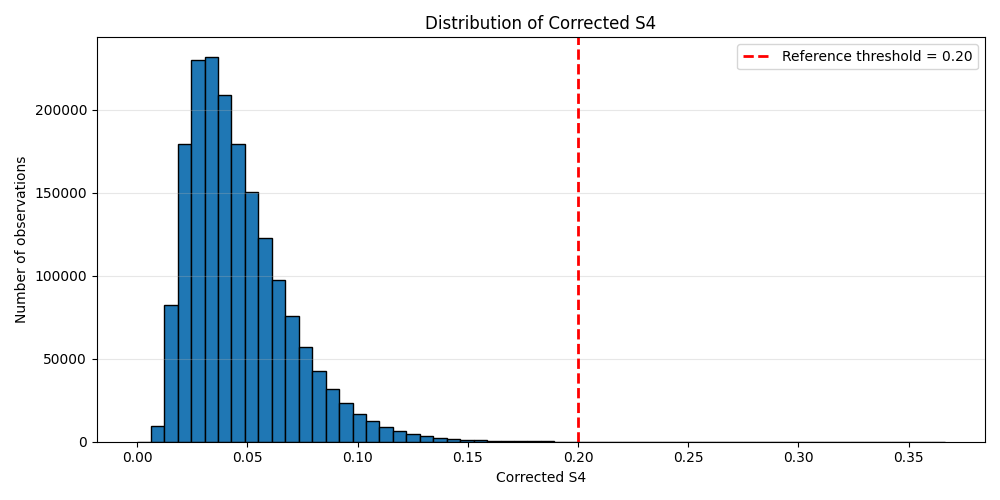

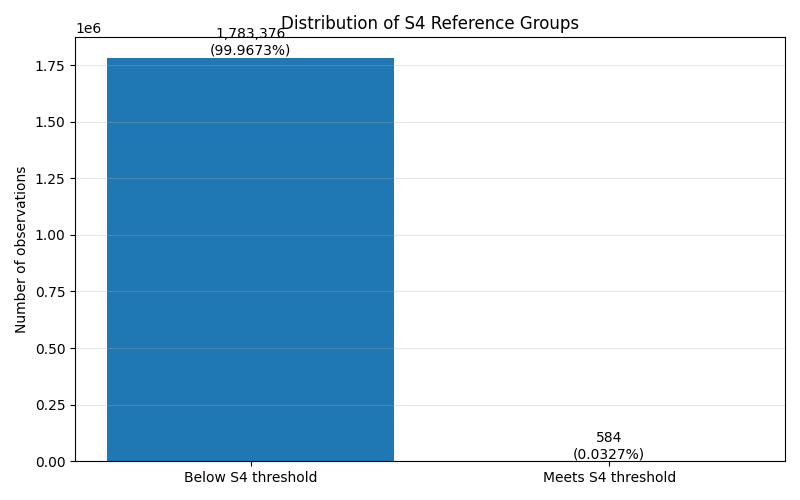

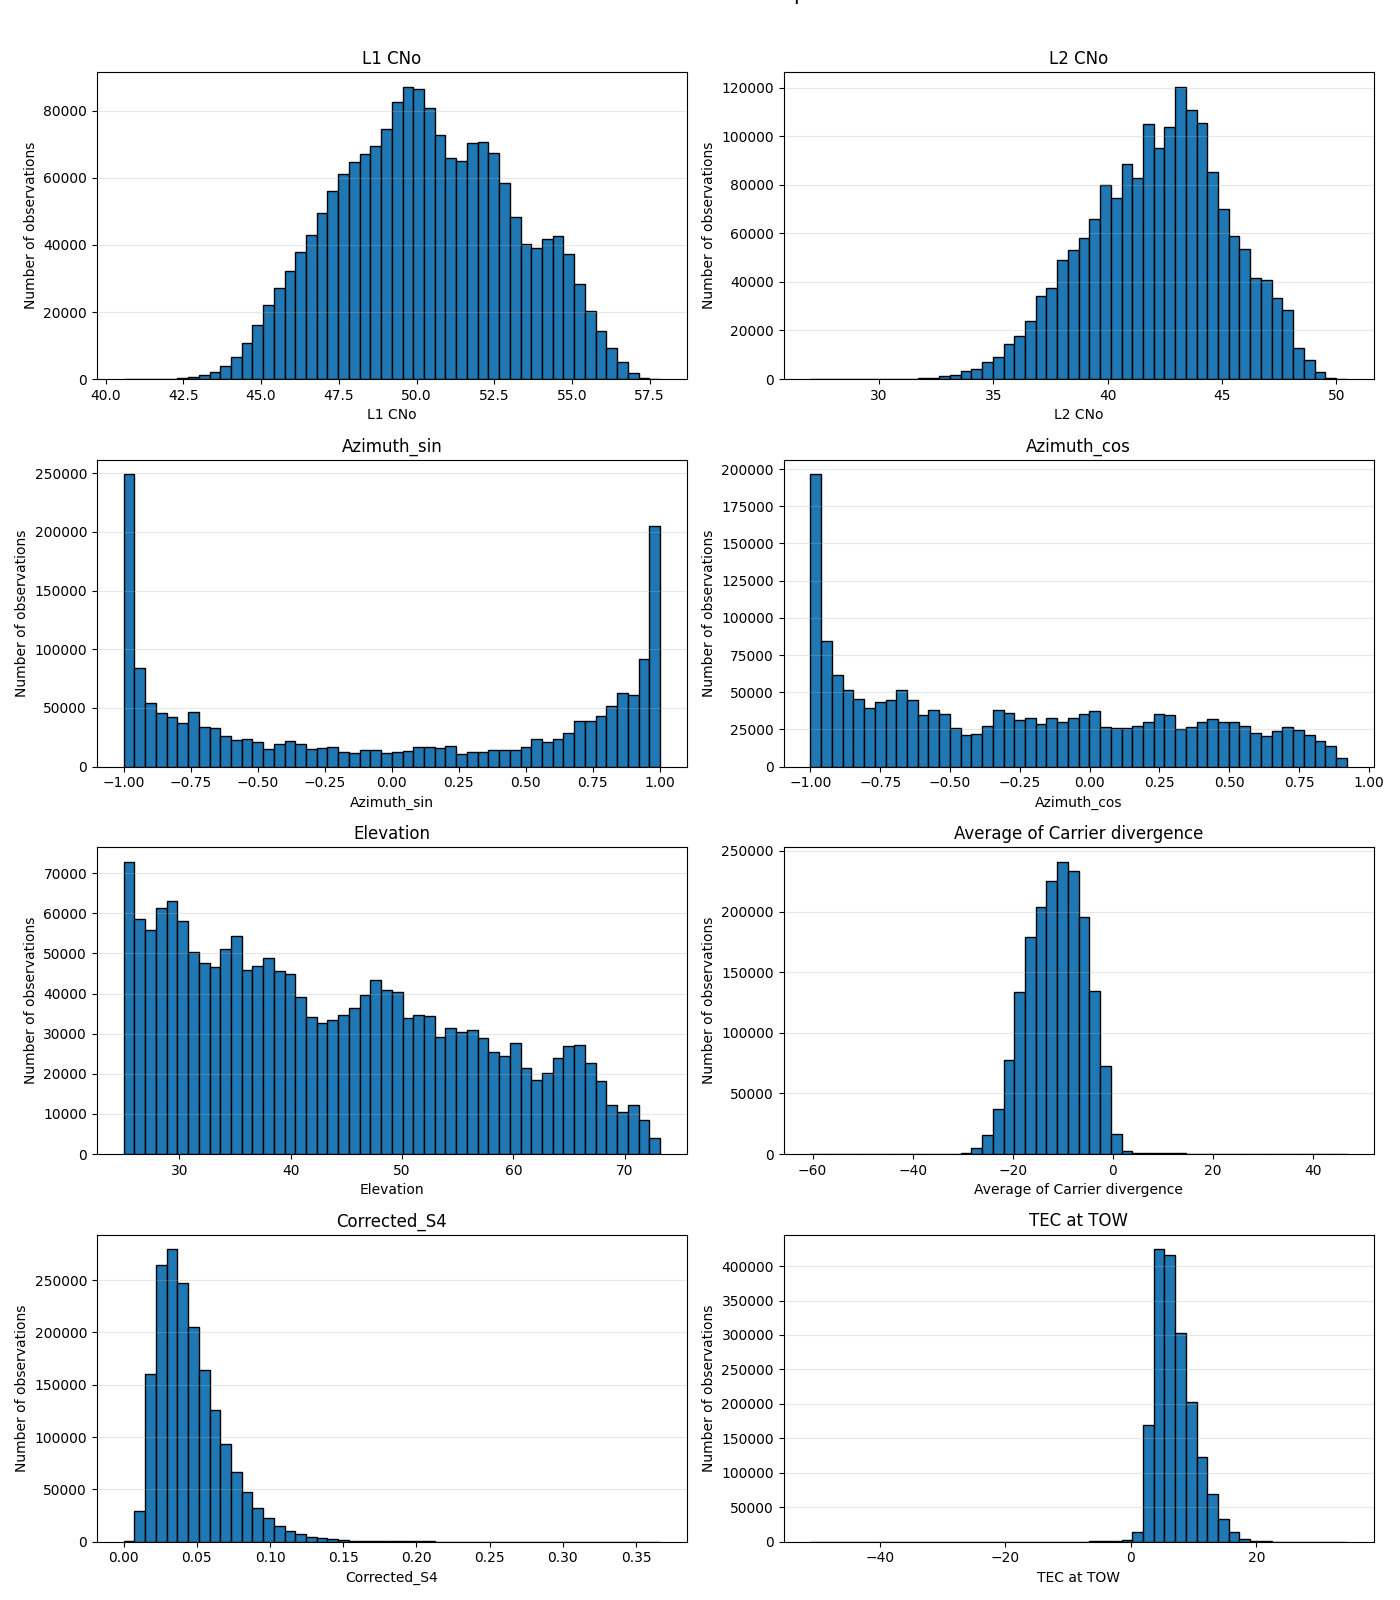

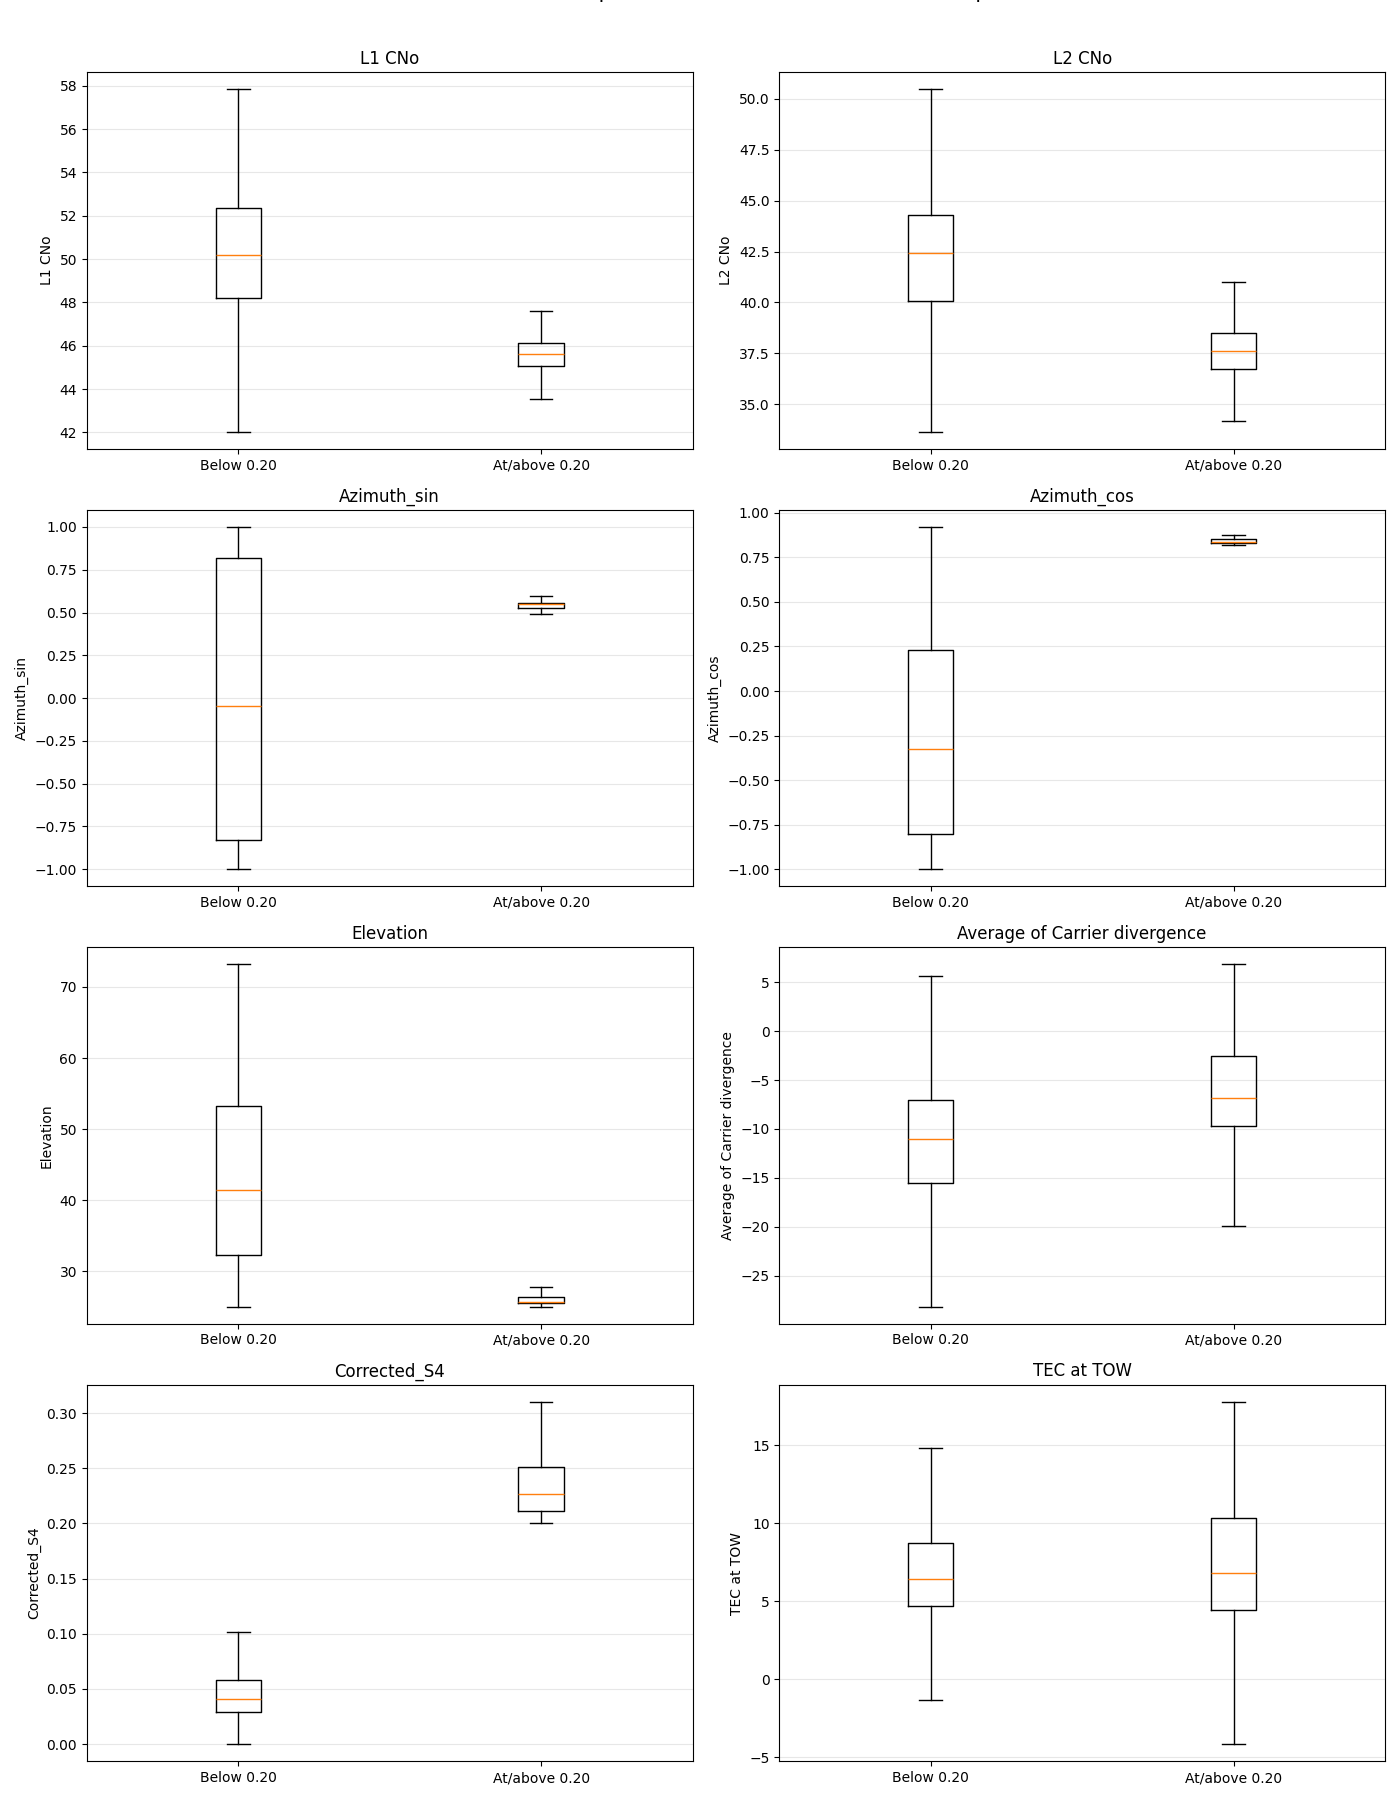

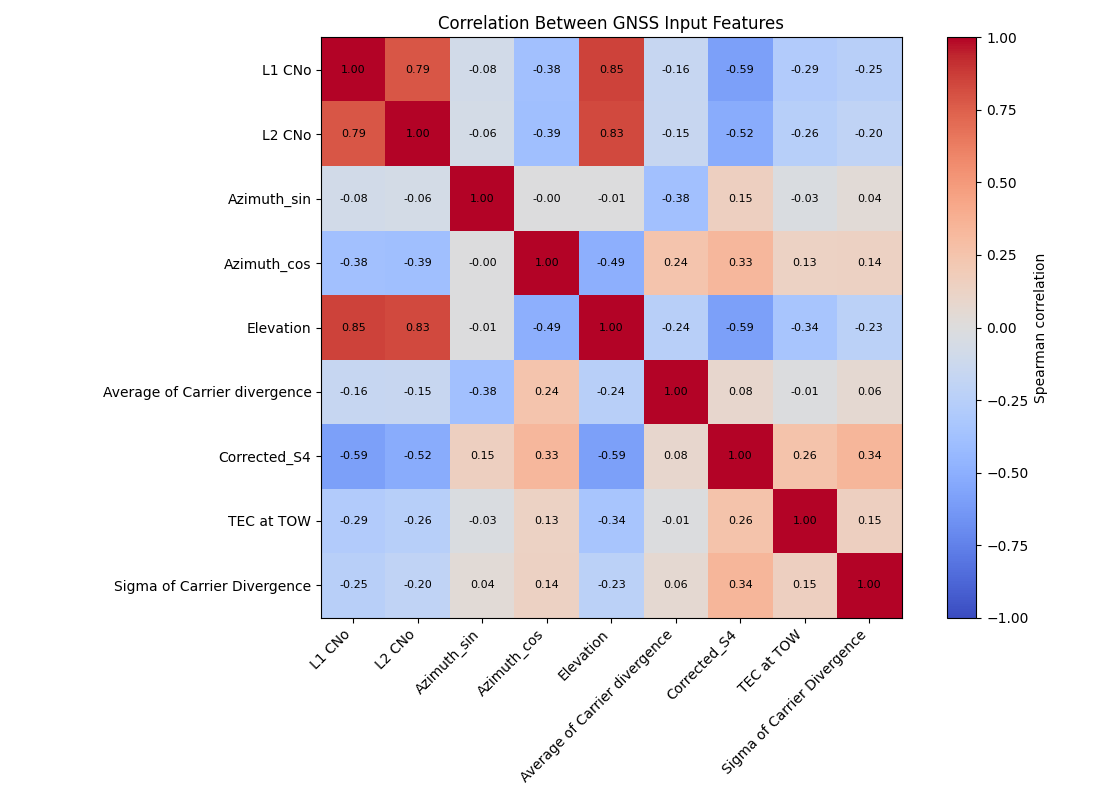

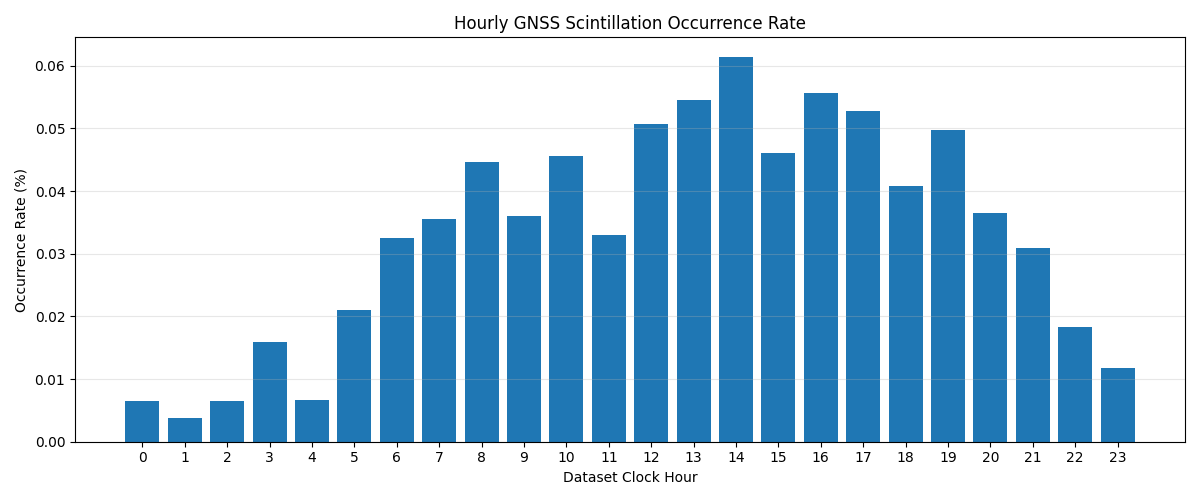

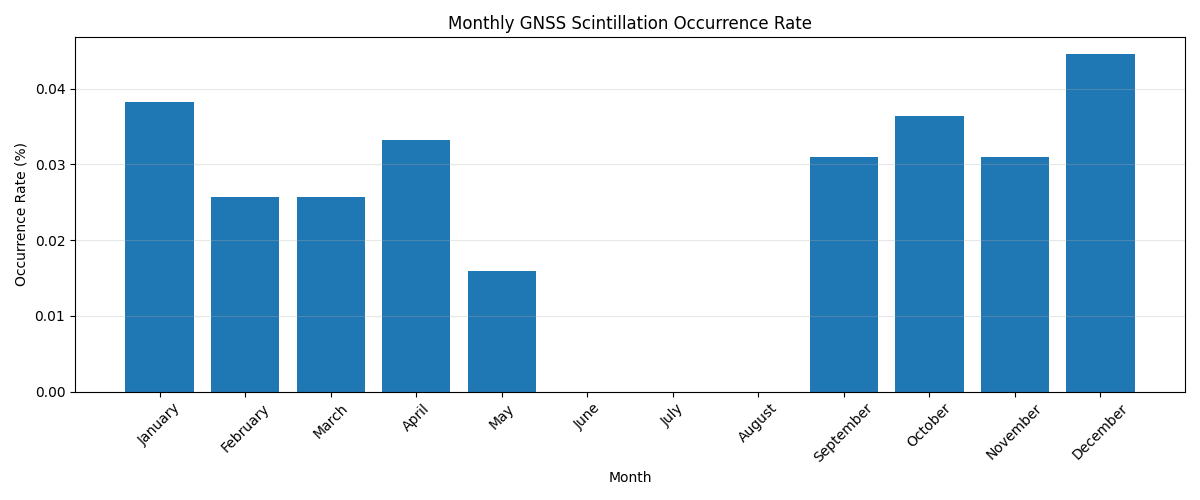

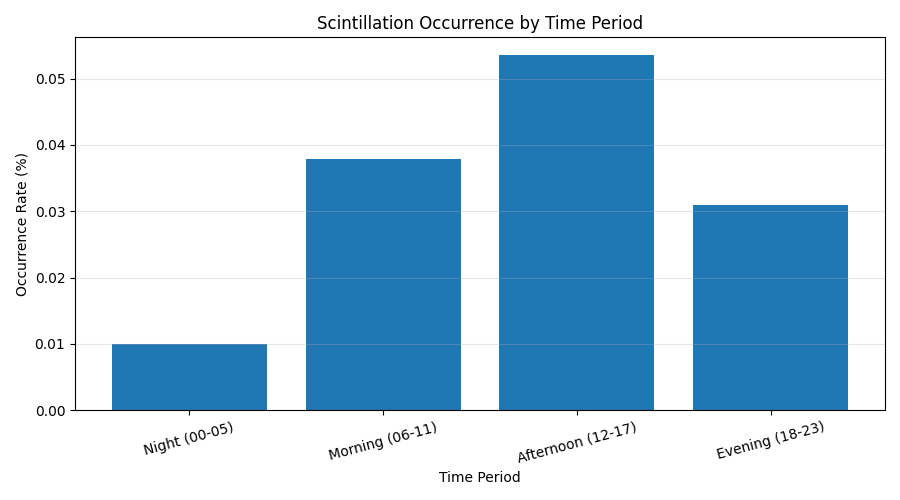

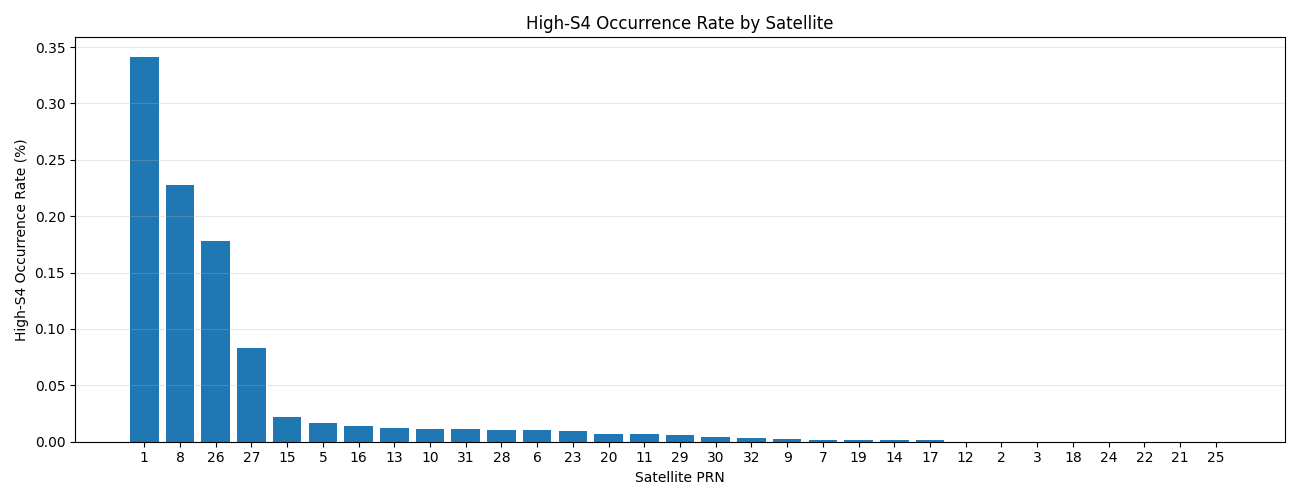

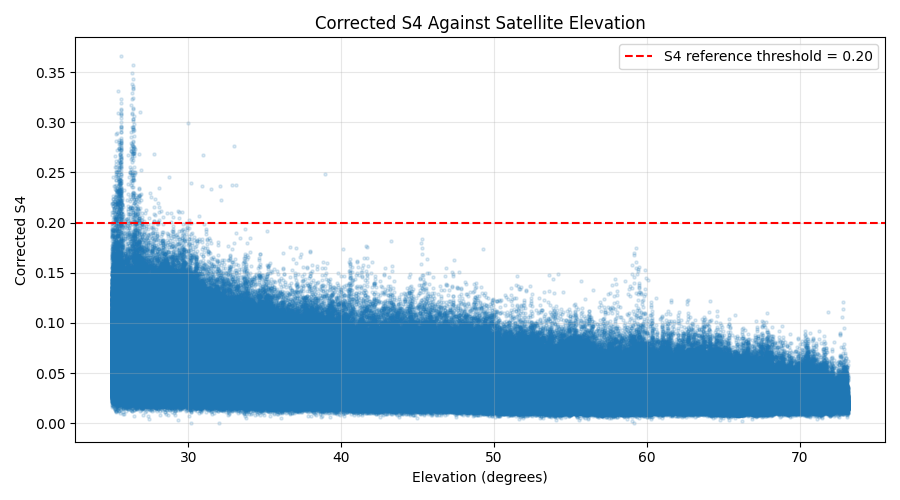

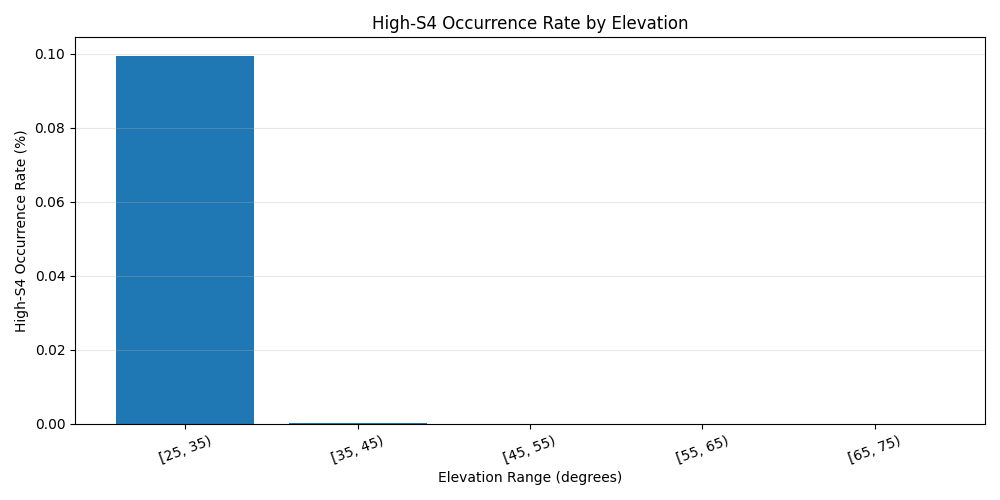

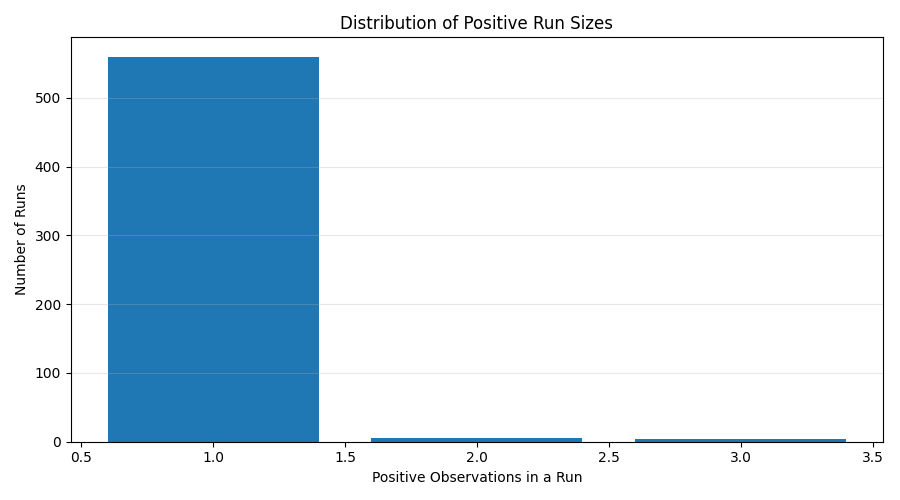

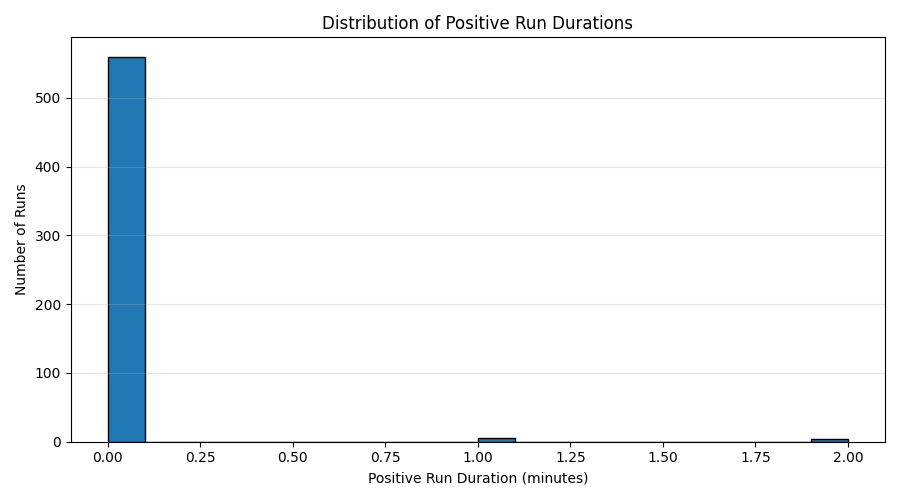

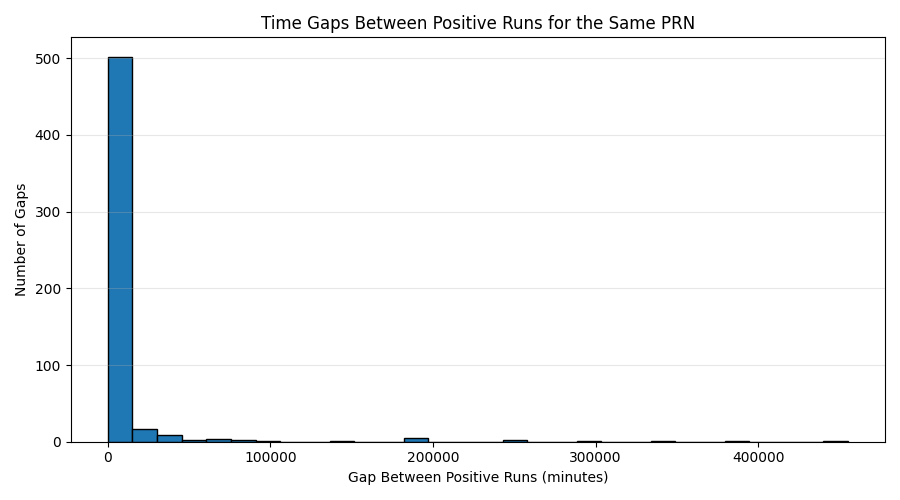

In [4]:
# ============================================================
# 3.1 OVERALL CORRECTED S4 DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("3.1 CORRECTED S4 DISTRIBUTION")
print("=" * 60)

print(df_clean["Corrected_S4"].describe())

plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["Corrected_S4"],
    bins=60,
    edgecolor="black"
)

plt.axvline(
    0.20,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Reference threshold = 0.20"
)

plt.xlabel("Corrected S4")
plt.ylabel("Number of observations")
plt.title("Distribution of Corrected S4")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3.2 CLASS IMBALANCE AND SCINTILLATION OCCURRENCE
# ============================================================

print("\n" + "=" * 60)
print("3.2 CLASS DISTRIBUTION")
print("=" * 60)

class_counts = (
    df_clean["LABEL"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

class_percentages = (
    df_clean["LABEL"]
    .value_counts(normalize=True)
    .reindex([0, 1], fill_value=0) * 100
)

class_summary = pd.DataFrame({
    "Reference group": [
        "Below S4 threshold",
        "Meets S4 threshold"
    ],
    "Observations": class_counts.values,
    "Percentage (%)": class_percentages.values
})

print(class_summary.to_string(index=False))

# Plot class distribution

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Below S4 threshold", "Meets S4 threshold"],
    class_counts.values
)

for bar, percentage in zip(bars, class_percentages.values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}\n({percentage:.4f}%)",
        ha="center",
        va="bottom"
    )

plt.ylabel("Number of observations")
plt.title("Distribution of S4 Reference Groups")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3.3 DISTRIBUTION OF THE EIGHT MODEL INPUT FEATURES
# ============================================================

print("\n" + "=" * 60)
print("3.3 FEATURE DISTRIBUTIONS")
print("=" * 60)

# Summary statistics

feature_summary = df_clean[FEATURES].describe().T

feature_summary["Median"] = df_clean[FEATURES].median()

feature_summary = feature_summary[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "Median",
        "50%",
        "75%",
        "max"
    ]
]

print("\nFEATURE SUMMARY STATISTICS")

display(feature_summary.round(4))


# ------------------------------------------------------------
# HISTOGRAMS FOR ALL EIGHT FEATURES
# ------------------------------------------------------------

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for feature, ax in zip(FEATURES, axes.flatten()):

    values = df_clean[feature].dropna()

    ax.hist(
        values,
        bins=50,
        edgecolor="black"
    )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of observations")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Distributions of GNSS Model Input Features",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

# ============================================================
# 3.4 FEATURE COMPARISON BETWEEN S4 REFERENCE GROUPS
# ============================================================

print("\n" + "=" * 60)
print("3.4 LOW-S4 VS HIGH-S4 FEATURE COMPARISON")
print("=" * 60)

# ------------------------------------------------------------
# SUMMARY STATISTICS BY REFERENCE GROUP
# ------------------------------------------------------------

group_summary = (
    df_clean
    .groupby("LABEL")[FEATURES]
    .agg(["mean", "median", "std"])
)

print("\nFEATURE STATISTICS BY S4 REFERENCE GROUP")

display(group_summary.round(4))


# ------------------------------------------------------------
# BOXPLOTS FOR ALL EIGHT FEATURES
# ------------------------------------------------------------

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for feature, ax in zip(FEATURES, axes.flatten()):

    group_0 = df_clean.loc[
        df_clean["LABEL"] == 0, feature
    ].dropna()

    group_1 = df_clean.loc[
        df_clean["LABEL"] == 1, feature
    ].dropna()

    ax.boxplot(
        [group_0, group_1],
        tick_labels=[
            "Below 0.20",
            "At/above 0.20"
        ],
        showfliers=False
    )

    ax.set_title(feature)
    ax.set_ylabel(feature)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "GNSS Feature Comparison Between S4 Reference Groups",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

# ============================================================
# 3.5 CORRELATION ANALYSIS OF MODEL INPUT FEATURES
# ============================================================

print("\n" + "=" * 60)
print("3.5 FEATURE CORRELATION ANALYSIS")
print("=" * 60)

# Spearman correlation is used because some GNSS features
# may have skewed distributions and nonlinear monotonic relationships.

correlation_matrix = df_clean[FEATURES].corr(
    method="spearman"
)

print("\nSPEARMAN CORRELATION MATRIX")

display(correlation_matrix.round(3))


# ------------------------------------------------------------
# CORRELATION HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(11, 8))

image = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(
    image,
    label="Spearman correlation"
)

plt.xticks(
    range(len(FEATURES)),
    FEATURES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(FEATURES)),
    FEATURES
)

for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):

        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title("Correlation Between GNSS Input Features")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# IDENTIFY HIGHLY CORRELATED FEATURE PAIRS
# ------------------------------------------------------------

correlation_pairs = []

for i in range(len(FEATURES)):

    for j in range(i + 1, len(FEATURES)):

        value = correlation_matrix.iloc[i, j]

        if abs(value) >= 0.70:

            correlation_pairs.append({
                "Feature 1": FEATURES[i],
                "Feature 2": FEATURES[j],
                "Spearman correlation": value
            })

print("\nFEATURE PAIRS WITH ABSOLUTE CORRELATION >= 0.70")

if correlation_pairs:

    display(pd.DataFrame(correlation_pairs))

else:

    print("No feature pairs exceed the selected 0.70 threshold.")

# ============================================================
# 3.6 TEMPORAL SCINTILLATION OCCURRENCE ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("3.6 TEMPORAL OCCURRENCE ANALYSIS")
print("=" * 60)

# Use the existing _DATE column.
# Second contains seconds since midnight.

df_clean["Hour"] = (
    df_clean["Second"] // 3600
).astype(int)

df_clean["Month"] = df_clean["_DATE"].dt.month

# ------------------------------------------------------------
# 3.6.1 HOURLY OCCURRENCE RATE
# ------------------------------------------------------------

hourly_results = (
    df_clean.groupby("Hour")
    .agg(
        Total_Observations=("LABEL", "count"),
        Scintillation_Observations=("LABEL", "sum")
    )
    .reindex(range(24), fill_value=0)
    .reset_index()
)

hourly_results["Occurrence_Rate (%)"] = (
    hourly_results["Scintillation_Observations"] /
    hourly_results["Total_Observations"].replace(0, np.nan)
) * 100

print("\nHOURLY OCCURRENCE RATE")

display(hourly_results.round(4))

plt.figure(figsize=(12, 5))

plt.bar(
    hourly_results["Hour"],
    hourly_results["Occurrence_Rate (%)"]
)

plt.xticks(range(24))
plt.xlabel("Dataset Clock Hour")
plt.ylabel("Occurrence Rate (%)")
plt.title("Hourly GNSS Scintillation Occurrence Rate")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.6.2 MONTHLY OCCURRENCE RATE
# ------------------------------------------------------------

monthly_results = (
    df_clean.groupby("Month")
    .agg(
        Total_Observations=("LABEL", "count"),
        Scintillation_Observations=("LABEL", "sum")
    )
    .reindex(range(1, 13))
    .reset_index()
)

# Months without observations remain NaN, not zero.

monthly_results["Occurrence_Rate (%)"] = (
    monthly_results["Scintillation_Observations"] /
    monthly_results["Total_Observations"]
) * 100

monthly_results["Month_Name"] = pd.to_datetime(
    monthly_results["Month"],
    format="%m"
).dt.strftime("%B")

print("\nMONTHLY OCCURRENCE RATE")

display(monthly_results.round(4))

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_results["Month_Name"],
    monthly_results["Occurrence_Rate (%)"]
)

plt.xlabel("Month")
plt.ylabel("Occurrence Rate (%)")
plt.title("Monthly GNSS Scintillation Occurrence Rate")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.6.3 OCCURRENCE RATE BY TIME PERIOD
# ------------------------------------------------------------

df_clean["Time_Period"] = pd.cut(
    df_clean["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=[
        "Night (00-05)",
        "Morning (06-11)",
        "Afternoon (12-17)",
        "Evening (18-23)"
    ]
)

period_results = (
    df_clean.groupby("Time_Period", observed=False)
    .agg(
        Total_Observations=("LABEL", "count"),
        Scintillation_Observations=("LABEL", "sum")
    )
    .reset_index()
)

period_results["Occurrence_Rate (%)"] = (
    period_results["Scintillation_Observations"] /
    period_results["Total_Observations"].replace(0, np.nan)
) * 100

print("\nOCCURRENCE RATE BY TIME PERIOD")

display(period_results.round(4))

plt.figure(figsize=(9, 5))

plt.bar(
    period_results["Time_Period"].astype(str),
    period_results["Occurrence_Rate (%)"]
)

plt.xlabel("Time Period")
plt.ylabel("Occurrence Rate (%)")
plt.title("Scintillation Occurrence by Time Period")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.6.4 IDENTIFY HIGHEST OCCURRENCE RATES
# ------------------------------------------------------------

highest_hour = hourly_results.loc[
    hourly_results["Occurrence_Rate (%)"].idxmax()
]

valid_months = monthly_results.dropna(
    subset=["Occurrence_Rate (%)"]
)

highest_month = valid_months.loc[
    valid_months["Occurrence_Rate (%)"].idxmax()
]

highest_period = period_results.loc[
    period_results["Occurrence_Rate (%)"].idxmax()
]

print("\nHIGHEST OCCURRENCE RATES")

print(
    f"Hour: {int(highest_hour['Hour']):02d}:00 "
    f"({highest_hour['Occurrence_Rate (%)']:.4f}%)"
)

print(
    f"Month: {highest_month['Month_Name']} "
    f"({highest_month['Occurrence_Rate (%)']:.4f}%)"
)

print(
    f"Time period: {highest_period['Time_Period']} "
    f"({highest_period['Occurrence_Rate (%)']:.4f}%)"
)

print(
    "\nIMPORTANT: Months without observations are missing coverage, "
    "not months with zero scintillation."
)

print(
    "Time values represent dataset clock time; "
    "do not call them local time or UT unless the timezone is confirmed."
)

# ============================================================
# 3.7 SATELLITE AND ELEVATION ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("3.7 SATELLITE AND ELEVATION ANALYSIS")
print("=" * 60)


# ------------------------------------------------------------
# 3.7.1 OBSERVATION COUNTS AND OCCURRENCE RATE BY PRN
# ------------------------------------------------------------

prn_results = (
    df_clean.groupby("PRN")
    .agg(
        Total_Observations=("LABEL", "count"),
        High_S4_Observations=("LABEL", "sum")
    )
)

prn_results["Occurrence_Rate (%)"] = (
    prn_results["High_S4_Observations"] /
    prn_results["Total_Observations"]
) * 100

prn_results = prn_results.sort_values(
    "Occurrence_Rate (%)",
    ascending=False
)

print("\nOCCURRENCE RATE BY SATELLITE PRN")

display(prn_results.round(4))


# Plot occurrence rate by PRN

plt.figure(figsize=(13, 5))

plt.bar(
    prn_results.index.astype(str),
    prn_results["Occurrence_Rate (%)"]
)

plt.xlabel("Satellite PRN")
plt.ylabel("High-S4 Occurrence Rate (%)")
plt.title("High-S4 Occurrence Rate by Satellite")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.7.2 CORRECTED S4 AGAINST ELEVATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean["Elevation"],
    df_clean["Corrected_S4"],
    alpha=0.15,
    s=5
)

plt.axhline(
    0.20,
    color="red",
    linestyle="--",
    label="S4 reference threshold = 0.20"
)

plt.xlabel("Elevation (degrees)")
plt.ylabel("Corrected S4")
plt.title("Corrected S4 Against Satellite Elevation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.7.3 HIGH-S4 OCCURRENCE BY ELEVATION RANGE
# ------------------------------------------------------------

elevation_bins = [25, 35, 45, 55, 65, 75, 90]

df_clean["Elevation_Group"] = pd.cut(
    df_clean["Elevation"],
    bins=elevation_bins,
    right=False,
    include_lowest=True
)

elevation_results = (
    df_clean.groupby("Elevation_Group", observed=False)
    .agg(
        Total_Observations=("LABEL", "count"),
        High_S4_Observations=("LABEL", "sum")
    )
    .reset_index()
)

elevation_results["Occurrence_Rate (%)"] = (
    elevation_results["High_S4_Observations"] /
    elevation_results["Total_Observations"].replace(0, np.nan)
) * 100

print("\nHIGH-S4 OCCURRENCE BY ELEVATION RANGE")

display(elevation_results.round(4))


# Plot occurrence rate by elevation group

plt.figure(figsize=(10, 5))

plt.bar(
    elevation_results["Elevation_Group"].astype(str),
    elevation_results["Occurrence_Rate (%)"]
)

plt.xlabel("Elevation Range (degrees)")
plt.ylabel("High-S4 Occurrence Rate (%)")
plt.title("High-S4 Occurrence Rate by Elevation")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3.8 TEMPORAL CLUSTERING AND POSITIVE RUN ANALYSIS
#
# Positive run definition:
# 1. Same satellite PRN
# 2. Consecutive LABEL = 1 observations
# 3. Exactly 60 seconds between observations
#
# A positive run is a computational grouping, not necessarily
# an independent physical scintillation event.
# ============================================================

print("\n" + "=" * 60)
print("3.8 TEMPORAL CLUSTERING AND EVENT BEHAVIOUR")
print("=" * 60)


# ------------------------------------------------------------
# 3.8.1 CREATE TIMESTAMP
# ------------------------------------------------------------

# Use the existing date and seconds since midnight.

df_clean["Timestamp"] = (
    df_clean["_DATE"] +
    pd.to_timedelta(df_clean["Second"], unit="s")
)

# Sort observations separately by satellite and time.

df_clean.sort_values(
    ["PRN", "Timestamp"],
    inplace=True
)


# ------------------------------------------------------------
# 3.8.2 IDENTIFY CONSECUTIVE POSITIVE RUNS
# ------------------------------------------------------------

# Previous observation for the same satellite.

previous_label = (
    df_clean.groupby("PRN")["LABEL"].shift()
)

time_gap = (
    df_clean.groupby("PRN")["Timestamp"].diff()
)

# A new run begins when:
# - Current observation is positive, AND
# - Previous observation was not positive, OR
# - Time gap is not exactly 60 seconds.

event_start = (
    (df_clean["LABEL"] == 1) &
    (
        (previous_label != 1) |
        (time_gap != pd.Timedelta(seconds=60))
    )
)

# Number each positive run separately for each PRN.

event_number = (
    event_start.groupby(df_clean["PRN"]).cumsum()
)

# Assign IDs only to positive observations.

df_clean["Event_ID"] = np.where(
    df_clean["LABEL"] == 1,
    (
        df_clean["PRN"].astype(str) +
        "_" +
        event_number.astype(str)
    ),
    None
)


# ------------------------------------------------------------
# 3.8.3 SUMMARISE ALL POSITIVE RUNS
# ------------------------------------------------------------

positive_runs = (
    df_clean[df_clean["LABEL"] == 1]
    .groupby("Event_ID")
    .agg(
        PRN=("PRN", "first"),
        Start_Time=("Timestamp", "min"),
        End_Time=("Timestamp", "max"),
        Number_of_Observations=("LABEL", "count"),
        Mean_Corrected_S4=("Corrected_S4", "mean"),
        Maximum_Corrected_S4=("Corrected_S4", "max")
    )
    .reset_index()
)

# Calculate actual elapsed duration.

positive_runs["Duration_Minutes"] = (
    positive_runs["End_Time"] -
    positive_runs["Start_Time"]
).dt.total_seconds() / 60

# Sort events.

positive_runs.sort_values(
    ["PRN", "Start_Time"],
    inplace=True
)

print("\nPOSITIVE RUN SUMMARY")

print("Total positive observations:", int(df_clean["LABEL"].sum()))

print("Total computationally grouped positive runs:",
      len(positive_runs))

print(
    "Positive observations accounted for:",
    positive_runs["Number_of_Observations"].sum()
)

print("\nPositive run duration statistics:")

display(
    positive_runs["Duration_Minutes"].describe()
)


# ------------------------------------------------------------
# 3.8.4 DISTRIBUTION OF OBSERVATIONS PER POSITIVE RUN
# ------------------------------------------------------------

run_size_distribution = (
    positive_runs["Number_of_Observations"]
    .value_counts()
    .sort_index()
    .reset_index()
)

run_size_distribution.columns = [
    "Positive_Observations_Per_Run",
    "Number_of_Runs"
]

print("\nNUMBER OF POSITIVE OBSERVATIONS PER RUN")

display(run_size_distribution)


plt.figure(figsize=(9, 5))

plt.bar(
    run_size_distribution["Positive_Observations_Per_Run"],
    run_size_distribution["Number_of_Runs"]
)

plt.xlabel("Positive Observations in a Run")
plt.ylabel("Number of Runs")
plt.title("Distribution of Positive Run Sizes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.8.5 POSITIVE RUN DURATION DISTRIBUTION
# ------------------------------------------------------------

duration_distribution = (
    positive_runs["Duration_Minutes"]
    .value_counts()
    .sort_index()
    .reset_index()
)

duration_distribution.columns = [
    "Duration_Minutes",
    "Number_of_Runs"
]

print("\nPOSITIVE RUN DURATION DISTRIBUTION")

display(duration_distribution)


plt.figure(figsize=(9, 5))

plt.hist(
    positive_runs["Duration_Minutes"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Positive Run Duration (minutes)")
plt.ylabel("Number of Runs")
plt.title("Distribution of Positive Run Durations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.8.6 TIME GAPS BETWEEN POSITIVE RUNS
# ------------------------------------------------------------

# Calculate the gap from the previous positive run's end
# to the next positive run's start, for the same PRN.

positive_runs["Previous_Run_End"] = (
    positive_runs.groupby("PRN")["End_Time"].shift()
)

positive_runs["Gap_From_Previous_Run_Minutes"] = (
    positive_runs["Start_Time"] -
    positive_runs["Previous_Run_End"]
).dt.total_seconds() / 60

run_gaps = positive_runs[
    "Gap_From_Previous_Run_Minutes"
].dropna()

print("\nTIME GAPS BETWEEN POSITIVE RUNS")

display(run_gaps.describe())

plt.figure(figsize=(9, 5))

plt.hist(
    run_gaps,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Gap Between Positive Runs (minutes)")
plt.ylabel("Number of Gaps")
plt.title("Time Gaps Between Positive Runs for the Same PRN")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.8.7 RUNS LASTING AT LEAST TWO MINUTES
# ------------------------------------------------------------

MIN_EVENT_DURATION = 2

event_results = positive_runs[
    positive_runs["Duration_Minutes"] >= MIN_EVENT_DURATION
].copy()

print("\nPOSITIVE RUNS LASTING AT LEAST TWO MINUTES")

print("Total positive runs:", len(positive_runs))

print("Runs lasting at least two minutes:", len(event_results))

print(
    "Positive observations contained in these runs:",
    event_results["Number_of_Observations"].sum()
)

display(event_results.head(20))


# ------------------------------------------------------------
# 3.8.8 SUMMARY OF POSITIVE RUNS
# ------------------------------------------------------------

print("\nFINAL POSITIVE RUN SUMMARY")

print("Total high-S4 observations:",
      int(df_clean["LABEL"].sum()))

print("Total positive runs:",
      len(positive_runs))

print(
    "Single-observation runs:",
    (positive_runs["Number_of_Observations"] == 1).sum()
)

print(
    "Runs lasting at least two minutes:",
    len(event_results)
)

print(
    "Maximum run duration (minutes):",
    positive_runs["Duration_Minutes"].max()
)

print(
    "\nNOTE: These runs are defined using the selected "
    "one-minute continuity rule. They should not automatically "
    "be interpreted as independent physical scintillation events."
)

# 4. Study III — one-class classifier ensembles

**Source:** Tsai & Lin (2021), *Feature Selection and Ensemble Learning Techniques in One-Class Classifiers*, DOI [10.1109/ACCESS.2021.3051969](https://doi.org/10.1109/ACCESS.2021.3051969), Sections III–IV and Tables 1, 2, 6, 7.

This implementation focuses on **C. THE THIRD EXPERIMENTAL STUDY** (Section III-C). The base OCCs and feature-selection variants from III-A/B are implemented as the prerequisites needed to build its twelve-member pool, rather than as separate research objectives. The explicitly approved GNSS adaptations are documented below. It is **not an exact replication** of all 55 benchmark datasets.

| Step | Paper | This notebook |
|---|---|---|
| Evaluation | 5-fold 80/20 CV | Five expanding folds grouped by complete dates within the existing training+validation period; preserve the final chronological holdout |
| Model fitting | Majority class only | Class 0 only; at most 5,000 rows, sampled proportionally across training dates |
| Base models | LOF: k=10/Euclidean; OCSVM: RBF, nu=0.5, gamma=1/d; IF: 100 trees, max_samples=100, contamination=0.5 | Same published settings; seeded reproducibility and novelty scoring for unseen data |
| PCA | Retain 80% variance | PCA of the other predictors plus a mandatory explicit Corrected_S4 channel |
| GA | DEAP, 5 generations, population 10, crossover .9, mutation .01, logistic-regression fitness | Same rates; mandatory S4; three-fold pseudo-class accuracy, then fewer columns as a tie-break |
| Pseudo-classes | K-means with 10/50/100 clusters of normal data | Fit separately inside each training fold; select K using development CV ROC-AUC |
| Embedded selection | C4.5 variables | Weka J48 3.8.6 (genuine C4.5 family), confidence .25/minimum leaf 2; force S4 into the result |
| Ensembles | Normalized-score averaging, normal at mean normality >=.5 | 33 homogeneous +19 heterogeneous ensembles and the paper-reported trio as one extra comparison |
| Supervised baselines | C4.5 and SMOTE+C4.5 use both classes | Omitted under the user's normal-only training requirement |


## Study III execution steps

1. Preserve preparation and EDA; reserve the existing final chronological period.
2. Build five expanding, date-grouped development folds. Sample at most 5,000 class-0 fitting rows across each fold's training dates.
3. Refit imputation/scaling using those normal rows. Keep an explicit Corrected_S4 predictor in every representation.
4. Construct BASE and PCA variants. For GA and C4.5 selection, cluster normal training data with K-means K=10,50,100 to obtain pseudo-classes.
5. Fit LOF, OCSVM and Isolation Forest variants on seeded normal-data bootstrap samples; select the GA/C4.5 cluster setting for each algorithm by development CV ROC-AUC. This produces twelve final candidates.
6. Construct all 33 homogeneous combinations from Table 1 and all 19 heterogeneous combinations from Tables 2/6. Include the paper-reported trio as an explicitly supplementary fixed example.
7. Normalize component scores with a common direction. As Eq. (1) specifies, use equal score averaging, not hard majority voting. Mean normality >=0.5 is normal; mean normality <0.5 is anomalous.
8. Freeze candidate/ensemble selections using development CV. Select the best single, homogeneous and heterogeneous families by CV AUC, never final-test performance.
9. Refit the selected twelve variants on class-0 development observations. Evaluate the frozen models on the final period.
10. Export **primary paper-0.5 results** and separately labelled supplementary CV-calibrated thresholds, metrics, detection identities, tables, and visual results.

The soft normalized-score average is the paper's stated voting rule. Its normalization formula and bagging resample details are not fully specified, so the implementation assumptions remain explicit. K-means supplies pseudo-labels only for feature selection; it does not replace the S4 event reference.

**Implementation choices the paper does not fully specify:** one seeded bootstrap per candidate, boundary-preserving arctan score normalization scaled on separate normal training-period observations, GA inner validation/tournament/elitism, and J48 pruning defaults. These choices and software hashes are exported in the run manifest. Normalized scores are not calibrated probabilities.

**Score interpretation:** LABEL is derived from Corrected_S4, which remains a predictor. A true positive therefore means a model detected an observation meeting the existing S4 reference, not an independently verified physical event. The S4 threshold rule agrees perfectly with the reference by construction and is kept separate from model ranking. The final period was evaluated in an earlier run; do not describe it as a newly untouched dataset.

All earlier preparation and EDA cells remain unchanged. The earlier global imputer/scaler outputs are **not** reused in CV; each fold refits preprocessing, pseudo-classes, selectors, score normalization, and models using its own normal training rows. No final-test score selects a model, feature subset, ensemble, or threshold. CV estimates used for selection are labelled development estimates.


**Ensemble diversity audit:** the paper's top-N cross-pool designs can select only variants of one base algorithm on a particular dataset. All 19 designs are retained, but the membership table records actual base algorithms. A same-algorithm top-N design is labelled separately and is excluded when selecting the genuinely heterogeneous family winner. This avoids presenting an OCSVM-only combination as a mixed-algorithm ensemble.

**Recovery of completed numerical folds:** an optional `Q4_CV_CACHE` can reuse already computed folds only after checking the data ZIP hash, unchanged preparation-source hash, numerical fitting code/settings/software fingerprint, every validation row/order, score validity, and all 120 recorded member fits. Ordinary runs compute fresh folds. Reuse after a reporting correction is recorded explicitly in the manifest; it does not introduce test-dependent model selection.

**Dependencies:** Python scientific stack (scikit-learn >=1.2), `deap==1.4.3`, optional `Jinja2` for LaTeX exports, and a Java JDK 11+ (including the compiler module). Install missing Python dependencies in your environment before running. Pinned public Weka/bounce jars are downloaded at first execution and hashed; no CART substitution is used. Set `Q4_PAPER_OUTPUT` to choose a result directory; generated data and jars must not be committed.

**Outputs:** full confusion counts, precision/recall/F1/F2, specificity/FPR/NPV, accuracy/balanced accuracy/MCC, ROC-AUC, average precision and trapezoidal PR-AUC; primary paper-0.5 and supplementary CV-calibrated operating points; frozen ensemble membership; selected features/PCA loadings; GA traces; date-block bootstrap intervals for count-derived metrics; observation identifiers/scores/TP-FP-FN lists; candidate consecutive runs; CSV/LaTeX tables; 300-dpi PNG/PDF figures; HTML report and result ZIP. Bootstrap intervals do not cover ROC/AP. PR plotting preserves every recall change while removing redundant points on constant-recall segments; metrics use all evaluated rows.


## 4.1 — Protocol, paper settings and reproducibility

Record the approved settings and validate the unchanged reference/features. Each fold will use fresh normal-only preprocessing. These configuration values are saved with software versions.


In [5]:
"""Tsai & Lin (2021), IEEE Access, DOI 10.1109/ACCESS.2021.3051969.

This is a documented adaptation, not an exact replication. Sections III-A/B/C
give the model/selector/ensemble settings. The user-approved adaptations are
date-grouped expanding five-fold evaluation, mandatory Corrected_S4, and a
5,000-normal-row fitting cap. Only the modelling cells are replaced.
"""
from pathlib import Path
from itertools import combinations
import hashlib
import importlib.metadata
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time
import types
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deap import base, creator, tools
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, roc_auc_score,
    roc_curve, auc,
)
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

SEED = 42
N_TIME_FOLDS = 5
MAX_NORMAL_ROWS = 5_000
NORMALIZATION_NORMAL_ROWS = 2_000
PSEUDO_K = (10, 50, 100)
GA_POPULATION = 10
GA_GENERATIONS = 5
GA_CROSSOVER = 0.90
GA_BIT_MUTATION = 0.01
RETAINED_VARIANCE = 0.80
BATCH_SIZE = 20_000
BOOTSTRAP_REPLICATES = 500
MANDATORY_FEATURE = "Corrected_S4"
ALGORITHMS = ("LOF", "OCSVM", "IFOREST")
VARIANTS = ("BASE", "PCA", "GA", "C45")
OUTPUT_DIR = Path(os.environ.get("Q4_PAPER_OUTPUT", "q4_paper_results"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for subfolder in ("figures", "tables", "scores", "selectors", "dependencies"):
    (OUTPUT_DIR / subfolder).mkdir(exist_ok=True)

# Retain the prepared candidate features, including S4. Never use the prior
# globally fitted imputer/scaler in time-series CV: each fold fits fresh ones.
PAPER_FEATURES = list(FEATURES)
if MANDATORY_FEATURE not in PAPER_FEATURES or "LABEL" in PAPER_FEATURES:
    raise ValueError("Corrected_S4 must be a predictor and LABEL must not be.")
if not df_clean.index.is_unique:
    raise ValueError("Unique row indices are required for score alignment.")
if not set(df_clean["LABEL"].unique()).issubset({0, 1}):
    raise ValueError("Expected the existing binary S4 reference labels.")
if not np.array_equal(
    df_clean["LABEL"].to_numpy(),
    (df_clean[MANDATORY_FEATURE].to_numpy() >= S4_THRESHOLD).astype(int),
):
    raise ValueError("Existing S4 measurement and reference labels disagree.")

# Methodological choices not fully specified by the paper are explicit:
# - numeric predictors are median-imputed and standardized on normal fit rows;
# - J48 3.8.6 is used as a genuine C4.5-family implementation (not CART);
# - GA fitness is 3-fold pseudo-class accuracy, then fewer columns as a tie-break;
# - one seeded bootstrap of the normal sample per candidate supplies bagging;
# - a boundary-preserving arctan maps scores monotonically into (0,1);
#   its scale uses separate normal training-period rows, never validation/test;
# - paper threshold 0.5 and CV-calibrated F1/F2/FPR operating points are distinct;
# - supervised C4.5/SMOTE baselines are omitted: the user requires class-0-only fit.
RUN_INFO = {
    "paper_doi": "10.1109/ACCESS.2021.3051969",
    "experimental_focus": "Section III-C / Study III: homogeneous and heterogeneous OCC ensembles",
    "primary_operating_point": "paper 0.5 normality rule; CV-calibrated points are supplementary",
    "protocol": "five expanding date-grouped folds; existing final holdout",
    "max_normal_fit_rows": MAX_NORMAL_ROWS,
    "normalization_normal_rows": NORMALIZATION_NORMAL_ROWS,
    "mandatory_predictor": MANDATORY_FEATURE,
    "features": PAPER_FEATURES,
    "seed": SEED,
    "versions": {package: importlib.metadata.version(package) for package in
                 ("numpy", "pandas", "scikit-learn", "matplotlib", "deap")},
    "reference": "LABEL = 1[Corrected_S4 >= existing S4_THRESHOLD]",
    "interpretation": "agreement with S4-derived reference, not independent event truth",
    "holdout_history": "this period was evaluated in the earlier unchanged run",
    "normalization": "0.5 + arctan((anomaly_score - native_boundary) / normal_IQR) / pi",
    "bagging": "one full-size seeded bootstrap per candidate; a stated assumption",
    "ga_fitness": "mean 3-fold pseudo-class accuracy; fewer features breaks ties",
    "c45": "Weka J48 3.8.6, confidence 0.25, minimum leaf size 2",
    "pca_adaptation": "explicit S4 channel plus 80%-variance PCA of other predictors",
    "not_included": "two-class supervised baselines and SMOTE, per normal-only requirement",
}
SELECTOR_RECORDS = []
GA_HISTORY = []
FIT_RECORDS = []
CV_FOLD_RECORDS = []

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=str), encoding="utf-8")

def save_records():
    write_json(OUTPUT_DIR / "run_manifest.json", RUN_INFO)
    for name, records in (
        ("feature_selection", SELECTOR_RECORDS), ("ga_history", GA_HISTORY),
        ("model_fits", FIT_RECORDS), ("time_folds", CV_FOLD_RECORDS),
    ):
        pd.DataFrame(records).to_csv(OUTPUT_DIR / "tables" / f"{name}.csv", index=False)

save_records()
print("Paper-based output directory:", OUTPUT_DIR.resolve())



Paper-based output directory: results/2019


## 4.2 — Genuine C4.5 feature selection and majority-only pseudo-classes

Section III-B: create pseudo-classes only from normal training rows. GA uses logistic pseudo-class accuracy; J48 selects its split variables. Corrected_S4 cannot be removed. Pseudo-class accuracy is not an anomaly-detection result.


In [6]:
def ensure_j48():
    """Download pinned public Weka jars and compile a small J48 graph adapter."""
    dependency_dir = OUTPUT_DIR / "dependencies"
    sources = {
        "weka-stable-3.8.6.jar": (
            "https://repo.maven.apache.org/maven2/nz/ac/waikato/cms/weka/"
            "weka-stable/3.8.6/weka-stable-3.8.6.jar"
        ),
        "bounce-0.18.jar": (
            "https://repo.maven.apache.org/maven2/nz/ac/waikato/cms/weka/"
            "thirdparty/bounce/0.18/bounce-0.18.jar"
        ),
    }
    if not shutil.which("java"):
        raise RuntimeError("Java JDK 11+ is required for genuine J48/C4.5 selection.")
    hashes = {}
    for filename, url in sources.items():
        target = dependency_dir / filename
        if not target.exists():
            print("Downloading pinned dependency:", filename, flush=True)
            with urllib.request.urlopen(url, timeout=60) as response:
                with target.open("wb") as destination:
                    shutil.copyfileobj(response, destination)
        hashes[filename] = {"url": url, "sha256": hashlib.sha256(target.read_bytes()).hexdigest()}
    source = dependency_dir / "Q4J48.java"
    java_source = '''import java.io.BufferedReader;
import java.io.FileReader;
import weka.core.Instances;
import weka.classifiers.trees.J48;
public class Q4J48 {
  public static void main(String[] args) throws Exception {
    Instances data = new Instances(new BufferedReader(new FileReader(args[0])));
    data.setClassIndex(data.numAttributes()-1);
    J48 tree = new J48();
    tree.setConfidenceFactor(0.25f);
    tree.setMinNumObj(2);
    tree.buildClassifier(data);
    System.out.println(tree.graph());
  }
}
'''
    classpath = os.pathsep.join(str((dependency_dir / name).resolve()) for name in sources)
    if (not source.exists() or source.read_text() != java_source
            or not (dependency_dir / "Q4J48.class").exists()):
        source.write_text(java_source, encoding="utf-8")
        compiler = (["javac"] if shutil.which("javac") else
                    ["java", "-m", "jdk.compiler/com.sun.tools.javac.Main"])
        subprocess.run(compiler + ["-cp", classpath, str(source.resolve())], check=True,
                       capture_output=True, text=True)
    RUN_INFO["weka_dependencies"] = hashes
    save_records()
    return os.pathsep.join([str(dependency_dir.resolve()), classpath])

def c45_columns(X, pseudo_labels, tag, seed, classpath):
    """Section III-B: retain variables used by a J48 tree of normal pseudo-classes."""
    arff = OUTPUT_DIR / "selectors" / f"{tag}.arff"
    with arff.open("w", encoding="utf-8") as stream:
        stream.write("@relation normal_pseudo_classes\n")
        for j in range(X.shape[1]):
            stream.write(f"@attribute x{j} numeric\n")
        classes = ",".join(f"c{j}" for j in np.unique(pseudo_labels))
        stream.write(f"@attribute pseudo_class {{{classes}}}\n@data\n")
        for row, label in zip(X, pseudo_labels):
            stream.write(",".join(format(value, ".17g") for value in row) + f",c{label}\n")
    result = subprocess.run(
        ["java", "-Xmx512m", "-cp", classpath, "Q4J48", str(arff.resolve()), str(seed)],
        capture_output=True, text=True,
    )
    if result.returncode:
        raise RuntimeError(f"J48/C4.5 failed: {result.stderr.strip()}")
    graph_start = result.stdout.find("digraph")
    if graph_start < 0:
        raise RuntimeError("J48 did not return a feature-selection graph.")
    graph = result.stdout[graph_start:]
    (OUTPUT_DIR / "selectors" / f"{tag}.dot").write_text(graph, encoding="utf-8")
    selected = {int(value) for value in re.findall(r'label="x(\d+)"', graph)}
    mandatory = PAPER_FEATURES.index(MANDATORY_FEATURE)
    forced = mandatory not in selected
    selected.add(mandatory)
    # Keep the generated graph and selection audit, not a redundant training-data file.
    arff.unlink()
    return sorted(selected), forced

def ga_columns(X, pseudo_labels, tag, seed):
    """Section III-B: DEAP GA on normal pseudo-classes; S4 cannot be switched off."""
    if not hasattr(creator, "Q4Fitness"):
        creator.create("Q4Fitness", base.Fitness, weights=(1.0, -1.0))
        creator.create("Q4FeatureMask", list, fitness=creator.Q4Fitness)
    random.seed(seed)
    mandatory = PAPER_FEATURES.index(MANDATORY_FEATURE)
    toolbox = base.Toolbox()
    cache = {}
    warning_count = 0
    def new_mask():
        mask = creator.Q4FeatureMask(random.randint(0, 1) for _ in range(X.shape[1]))
        mask[mandatory] = 1
        return mask
    def evaluate(mask):
        nonlocal warning_count
        mask[mandatory] = 1
        key = tuple(mask)
        if key not in cache:
            estimator = LogisticRegression(max_iter=300, solver="lbfgs", random_state=seed)
            # Inner pseudo-class CV is a feature-search heuristic, not an anomaly metric.
            inner = KFold(n_splits=3, shuffle=True, random_state=seed)
            with warnings.catch_warnings(record=True) as captured:
                warnings.simplefilter("always")
                accuracy = cross_val_score(estimator, X[:, np.flatnonzero(mask)],
                                           pseudo_labels, cv=inner,
                                           scoring="accuracy", error_score="raise").mean()
            warning_count += len(captured)
            cache[key] = (float(accuracy), int(sum(mask)))
        return cache[key]
    toolbox.register("individual", new_mask)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("evaluate", evaluate)
    toolbox.register("mate", tools.cxTwoPoint)
    toolbox.register("mutate", tools.mutFlipBit, indpb=GA_BIT_MUTATION)
    toolbox.register("select", tools.selTournament, tournsize=3)
    population = toolbox.population(n=GA_POPULATION)
    best = tools.HallOfFame(1)
    for generation in range(GA_GENERATIONS + 1):
        for individual in population:
            individual[mandatory] = 1
            if not individual.fitness.valid:
                individual.fitness.values = toolbox.evaluate(individual)
        best.update(population)
        GA_HISTORY.append({"selector": tag, "generation": generation,
                           "pseudo_class_accuracy": best[0].fitness.values[0],
                           "selected_count": int(sum(best[0])),
                           "evaluated_masks": len(cache),
                           "fit_warnings": warning_count})
        if generation == GA_GENERATIONS:
            break
        offspring = list(map(toolbox.clone, toolbox.select(population, GA_POPULATION)))
        for left, right in zip(offspring[::2], offspring[1::2]):
            if random.random() < GA_CROSSOVER:
                toolbox.mate(left, right)
                del left.fitness.values
                del right.fitness.values
        for child in offspring:
            toolbox.mutate(child)
            child[mandatory] = 1
            del child.fitness.values
        offspring[0] = toolbox.clone(best[0])  # Explicit elitism assumption.
        population = offspring
    return list(np.flatnonzero(best[0]))

def stratified_date_sample(frame, maximum, seed):
    """Sample class-0 rows proportionally by date, with largest-remainder allocation."""
    if not frame["LABEL"].eq(0).all():
        raise ValueError("Only normal/class-0 observations may enter fitting samples.")
    if len(frame) <= maximum:
        return frame.copy()
    groups = list(frame.groupby("_DATE", sort=True))
    exact = np.array([maximum * len(group) / len(frame) for _, group in groups])
    allocation = np.floor(exact).astype(int)
    for j in np.argsort(-(exact - allocation), kind="stable")[:maximum - allocation.sum()]:
        allocation[j] += 1
    rng = np.random.default_rng(seed)
    parts = [group.sample(n=int(number), random_state=int(rng.integers(2**31 - 1)))
             for (_, group), number in zip(groups, allocation) if number]
    return pd.concat(parts).sort_index()



## 4.3 — Fold-local preprocessing, mandatory S4 and one-class bagging

Section III-A and the bagging statement in III-C: bootstrap the normal sample, fit the published OCCs, and score only unseen rows. PCA preserves an explicit S4 channel. Estimate score normalization on separate normal training-period rows.


In [7]:
def make_representations(X, tag, seed, classpath, requested=None):
    """Fit selectors on normal rows; never inspect an evaluation period here."""
    mandatory = PAPER_FEATURES.index(MANDATORY_FEATURE)
    other = [j for j in range(X.shape[1]) if j != mandatory]
    representations = {"BASE": {"columns": list(range(X.shape[1]))}}
    # User-required adaptation: PCA acts on the other predictors, with an
    # explicit S4 channel retained. S4 is standardized, never projected away.
    if requested is None or "PCA" in requested:
        pca = PCA(n_components=RETAINED_VARIANCE, svd_solver="full")
        pca.fit(X[:, other])
        representations["PCA"] = {"pca": pca, "other": other, "mandatory": mandatory}
        loading_table = pd.DataFrame(pca.components_.T,
                                     index=[PAPER_FEATURES[j] for j in other],
                                     columns=[f"PC{j+1}" for j in range(pca.n_components_)])
        loading_table.to_csv(OUTPUT_DIR / "selectors" / f"{tag}_pca_loadings.csv")
        SELECTOR_RECORDS.append({"stage": tag, "representation": "PCA",
                                 "features": "Corrected_S4 + PCA(other predictors)",
                                 "retained_variance": float(pca.explained_variance_ratio_.sum()),
                                 "output_dimensions": 1 + pca.n_components_})
    for clusters in PSEUDO_K:
        methods = [method for method in ("GA", "C45")
                   if requested is None or f"{method}_K{clusters}" in requested]
        if not methods:
            continue
        if len(X) < clusters:
            raise ValueError("Normal sample is smaller than the requested pseudo-class count.")
        kmeans = KMeans(n_clusters=clusters, n_init=10, random_state=seed + clusters)
        pseudo = kmeans.fit_predict(X)
        pd.Series(pseudo).value_counts().sort_index().to_csv(
            OUTPUT_DIR / "selectors" / f"{tag}_k{clusters}_pseudo_sizes.csv")
        for method in methods:
            name = f"{method}_K{clusters}"
            print(f"{tag}: selecting {name} on {len(X):,} normal rows", flush=True)
            started = time.monotonic()
            forced = True
            if method == "GA":
                columns = ga_columns(X, pseudo, f"{tag}_{name}", seed + clusters)
            else:
                columns, forced = c45_columns(X, pseudo, f"{tag}_{name}", seed, classpath)
            if mandatory not in columns:
                raise AssertionError("A selector removed mandatory Corrected_S4.")
            representations[name] = {"columns": columns}
            SELECTOR_RECORDS.append({"stage": tag, "representation": name,
                                     "pseudo_classes": clusters,
                                     "features": json.dumps([PAPER_FEATURES[j] for j in columns]),
                                     "output_dimensions": len(columns),
                                     "s4_forced_when_not_used_by_tree": forced if method == "C45" else None,
                                     "seconds": time.monotonic() - started})
            save_records()
    return representations

def transform_representation(X, representation):
    if "pca" in representation:
        return np.column_stack((X[:, representation["mandatory"]],
                                representation["pca"].transform(X[:, representation["other"]])))
    return X[:, representation["columns"]]

def build_paper_model(algorithm, dimensions, seed):
    # Section III-A: fixed published settings, not the old notebook's grid.
    if algorithm == "LOF":
        return LocalOutlierFactor(n_neighbors=10, metric="euclidean",
                                  novelty=True, n_jobs=-1)
    if algorithm == "OCSVM":
        return OneClassSVM(kernel="rbf", nu=0.5, gamma=1.0 / dimensions)
    if algorithm == "IFOREST":
        return IsolationForest(n_estimators=100, max_samples=100,
                               contamination=0.5, random_state=seed, n_jobs=-1)
    raise ValueError(f"Unknown algorithm: {algorithm}")

def score_batches(model, X, algorithm):
    """Higher scores indicate anomalies; only score unseen observations."""
    scores = np.empty(len(X), dtype=float)
    for start in range(0, len(X), BATCH_SIZE):
        stop = min(start + BATCH_SIZE, len(X))
        if algorithm == "OCSVM":
            scores[start:stop] = -model.decision_function(X[start:stop]).ravel()
        else:
            scores[start:stop] = -model.score_samples(X[start:stop])
    if not np.isfinite(scores).all():
        raise ValueError("Non-finite anomaly scores encountered.")
    return scores

def normalize_scores(scores, center, scale):
    # The paper does not specify its [0,1] normalization formula. This explicit
    # implementation assumption preserves the native 0.5 decision boundary,
    # rank ordering, and score orientation without test-fitted min/max values.
    return 0.5 + np.arctan((scores - center) / scale) / np.pi

def fit_score_stage(training, evaluation, tag, seed, classpath, requested=None):
    """One fold or the final refit. No anomaly labels enter any model fit."""
    if training["_DATE"].max() >= evaluation["_DATE"].min():
        raise ValueError("Temporal ordering violated.")
    normals = training.loc[training["LABEL"].eq(0)]
    fitted_rows = stratified_date_sample(normals, MAX_NORMAL_ROWS, seed)
    remaining = normals.drop(index=fitted_rows.index)
    if remaining.empty:
        raise ValueError("Need separate normal rows to estimate score normalization.")
    calibration = stratified_date_sample(remaining, NORMALIZATION_NORMAL_ROWS, seed + 1)
    if not fitted_rows["LABEL"].eq(0).all() or not calibration["LABEL"].eq(0).all():
        raise AssertionError("Positive observations entered the one-class fitting path.")
    if set(fitted_rows.index) & set(calibration.index):
        raise AssertionError("LOF normalization sample overlaps fitted samples.")
    pd.DataFrame({"Original_Row_Index": fitted_rows.index}).to_csv(
        OUTPUT_DIR / "selectors" / f"{tag}_normal_fit_indices.csv", index=False)
    pd.DataFrame({"Original_Row_Index": calibration.index}).to_csv(
        OUTPUT_DIR / "selectors" / f"{tag}_normal_calibration_indices.csv", index=False)
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    scaler = StandardScaler()
    X_fit = scaler.fit_transform(imputer.fit_transform(fitted_rows[PAPER_FEATURES]))
    X_calibration = scaler.transform(imputer.transform(calibration[PAPER_FEATURES]))
    X_evaluation = scaler.transform(imputer.transform(evaluation[PAPER_FEATURES]))
    if not all(np.isfinite(X).all() for X in (X_fit, X_calibration, X_evaluation)):
        raise ValueError("Preprocessing produced non-finite inputs.")
    write_json(OUTPUT_DIR / "selectors" / f"{tag}_preprocessing.json", {
        "imputer_statistics": imputer.statistics_.tolist(),
        "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
        "all_missing_normal_features": fitted_rows[PAPER_FEATURES].isna().all().to_dict(),
    })
    required_representations = (None if requested is None else
                                {name.split("|")[1] for name in requested})
    representations = make_representations(X_fit, tag, seed, classpath, required_representations)
    scores = {}
    for number, (representation_name, representation) in enumerate(representations.items()):
        X_model = transform_representation(X_fit, representation)
        X_normalization = transform_representation(X_calibration, representation)
        X_query = transform_representation(X_evaluation, representation)
        for algorithm_number, algorithm in enumerate(ALGORITHMS):
            candidate = f"{algorithm}|{representation_name}"
            if requested is not None and candidate not in requested:
                continue
            model_seed = seed + 100 * number + algorithm_number
            rng = np.random.default_rng(model_seed)
            bootstrap = rng.integers(0, len(X_model), len(X_model))
            model = build_paper_model(algorithm, X_model.shape[1], model_seed)
            started = time.monotonic()
            print(f"{tag}: fitting {candidate} ({len(X_model):,} normal draws)", flush=True)
            model.fit(X_model[bootstrap])
            fit_seconds = time.monotonic() - started
            normal_scores = score_batches(model, X_normalization, algorithm)
            center = 0.0 if algorithm == "OCSVM" else -float(model.offset_)
            scale = float(np.quantile(normal_scores, .75) - np.quantile(normal_scores, .25))
            if scale <= np.finfo(float).eps:
                scale = max(float(np.std(normal_scores)), 1e-9)
            scores[candidate] = normalize_scores(score_batches(model, X_query, algorithm), center, scale)
            FIT_RECORDS.append({"stage": tag, "model": candidate,
                                "fit_normal_rows": len(X_model),
                                "unique_bootstrap_rows": len(np.unique(bootstrap)),
                                "normalization_rows": len(X_calibration),
                                "features": X_model.shape[1],
                                "parameters": json.dumps(model.get_params(), default=str, sort_keys=True),
                                "normalization_center": center, "normalization_scale": scale,
                                "fit_seconds": fit_seconds,
                                "total_seconds": time.monotonic() - started})
            save_records()
    return pd.DataFrame(scores, index=evaluation.index)



## 4.4 — Metrics and five expanding folds grouped by complete observation dates

Group complete observation dates into five expanding folds. Earlier periods train later validation periods. Only training+validation dates enter development; the existing final test period remains outside selection.


In [8]:
def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else np.nan

def count_metrics(tp, fp, fn, tn):
    total = tp + fp + fn + tn
    precision = safe_divide(tp, tp + fp) if tp + fp else 0.0
    recall = safe_divide(tp, tp + fn)
    specificity = safe_divide(tn, tn + fp)
    denominator = float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return {
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "Actual_Anomalies": int(tp + fn), "Detected_Anomalies": int(tp + fp),
        "Precision": precision, "Recall": recall,
        "F1": safe_divide(2 * tp, 2 * tp + fp + fn),
        "F2": safe_divide(5 * tp, 5 * tp + 4 * fn + fp),
        "Specificity": specificity, "FPR": safe_divide(fp, fp + tn),
        "NPV": safe_divide(tn, tn + fn), "Accuracy": safe_divide(tp + tn, total),
        "Balanced_Accuracy": (recall + specificity) / 2 if tp + fn and tn + fp else np.nan,
        "MCC": (tp * tn - fp * fn) / np.sqrt(denominator) if denominator else 0.0,
        "Prevalence": safe_divide(tp + fn, total),
    }

def rank_metrics(y, scores):
    positive = np.count_nonzero(y == 1)
    if positive and positive < len(y):
        precision, recall, _ = precision_recall_curve(y, scores)
        return {"ROC_AUC": float(roc_auc_score(y, scores)),
                "Average_Precision": float(average_precision_score(y, scores)),
                "PR_AUC_Trapezoidal": float(auc(recall, precision))}
    return {"ROC_AUC": np.nan, "Average_Precision": np.nan, "PR_AUC_Trapezoidal": np.nan}

def binary_predictions(scores, threshold, operator):
    return np.asarray(scores) > threshold if operator == ">" else np.asarray(scores) >= threshold

def metrics_at(y, scores, threshold, operator, ranking=None):
    y = np.asarray(y, dtype=int)
    predictions = binary_predictions(scores, threshold, operator)
    tp = int(np.count_nonzero(predictions & (y == 1)))
    fp = int(np.count_nonzero(predictions & (y == 0)))
    fn = int(np.count_nonzero(~predictions & (y == 1)))
    tn = int(np.count_nonzero(~predictions & (y == 0)))
    result = count_metrics(tp, fp, fn, tn)
    result.update(rank_metrics(y, scores) if ranking is None else ranking)
    return result

def operating_points(y, scores):
    """Learn thresholds on out-of-fold development predictions only."""
    result = {"Paper_0.5": {"threshold": .5, "operator": ">"}}
    if len(np.unique(y)) != 2:
        raise ValueError("Pooled time-series validation needs both reference classes.")
    precision, recall, thresholds = precision_recall_curve(y, scores)
    for beta in (1, 2):
        beta2 = beta ** 2
        denominator = beta2 * precision[:-1] + recall[:-1]
        fscore = np.divide((1 + beta2) * precision[:-1] * recall[:-1], denominator,
                           out=np.zeros_like(denominator), where=denominator > 0)
        # Conservative deterministic tie-break: highest threshold at equal F-score.
        best = np.flatnonzero(np.isclose(fscore, fscore.max(), rtol=0, atol=1e-12))[-1]
        result[f"CV_F{beta}"] = {"threshold": float(thresholds[best]), "operator": ">="}
    negative = np.sort(np.asarray(scores)[np.asarray(y) == 0])
    allowed = int(np.floor(.001 * len(negative)))
    boundary = negative[-allowed - 1] if allowed else negative[-1]
    result["CV_FPR_0.1pct"] = {"threshold": float(np.nextafter(boundary, np.inf)), "operator": ">="}
    return result

def cv_fitting_signature():
    """Fingerprint numerical fitting code/settings, independent of source line numbers."""
    def canonical(value):
        if isinstance(value, types.CodeType):
            return {"bytecode": value.co_code.hex(),
                    "exception_table": getattr(value, "co_exceptiontable", b"").hex(),
                    "constants": canonical(value.co_consts),
                    "names": value.co_names, "variables": value.co_varnames,
                    "free": value.co_freevars, "cells": value.co_cellvars,
                    "arguments": (value.co_argcount, value.co_posonlyargcount, value.co_kwonlyargcount)}
        if isinstance(value, bytes):
            return {"bytes": value.hex()}
        if isinstance(value, (tuple, list)):
            return [canonical(item) for item in value]
        if isinstance(value, frozenset):
            return sorted([canonical(item) for item in value], key=repr)
        return value
    functions = (ensure_j48, c45_columns, ga_columns, stratified_date_sample,
                 make_representations, transform_representation, build_paper_model,
                 score_batches, normalize_scores, fit_score_stage)
    payload = {"functions": {function.__name__: canonical(function.__code__) for function in functions},
               "configuration": [SEED, N_TIME_FOLDS, MAX_NORMAL_ROWS, NORMALIZATION_NORMAL_ROWS,
                                 PSEUDO_K, GA_POPULATION, GA_GENERATIONS, GA_CROSSOVER,
                                 GA_BIT_MUTATION, RETAINED_VARIANCE, BATCH_SIZE, PAPER_FEATURES],
               "versions": RUN_INFO["versions"]}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

def verified_cv_cache(development, dates, cache_root):
    """Reuse completed folds only when input, preparation, code and settings match.

    This recovers expensive numerical fits after a reporting/category correction.
    A normal run has no Q4_CV_CACHE and computes all folds from scratch.
    """
    root = Path(cache_root)
    audit = json.loads((root / "cv_cache_audit.json").read_text())
    expected = {"fitting_signature": cv_fitting_signature(),
                "input_sha256": os.environ.get("Q4_INPUT_SHA256"),
                "preparation_sha256": os.environ.get("Q4_PREPARATION_SHA256")}
    if not all(expected.values()) or any(audit.get(key) != value for key, value in expected.items()):
        raise ValueError("CV cache failed input/preparation/fitting compatibility checks.")
    parts = []
    for fold, (training_days, validation_days) in enumerate(
            TimeSeriesSplit(n_splits=N_TIME_FOLDS).split(dates), 1):
        expected_rows = development.loc[development["_DATE"].isin(dates[validation_days])].index
        path = root / "scores" / f"fold{fold}_scores.npz"
        with np.load(path, allow_pickle=False) as saved:
            if not np.array_equal(saved["row_index"], expected_rows.to_numpy()):
                raise ValueError(f"Cached fold {fold} observations/order do not match this dataset.")
            values = saved["scores"]
            if values.shape != (len(expected_rows), 24) or not np.isfinite(values).all():
                raise ValueError(f"Cached fold {fold} has invalid numeric scores.")
            parts.append(pd.DataFrame(values, index=expected_rows, columns=saved["columns"]))
        shutil.copy2(path, OUTPUT_DIR / "scores" / path.name)
    for filename, records, key in (("time_folds", CV_FOLD_RECORDS, None),
                                    ("model_fits", FIT_RECORDS, "stage"),
                                    ("feature_selection", SELECTOR_RECORDS, "stage"),
                                    ("ga_history", GA_HISTORY, "selector")):
        table = pd.read_csv(root / "tables" / f"{filename}.csv")
        if key:
            table = table.loc[table[key].str.startswith("fold")]
        records.extend(table.to_dict("records"))
    if len(CV_FOLD_RECORDS) != N_TIME_FOLDS or len(FIT_RECORDS) != 24 * N_TIME_FOLDS:
        raise ValueError("CV cache does not contain every completed fold/member fit.")
    for path in (root / "selectors").glob("fold*"):
        if path.is_file():
            shutil.copy2(path, OUTPUT_DIR / "selectors" / path.name)
    RUN_INFO["cv_cache_reuse"] = {"root": str(root), "compatibility_audit": audit,
                                  "reason": "correct actual ensemble-diversity categories; numerical fits unchanged"}
    save_records()
    print("Verified and reused all five numerical CV folds; no test metrics used.", flush=True)
    return pd.concat(parts)

def run_time_series_cv(classpath):
    # Preserve the existing last-period test split; use train+validation as development.
    development = df_clean.loc[train_df.index.union(val_df.index)].sort_values(
        ["_DATE", "Second", "PRN"])
    dates = np.sort(development["_DATE"].unique())
    if development["_DATE"].max() >= test_df["_DATE"].min():
        raise ValueError("Development overlaps the final test period.")
    if os.environ.get("Q4_CV_CACHE"):
        return development, verified_cv_cache(development, dates, os.environ["Q4_CV_CACHE"])
    parts = []
    for fold, (training_days, validation_days) in enumerate(
            TimeSeriesSplit(n_splits=N_TIME_FOLDS).split(dates), 1):
        training = development.loc[development["_DATE"].isin(dates[training_days])]
        validation = development.loc[development["_DATE"].isin(dates[validation_days])]
        record = {"fold": fold, "train_start": str(training["_DATE"].min()),
                  "train_end": str(training["_DATE"].max()),
                  "validation_start": str(validation["_DATE"].min()),
                  "validation_end": str(validation["_DATE"].max()),
                  "training_rows": len(training),
                  "normal_training_rows": int(training["LABEL"].eq(0).sum()),
                  "validation_rows": len(validation),
                  "validation_anomalies": int(validation["LABEL"].sum())}
        CV_FOLD_RECORDS.append(record)
        save_records()
        print("\nTIME-SERIES FOLD", fold, record, flush=True)
        fold_scores = fit_score_stage(training, validation, f"fold{fold}",
                                     SEED + 1000 * fold, classpath)
        np.savez_compressed(OUTPUT_DIR / "scores" / f"fold{fold}_scores.npz",
                            row_index=fold_scores.index.to_numpy(),
                            columns=fold_scores.columns.to_numpy(dtype=str),
                            scores=fold_scores.to_numpy())
        parts.append(fold_scores)
    oof = pd.concat(parts)
    if not oof.index.is_unique:
        raise ValueError("An observation was evaluated in more than one CV fold.")
    return development, oof



## 4.5 — Select 12 candidates, construct ensembles, freeze all decisions

Select GA/C4.5 cluster settings using pooled out-of-fold ROC-AUC, build the 12-candidate pool and all paper ensemble families, and freeze thresholds/membership before final scoring. Report both the AUC-selected and F1-selected champions.


In [9]:
def choose_twelve(oof):
    """Study II: select each GA/C4.5 cluster count on CV ROC-AUC, never test."""
    y = df_clean.loc[oof.index, "LABEL"].to_numpy()
    rows = [{"Candidate": candidate, **rank_metrics(y, oof[candidate].to_numpy())}
            for candidate in oof.columns]
    ranking = pd.DataFrame(rows).sort_values(
        ["ROC_AUC", "Average_Precision", "Candidate"], ascending=[False, False, True])
    ranking.to_csv(OUTPUT_DIR / "tables" / "all_cluster_candidate_cv_ranking.csv", index=False)
    source_map = {}
    for algorithm in ALGORITHMS:
        for variant in VARIANTS:
            alias = f"{algorithm}_{variant}"
            if variant in ("BASE", "PCA"):
                source_map[alias] = f"{algorithm}|{variant}"
            else:
                matching = ranking.loc[ranking["Candidate"].str.startswith(f"{algorithm}|{variant}_K")]
                if matching["ROC_AUC"].isna().all():
                    raise ValueError("Cannot select pseudo-class count without two-class CV references.")
                source_map[alias] = matching.iloc[0]["Candidate"]
    selected = pd.DataFrame({alias: oof[source] for alias, source in source_map.items()},
                            index=oof.index)
    write_json(OUTPUT_DIR / "selected_feature_variants.json", source_map)
    return source_map, selected

def ensemble_specs(selected):
    """Tables 1/2/6: 33 homogeneous and 19 heterogeneous combinations."""
    y = df_clean.loc[selected.index, "LABEL"].to_numpy()
    ordered = sorted(selected.columns, key=lambda name: (
        -rank_metrics(y, selected[name].to_numpy())["ROC_AUC"], name))
    specs = {}
    for algorithm in ALGORITHMS:
        members = [f"{algorithm}_{variant}" for variant in VARIANTS]
        for size in (2, 3, 4):
            for subset in combinations(members, size):
                specs["HOMO_" + "__".join(subset)] = {"family": "Homogeneous", "members": subset}
    for size in (2, 3):
        for subset in combinations([f"{algorithm}_BASE" for algorithm in ALGORITHMS], size):
            specs["HET_BASE_" + "__".join(subset)] = {"family": "Heterogeneous", "members": subset}
    for variant in ("PCA", "GA", "C45"):
        specs[f"HET_SHARED_{variant}"] = {"family": "Heterogeneous",
                                             "members": tuple(f"{algorithm}_{variant}" for algorithm in ALGORITHMS)}
    best_per_algorithm = tuple(next(name for name in ordered if name.startswith(algorithm + "_"))
                               for algorithm in ALGORITHMS)
    specs["HET_BEST_PER_ALGORITHM"] = {"family": "Heterogeneous", "members": best_per_algorithm}
    for size in range(2, 13):
        specs[f"HET_TOP_{size:02d}"] = {"family": "Heterogeneous", "members": tuple(ordered[:size])}
    assert sum(spec["family"] == "Homogeneous" for spec in specs.values()) == 33
    assert sum(spec["family"] == "Heterogeneous" for spec in specs.values()) == 19
    # Supplemental fixed example reported in Section IV-C / Table 7, distinct
    # from selecting the top three for this GNSS dataset on development data.
    specs["PAPER_REPORTED_TRIO"] = {
        "family": "Paper reported example",
        "members": ("LOF_BASE", "LOF_C45", "IFOREST_C45"),
    }
    # The paper places top-N members in its cross-pool ensemble table, but a
    # particular dataset's top members can all be variants of one algorithm.
    # Preserve every Table-2/6 combination while auditing actual diversity.
    # Such a top-N candidate must not win the genuinely heterogeneous category.
    for spec in specs.values():
        spec["design_family"] = spec["family"]
        algorithms = sorted({member.split("_", 1)[0] for member in spec["members"]})
        spec["base_algorithms"] = algorithms
        spec["is_genuinely_heterogeneous"] = len(algorithms) >= 2
        if spec["family"] == "Heterogeneous" and len(algorithms) == 1:
            spec["family"] = "Top-N (single base algorithm)"
    return specs

def combine_scores(selected, specs):
    combined = selected.copy()
    for name, spec in specs.items():
        # Eq. (1): mean normality; anomaly score = 1 - mean(normality).
        # Algebraically this is the equal mean of oriented anomaly scores.
        combined[name] = selected[list(spec["members"])].mean(axis=1)
    return combined

def freeze_development(oof):
    source_map, selected = choose_twelve(oof)
    specs = ensemble_specs(selected)
    all_scores = combine_scores(selected, specs)
    y = df_clean.loc[all_scores.index, "LABEL"].to_numpy()
    thresholds = {}
    rows = []
    for name in all_scores:
        scores = all_scores[name].to_numpy()
        ranking = rank_metrics(y, scores)
        thresholds[name] = operating_points(y, scores)
        for method, setting in thresholds[name].items():
            rows.append({"Model": name, "Family": specs.get(name, {}).get("family", "Single OCC"),
                         "Threshold_Method": method, **setting,
                         **metrics_at(y, scores, setting["threshold"], setting["operator"], ranking)})
    cv_metrics = pd.DataFrame(rows)
    cv_metrics.to_csv(OUTPUT_DIR / "tables" / "time_series_cv_metrics.csv", index=False)
    paper_rows = cv_metrics.loc[cv_metrics["Threshold_Method"].eq("Paper_0.5")]
    paper_champion = paper_rows.sort_values(
        ["ROC_AUC", "Average_Precision", "Model"], ascending=[False, False, True]).iloc[0]["Model"]
    detection_rows = cv_metrics.loc[cv_metrics["Threshold_Method"].eq("CV_F1")]
    detection_champion = detection_rows.sort_values(
        ["F1", "Recall", "Precision", "Model"], ascending=[False, False, False, True]).iloc[0]["Model"]
    family_champions = {}
    for family in ("Single OCC", "Homogeneous", "Heterogeneous"):
        family_champions[family] = paper_rows.loc[paper_rows["Family"].eq(family)].sort_values(
            ["ROC_AUC", "Average_Precision", "Model"], ascending=[False, False, True]).iloc[0]["Model"]
    # These choices are written BEFORE any final-test model scoring/metrics.
    frozen = {"source_map": source_map, "ensembles": specs, "thresholds": thresholds,
              "paper_auc_champion": paper_champion,
              "detection_f1_champion": detection_champion,
              "study_iii_family_champions": family_champions,
              "selection_data": "pooled predictions from five expanding development folds",
              "selection_warning": "CV used for selection; final holdout is the evaluation set"}
    write_json(OUTPUT_DIR / "frozen_selection.json", frozen)
    pd.DataFrame([{"Model": name, "Family": spec["family"],
                   "Design_Family": spec["design_family"],
                   "Base_Algorithms": " + ".join(spec["base_algorithms"]),
                   "Genuinely_Heterogeneous": spec["is_genuinely_heterogeneous"],
                   "Members": " + ".join(spec["members"])} for name, spec in specs.items()]).to_csv(
                       OUTPUT_DIR / "tables" / "ensemble_membership.csv", index=False)
    fold_rows = []
    for fold in CV_FOLD_RECORDS:
        mask = df_clean.loc[all_scores.index, "_DATE"].between(
            pd.Timestamp(fold["validation_start"]), pd.Timestamp(fold["validation_end"]))
        fold_y = y[mask.to_numpy()]
        for name in all_scores:
            scores = all_scores.loc[mask, name].to_numpy()
            setting = thresholds[name]["CV_F1"]
            fold_rows.append({"Fold": fold["fold"], "Model": name,
                              **metrics_at(fold_y, scores, setting["threshold"], setting["operator"])})
    pd.DataFrame(fold_rows).to_csv(OUTPUT_DIR / "tables" / "per_fold_metrics_at_frozen_cv_f1.csv", index=False)
    print("Frozen paper AUC champion:", paper_champion)
    print("Frozen detection F1 champion:", detection_champion)
    return frozen, cv_metrics



## 4.6 — Final normal-only refit and comprehensive held-out evaluation

Refit the frozen 12 variants on a normal-only development sample and evaluate every fixed candidate on the final period. Save exact TP/FP/FN/TN counts and observation identities. Resample whole dates for uncertainty and label contiguous detections as candidate runs, not confirmed events.


In [10]:
def evaluate_final(development, frozen, classpath):
    # Thresholds, model families, cluster counts and membership are now frozen.
    evaluation = df_clean.loc[test_df.index].sort_values(["_DATE", "Second", "PRN"])
    requested = set(frozen["source_map"].values())
    raw_names = fit_score_stage(development, evaluation, "final", SEED + 6000,
                               classpath, requested=requested)
    selected = pd.DataFrame({alias: raw_names[source]
                             for alias, source in frozen["source_map"].items()}, index=evaluation.index)
    all_scores = combine_scores(selected, frozen["ensembles"])
    y = evaluation["LABEL"].to_numpy()
    rows = []
    for name in all_scores:
        scores = all_scores[name].to_numpy()
        ranking = rank_metrics(y, scores)
        for method, setting in frozen["thresholds"][name].items():
            row = {"Model": name,
                   "Family": frozen["ensembles"].get(name, {}).get("family", "Single OCC"),
                   "Threshold_Method": method, **setting,
                   **metrics_at(y, scores, setting["threshold"], setting["operator"], ranking)}
            row["False_Alarms_Per_Observed_Day"] = row["FP"] / evaluation["_DATE"].nunique()
            rows.append(row)
    final_metrics = pd.DataFrame(rows)
    final_metrics.to_csv(OUTPUT_DIR / "tables" / "final_test_metrics_all_models.csv", index=False)
    # Numeric score archive contains every row and all 65 candidates (12 singles,
    # 33 homogeneous, 19 heterogeneous, and one fixed paper example).
    np.savez_compressed(OUTPUT_DIR / "scores" / "final_test_scores.npz",
                        row_index=all_scores.index.to_numpy(),
                        columns=all_scores.columns.to_numpy(dtype=str),
                        scores=all_scores.to_numpy())
    metadata_columns = ["_DATE", "Second", "PRN", "Corrected_S4", "LABEL", "Elevation"]
    metadata = evaluation[metadata_columns].copy()
    metadata.index.name = "Original_Row_Index"
    metadata.to_csv(OUTPUT_DIR / "scores" / "final_test_observation_metadata.csv")
    # This check is deliberately separate: it is perfect agreement by
    # construction, not an independent anomaly detector or a ranked ML model.
    consistency = (evaluation[MANDATORY_FEATURE].to_numpy() >= S4_THRESHOLD).astype(int)
    write_json(OUTPUT_DIR / "tables" / "s4_reference_consistency_check.json", {
        "reference_positives": int(y.sum()),
        "mismatches": int(np.count_nonzero(consistency != y)),
        "interpretation": "deterministic S4 label consistency, not ML validation",
    })
    chosen = list(dict.fromkeys([*frozen["study_iii_family_champions"].values(),
                                frozen["paper_auc_champion"], frozen["detection_f1_champion"]]))
    pd.DataFrame([{"Champion_Number": number, "Model": name,
                   "Primary_Threshold_Method": "Paper_0.5"}
                  for number, name in enumerate(chosen, 1)]).to_csv(
                      OUTPUT_DIR / "tables" / "champion_lookup.csv", index=False)
    for number, name in enumerate(chosen, 1):
        scores = all_scores[name].to_numpy()
        setting = frozen["thresholds"][name]["Paper_0.5"]
        predictions = binary_predictions(scores, setting["threshold"], setting["operator"])
        calibrated = frozen["thresholds"][name]["CV_F1"]
        cv_predictions = binary_predictions(scores, calibrated["threshold"], calibrated["operator"])
        output = metadata.copy()
        output["Anomaly_Score"] = scores
        output["Anomaly_Prediction"] = predictions.astype(int)
        output["Reference_Outcome"] = np.select(
            [predictions & (y == 1), predictions & (y == 0), ~predictions & (y == 1)],
            ["TP", "FP", "FN"], default="TN")
        output["CV_F1_Anomaly_Prediction"] = cv_predictions.astype(int)
        output["CV_F1_Reference_Outcome"] = np.select(
            [cv_predictions & (y == 1), cv_predictions & (y == 0), ~cv_predictions & (y == 1)],
            ["TP", "FP", "FN"], default="TN")
        output["Timestamp"] = pd.to_datetime(output["_DATE"]) + pd.to_timedelta(output["Second"], unit="s")
        output.to_csv(OUTPUT_DIR / "scores" / f"champion_{number}_observations.csv")
        for outcome in ("TP", "FP", "FN"):
            output.loc[output["Reference_Outcome"].eq(outcome)].to_csv(
                OUTPUT_DIR / "tables" / f"champion_{number}_{outcome}.csv")
        block_bootstrap_intervals(output, name, number)
        candidate_runs(output, number)
    RUN_INFO["final_test"] = {"rows": len(evaluation), "reference_anomalies": int(y.sum()),
                              "start": str(evaluation["_DATE"].min()),
                              "end": str(evaluation["_DATE"].max()), "models": len(all_scores.columns)}
    save_records()
    return evaluation, all_scores, final_metrics

def block_bootstrap_intervals(observations, model_name, champion_number):
    """Supplementary uncertainty: resample whole dates, not dependent rows."""
    daily = pd.crosstab(observations["_DATE"], observations["Reference_Outcome"]).reindex(
        columns=["TP", "FP", "FN", "TN"], fill_value=0)
    values = daily.to_numpy(dtype=np.int64)
    rng = np.random.default_rng(SEED + champion_number)
    samples = []
    for _ in range(BOOTSTRAP_REPLICATES):
        tp, fp, fn, tn = map(int, values[rng.integers(0, len(values), len(values))].sum(axis=0))
        samples.append(count_metrics(tp, fp, fn, tn))
    samples = pd.DataFrame(samples)
    rows = []
    for metric in ("Precision", "Recall", "F1", "F2", "FPR", "Specificity", "Balanced_Accuracy", "MCC"):
        usable = samples[metric].dropna()
        rows.append({"Model": model_name, "Threshold_Method": "Paper_0.5", "Metric": metric,
                     "Lower_95pct": usable.quantile(.025), "Upper_95pct": usable.quantile(.975),
                     "Usable_Resamples": len(usable), "Resampling_Unit": "whole observation date"})
    pd.DataFrame(rows).to_csv(OUTPUT_DIR / "tables" / f"champion_{champion_number}_block_bootstrap_ci.csv", index=False)

def candidate_runs(observations, champion_number):
    """Consecutive flagged observations are candidate runs, not verified events."""
    flagged = observations.loc[observations["Anomaly_Prediction"].eq(1)].sort_values(["PRN", "Timestamp"]).copy()
    if flagged.empty:
        return
    gaps = flagged.groupby("PRN")["Timestamp"].diff().dt.total_seconds()
    flagged["Run"] = gaps.ne(60).groupby(flagged["PRN"]).cumsum()
    summary = flagged.groupby(["PRN", "Run"]).agg(
        Start=("Timestamp", "min"), End=("Timestamp", "max"),
        Observations=("Timestamp", "size"), Reference_Positive_Observations=("LABEL", "sum"),
        Maximum_S4=("Corrected_S4", "max"))
    summary["Elapsed_Minutes"] = (summary["End"] - summary["Start"]).dt.total_seconds() / 60
    summary.to_csv(OUTPUT_DIR / "tables" / f"champion_{champion_number}_candidate_runs.csv")



## 4.7 — Publication tables, figures, audits and downloadable result bundle

Produce the primary Study III paper-threshold comparison tables (and separate CV-threshold supplements), confusion matrices, ROC/PR curves, feature-selection/GA diagnostics, temporal and satellite summaries, methodological HTML report and result ZIP. Paper-default and CV-selected thresholds remain distinct.


In [11]:
def short_name(name, maximum=58):
    return name if len(name) <= maximum else name[:maximum - 3] + "..."

def save_figure(figure, name):
    figure.savefig(OUTPUT_DIR / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")
    figure.savefig(OUTPUT_DIR / "figures" / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(figure)

def publication_outputs(evaluation, scores, test_metrics, frozen, cv_metrics):
    chosen = list(dict.fromkeys([
        "LOF_BASE", "OCSVM_BASE", "IFOREST_BASE", "PAPER_REPORTED_TRIO",
        *frozen["study_iii_family_champions"].values(),
        frozen["paper_auc_champion"], frozen["detection_f1_champion"],
    ]))
    y = evaluation["LABEL"].to_numpy()
    paper_table = test_metrics.loc[test_metrics["Threshold_Method"].eq("Paper_0.5")].copy()
    detection_table = test_metrics.loc[test_metrics["Threshold_Method"].eq("CV_F1")].copy()
    paper_table.to_csv(OUTPUT_DIR / "tables" / "paper_threshold_test_comparison.csv", index=False)
    detection_table.to_csv(OUTPUT_DIR / "tables" / "cv_f1_threshold_test_comparison.csv", index=False)
    comparison = paper_table.set_index("Model").loc[chosen].reset_index()
    comparison.to_csv(OUTPUT_DIR / "tables" / "main_q4_comparison.csv", index=False)
    detection_comparison = detection_table.set_index("Model").loc[chosen].reset_index()
    detection_comparison.to_csv(OUTPUT_DIR / "tables" / "supplementary_cv_f1_comparison.csv", index=False)
    family_rows = paper_table.set_index("Model").loc[
        list(frozen["study_iii_family_champions"].values())].reset_index()
    family_rows.to_csv(OUTPUT_DIR / "tables" / "study_iii_single_homogeneous_heterogeneous.csv", index=False)
    for table_name, table in (("main_q4_comparison", comparison),
                               ("paper_threshold_test_comparison", paper_table)):
        # Optional LaTeX rendering is skipped if the user's environment lacks
        # the pandas/Jinja formatting dependency; numerical CSVs are mandatory.
        try:
            (OUTPUT_DIR / "tables" / f"{table_name}.tex").write_text(
                table.to_latex(index=False, float_format="%.4f"), encoding="utf-8")
        except ImportError as error:
            RUN_INFO.setdefault("optional_export_notes", []).append(str(error))

    figure, axes = plt.subplots(1, 2, figsize=(14, 6))
    for name in chosen:
        values = scores[name].to_numpy()
        fpr, tpr, _ = roc_curve(y, values)
        precision, recall, _ = precision_recall_curve(y, values)
        # Preserve curve geometry. Uniform index thinning can hide nearly all
        # positive-event steps in a very imbalanced dataset. Retain all ROC
        # corners and both sides of every PR recall change. Intermediate
        # points on constant-recall vertical segments are redundant.
        roc_indices = np.arange(len(fpr))
        changes = np.flatnonzero(np.diff(recall) != 0)
        pr_indices = np.unique(np.r_[0, changes, changes + 1, len(recall) - 1])
        axes[0].plot(fpr[roc_indices], tpr[roc_indices], label=short_name(name, 35))
        axes[1].plot(recall[pr_indices], precision[pr_indices], label=short_name(name, 35))
        if name in (frozen["paper_auc_champion"], frozen["detection_f1_champion"]):
            pd.DataFrame({"FPR": fpr, "TPR": tpr}).to_csv(
                OUTPUT_DIR / "tables" / f"curve_roc_{chosen.index(name)}.csv", index=False)
            pd.DataFrame({"Recall": recall, "Precision": precision}).to_csv(
                OUTPUT_DIR / "tables" / f"curve_pr_{chosen.index(name)}.csv", index=False)
    axes[0].plot([0, 1], [0, 1], "--", color="grey", linewidth=.8)
    axes[1].axhline(y.mean(), linestyle="--", color="grey", label="Reference prevalence")
    axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate", title="Final-period ROC curves")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="Final-period precision–recall curves")
    for axis in axes:
        axis.grid(alpha=.25)
        axis.legend(fontsize=7, loc="best")
    figure.suptitle("Agreement with the S4-derived reference; choices frozen on time-series CV")
    figure.tight_layout()
    save_figure(figure, "heldout_roc_pr_curves")

    figure_rows = int(np.ceil(len(chosen) / 3))
    figure, axes = plt.subplots(figure_rows, 3, figsize=(14, 4 * figure_rows), squeeze=False)
    for axis, name in zip(axes.flat, chosen):
        setting = frozen["thresholds"][name]["Paper_0.5"]
        row = metrics_at(y, scores[name], setting["threshold"], setting["operator"], ranking={})
        matrix = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]])
        axis.imshow(np.log1p(matrix), cmap="Blues")
        for i in range(2):
            for j in range(2):
                axis.text(j, i, f"{matrix[i,j]:,}", ha="center", va="center",
                          color="white" if np.log1p(matrix[i,j]) > .6 * np.log1p(matrix).max() else "black")
        axis.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Normal", "Anomaly"],
                 yticklabels=["Normal", "S4-positive"], xlabel="Prediction", ylabel="Reference",
                 title=short_name(name, 40))
    for axis in list(axes.flat)[len(chosen):]:
        axis.set_visible(False)
    figure.suptitle("Study III test confusion matrices — paper 0.5 rule (colour uses log counts)")
    figure.tight_layout()
    save_figure(figure, "heldout_confusion_matrices")

    figure, axes = plt.subplots(1, 2, figsize=(14, 6))
    x = np.arange(len(comparison))
    for offset, column, label in ((-.25, "TP", "Detected S4-positive (TP)"),
                                   (0, "FP", "False alarms (FP)"),
                                   (.25, "FN", "Missed S4-positive (FN)")):
        axes[0].bar(x + offset, comparison[column], width=.25, label=label)
    for offset, column in ((-.25, "Precision"), (0, "Recall"), (.25, "F1")):
        axes[1].bar(x + offset, comparison[column], width=.25, label=column)
    for axis in axes:
        axis.set_xticks(x, [short_name(name, 25) for name in comparison["Model"]], rotation=35, ha="right")
        axis.legend(fontsize=8)
        axis.grid(axis="y", alpha=.2)
    axes[0].set(title="Study III paper threshold: detected, missed and falsely flagged", ylabel="Observations")
    axes[1].set(title="Paper threshold: precision, recall and F1", ylabel="Score", ylim=(0, 1.05))
    figure.tight_layout()
    save_figure(figure, "heldout_detection_counts_and_scores")

    # Order the feature study by model family, never select winners on test rows.
    single_table = detection_table.loc[detection_table["Family"].eq("Single OCC")]
    figure, axes = plt.subplots(1, 2, figsize=(14, 5))
    for axis, metric in zip(axes, ["Average_Precision", "F1"]):
        for offset, variant in zip([-.3, -.1, .1, .3], VARIANTS):
            values = [float(single_table.loc[single_table["Model"].eq(f"{algorithm}_{variant}"), metric].iloc[0])
                      for algorithm in ALGORITHMS]
            axis.bar(np.arange(3) + offset, values, width=.2, label=variant)
        axis.set(xticks=np.arange(3), xticklabels=ALGORITHMS,
                 title=f"Feature-selection study: {metric}", ylim=(0, 1.05))
        axis.legend()
        axis.grid(axis="y", alpha=.2)
    figure.tight_layout()
    save_figure(figure, "feature_selection_comparison")

    champion = frozen["detection_f1_champion"]
    setting = frozen["thresholds"][champion]["CV_F1"]
    predictions = binary_predictions(scores[champion], setting["threshold"], setting["operator"])
    diagnostics = evaluation[["_DATE", "PRN", "LABEL", "Corrected_S4", "Second"]].copy()
    diagnostics["TP"] = predictions & y.astype(bool)
    diagnostics["FP"] = predictions & ~y.astype(bool)
    diagnostics["FN"] = ~predictions & y.astype(bool)
    daily = diagnostics.groupby("_DATE")[["TP", "FP", "FN"]].sum()
    daily.to_csv(OUTPUT_DIR / "tables" / "detection_champion_daily_counts.csv")
    diagnostics.groupby("PRN")[["TP", "FP", "FN"]].sum().to_csv(
        OUTPUT_DIR / "tables" / "detection_champion_satellite_counts.csv")
    figure, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    timestamps = pd.to_datetime(diagnostics["_DATE"]) + pd.to_timedelta(diagnostics["Second"], unit="s")
    axes[0].scatter(timestamps, diagnostics["Corrected_S4"], s=1, alpha=.25, rasterized=True)
    axes[0].axhline(S4_THRESHOLD, linestyle="--", color="red", label="S4 reference threshold")
    axes[0].set(ylabel="Corrected S4", title="Final-period measurements (all satellites)")
    axes[0].legend()
    for column in ("TP", "FP", "FN"):
        axes[1].plot(daily.index, daily[column], label=column)
    axes[1].set(xlabel="Recorded date", ylabel="Observations per date", title="Detection-champion daily outcomes")
    axes[1].legend()
    figure.tight_layout()
    save_figure(figure, "heldout_s4_and_daily_outcomes")

    # GA fitness is pseudo-class accuracy, not anomaly-detection accuracy.
    if GA_HISTORY:
        history = pd.DataFrame(GA_HISTORY)
        figure, axis = plt.subplots(figsize=(11, 5))
        for name, group in history.groupby("selector"):
            axis.plot(group["generation"], group["pseudo_class_accuracy"], alpha=.45, label=name)
        axis.set(xlabel="GA generation", ylabel="Inner pseudo-class CV accuracy",
                 title="GA search diagnostics — normal-data pseudo-classes")
        axis.grid(alpha=.2)
        figure.tight_layout()
        save_figure(figure, "ga_search_diagnostics")

    fold_table = pd.DataFrame(CV_FOLD_RECORDS)
    figure, axis = plt.subplots(figsize=(12, 5))
    for j, fold in fold_table.iterrows():
        axis.plot([pd.Timestamp(fold.train_start), pd.Timestamp(fold.train_end)], [j, j], linewidth=8, color="steelblue")
        axis.plot([pd.Timestamp(fold.validation_start), pd.Timestamp(fold.validation_end)], [j, j], linewidth=8, color="darkorange")
    axis.set(yticks=np.arange(len(fold_table)), yticklabels=[f"Fold {j}" for j in fold_table.fold],
             xlabel="Recorded date", title="Expanding time-series folds: blue = training, orange = validation")
    figure.tight_layout()
    save_figure(figure, "time_series_fold_diagram")
    print("\nSTUDY III PRIMARY RESULTS — paper 0.5 rule; families chosen on development CV:")
    display(comparison[["Model", "TP", "FP", "FN", "Precision", "Recall", "F1", "F2",
                        "MCC", "ROC_AUC", "Average_Precision"]])
    return comparison

def write_method_description(frozen):
    text = f'''<!doctype html><html><head><meta charset="utf-8"><title>Q4 paper-based OCC experiment</title>
<style>body{{font:16px system-ui;max-width:1100px;margin:35px auto;line-height:1.5}}img{{max-width:100%}}table{{border-collapse:collapse;font-size:13px}}td,th{{padding:6px;border:1px solid #bbb}}</style></head><body>
<h1>Q4: Study III — one-class classifier ensembles</h1>
<p>Source: Tsai and Lin (2021), DOI 10.1109/ACCESS.2021.3051969, Sections III–IV.</p>
<p>This experiment is a documented adaptation: five expanding folds grouped by complete dates;
all fits use only class-0 observations; at most 5,000 normal rows are sampled proportionally by date;
Corrected_S4 is mandatory, including an explicit channel alongside PCA of other predictors.
All earlier data preparation and EDA code is preserved.</p>
<p>Published settings: LOF k=10 / Euclidean; OCSVM RBF, nu=0.5, gamma=1/d;
Isolation Forest 100 trees, max_samples=100, contamination=0.5. PCA retains 80% variance;
K-means creates 10/50/100 normal-data pseudo-classes. DEAP uses population 10,
5 generations, crossover 0.9 and per-bit mutation 0.01. GA selection is lexicographic
pseudo-class accuracy then fewer features; pseudo-class CV, elitism, tournament size 3,
and J48 pruning defaults are implementation choices not fully specified in the paper.</p>
<p>J48 is genuine C4.5-family software, not sklearn CART. Two-class C4.5 and SMOTE baselines
are omitted under the normal-only fitting requirement. The 33 homogeneous and 19 heterogeneous
ensembles follow Tables 1/2/6. The fixed reported trio is an extra, explicitly labelled comparison.
Ensembles equally average oriented scores (Eq. 1). Boundary-preserving arctan normalization
and one seeded bootstrap per member are stated choices where the paper lacks reproducible details.</p>
<p>The paper's 0.5 threshold is reported separately from CV F1/F2 and 0.1% FPR operating points.
Top-N denotes the paper's cross-pool design; it does not guarantee that a given dataset's top
members use different base algorithms. Membership is audited, and the genuinely heterogeneous
family comparison excludes combinations containing only one base algorithm.
CV selects cluster counts, ensemble membership and thresholds. No final-test metrics select winners.
The paper-AUC champion is {frozen['paper_auc_champion']}; the detection-F1 champion is
{frozen['detection_f1_champion']}. Five-fold results are development/model-selection estimates;
they are not an additional untouched test. The final period was evaluated in an earlier run.</p>
<p>REFERENCE LIMITATION: LABEL is derived from Corrected_S4, which remains a predictor.
TP therefore means agreement with this reference, not independently confirmed physical events.
The reference threshold rule is a consistency check and would agree perfectly by construction.
The full cleaned 2019 dataset has an imbalance ratio much higher than the paper's maximum 129.44;
its published improvement is not guaranteed here. Candidate consecutive runs are not verified events.</p>
<p>Uncertainty intervals resample whole dates and cover count-derived metrics. ROC/PR metrics use
all observations; plotted PR compression preserves every recall change. PNG/PDF figures,
CSV/LaTeX tables, full numeric scores, selected feature maps, GA histories, seeds, parameters,
normalization constants and source-row indices are retained. Earlier notebook cell outputs are historical;
this result directory and its manifest identify the actual experiment.</p>
'''
    main = pd.read_csv(OUTPUT_DIR / "tables" / "main_q4_comparison.csv")
    text += "<h2>Primary Study III results: paper 0.5 normality rule</h2>" + main.to_html(index=False, float_format=lambda v: f"{v:.4f}")
    supplementary = pd.read_csv(OUTPUT_DIR / "tables" / "supplementary_cv_f1_comparison.csv")
    text += "<h2>Supplementary operating-point adaptation: CV-selected F1 thresholds</h2>" + supplementary.to_html(index=False, float_format=lambda v: f"{v:.4f}")
    for name in ("heldout_detection_counts_and_scores", "heldout_confusion_matrices", "heldout_roc_pr_curves",
                 "feature_selection_comparison", "time_series_fold_diagram", "heldout_s4_and_daily_outcomes"):
        text += f'<h2>{name.replace("_", " ")}</h2><img src="figures/{name}.png">'
    text += "</body></html>"
    (OUTPUT_DIR / "research_report.html").write_text(text, encoding="utf-8")

def run_paper_workflow():
    started = time.monotonic()
    study_steps = [
        (1, "Build prerequisite variants", "III-C paragraph 1; III-A/B", "12 candidates: 3 algorithms x 4 variants"),
        (2, "Create normal-data pseudo-classes", "III-B prerequisite", "K-means K=10/50/100, normal training rows only"),
        (3, "Select GA/C4.5 cluster settings", "III-C paragraph 1", "Highest development CV ROC-AUC; S4 mandatory"),
        (4, "Bootstrap normal fitting rows", "III-C bagging statement", "One seeded full-size bootstrap per member; paper leaves details unspecified"),
        (5, "Construct homogeneous ensembles", "Table 1", "All size-2/3/4 subsets within each algorithm: 33"),
        (6, "Construct heterogeneous ensembles", "Tables 2 and 6", "Base pairs/trio, shared selectors, best-per-family, top-2 through top-12: 19"),
        (7, "Normalize oriented member scores", "III-C before Eq. 1", "Training-period normal calibration; arctan is an explicit implementation choice"),
        (8, "Equal-average soft scores", "Eq. 1", "Mean normality >=0.5: normal; <0.5: anomaly"),
        (9, "Freeze single/homogeneous/heterogeneous choices", "Study III comparison", "Development CV AUC; never select using final-test metrics"),
        (10, "Evaluate and export", "Tables 5, 6, 7; Q4 extensions", "Primary paper-threshold results; supplementary CV thresholds; counts, metrics, figures"),
    ]
    pd.DataFrame(study_steps, columns=["Step", "Action", "Paper_Reference", "Implementation"]).to_csv(
        OUTPUT_DIR / "tables" / "study_iii_method_steps.csv", index=False)
    classpath = ensure_j48()
    development, oof = run_time_series_cv(classpath)
    frozen, cv_metrics = freeze_development(oof)
    evaluation, scores, final_metrics = evaluate_final(development, frozen, classpath)
    comparison = publication_outputs(evaluation, scores, final_metrics, frozen, cv_metrics)
    RUN_INFO.update(status="completed", total_seconds=time.monotonic() - started)
    save_records()
    write_method_description(frozen)
    # Exclude raw datasets and runtime dependency jars from the result bundle.
    import zipfile
    archive_path = OUTPUT_DIR.with_suffix(".zip")
    with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for path in OUTPUT_DIR.rglob("*"):
            if path.is_file() and "dependencies" not in path.relative_to(OUTPUT_DIR).parts:
                archive.write(path, path.relative_to(OUTPUT_DIR))
    print("Result archive:", archive_path.resolve())
    return comparison



## 4.8 — Execute the approved paper-based experiment

Execute the complete approved configuration after reviewing the cells above. Results are written outside the source notebook; prior preserved cell outputs are not evidence of this new run.


Verified and reused all five numerical CV folds; no test metrics used.
Frozen paper AUC champion: HET_TOP_02
Frozen detection F1 champion: HET_TOP_09
final: selecting GA_K10 on 5,000 normal rows
final: selecting C45_K10 on 5,000 normal rows
final: selecting GA_K100 on 5,000 normal rows
final: selecting C45_K100 on 5,000 normal rows
final: fitting LOF|BASE (5,000 normal draws)
final: fitting OCSVM|BASE (5,000 normal draws)
final: fitting IFOREST|BASE (5,000 normal draws)
final: fitting LOF|PCA (5,000 normal draws)
final: fitting OCSVM|PCA (5,000 normal draws)
final: fitting IFOREST|PCA (5,000 normal draws)
final: fitting LOF|GA_K10 (5,000 normal draws)
final: fitting OCSVM|GA_K10 (5,000 normal draws)
final: fitting LOF|C45_K10 (5,000 normal draws)
final: fitting IFOREST|GA_K100 (5,000 normal draws)
final: fitting OCSVM|C45_K100 (5,000 normal draws)
final: fitting IFOREST|C45_K100 (5,000 normal draws)
PLOT: cell_29_plot_018.png
PLOT: cell_29_plot_019.png
PLOT: cell_29_plot_020.png
PLOT: 

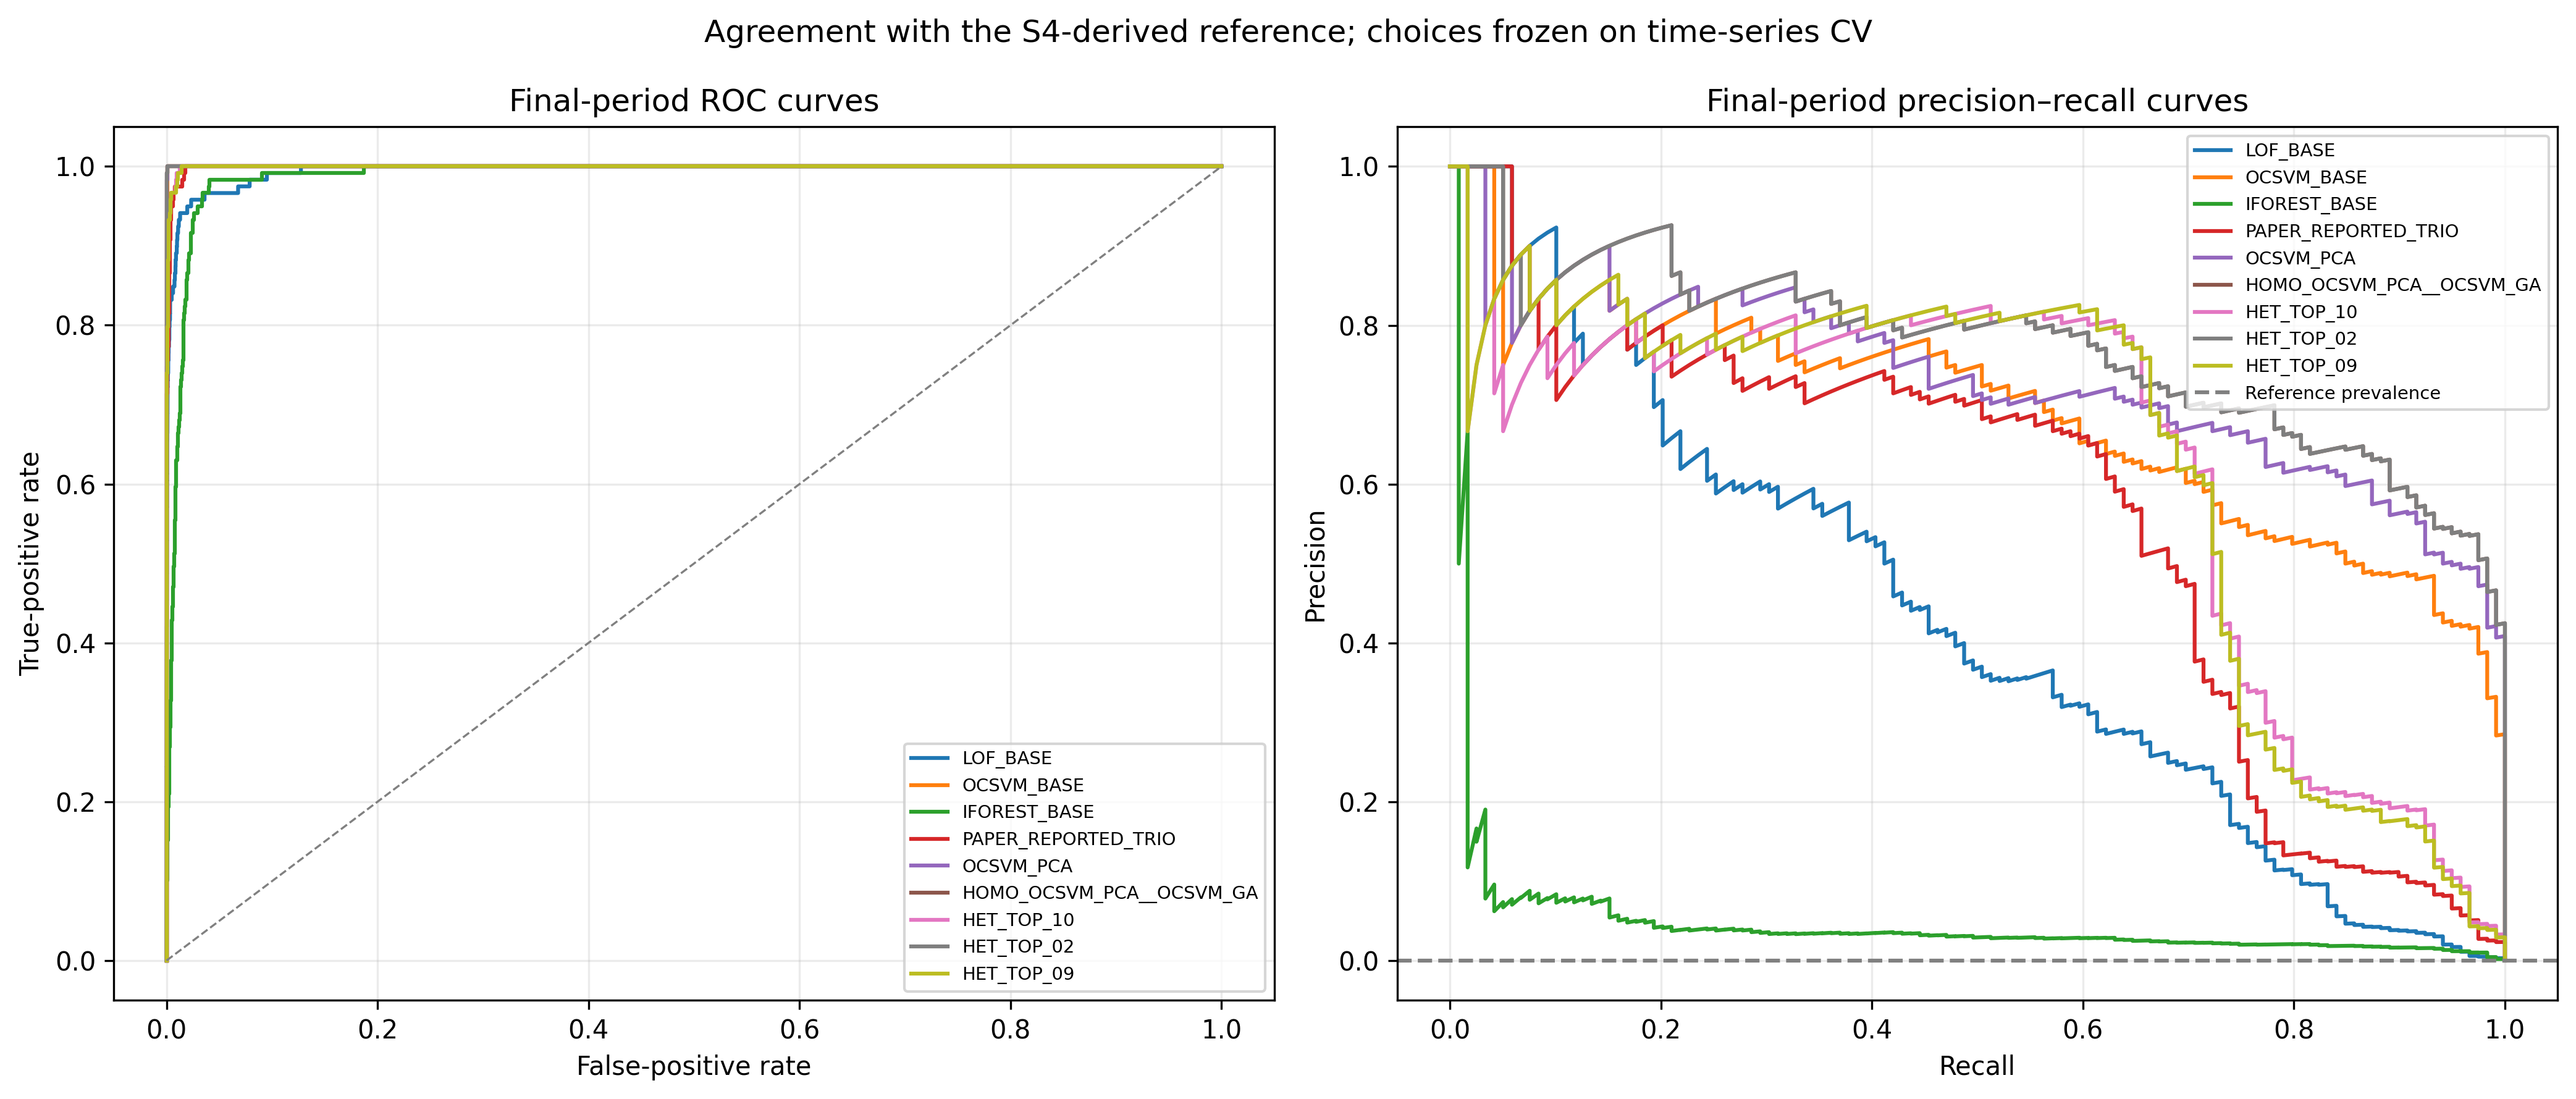

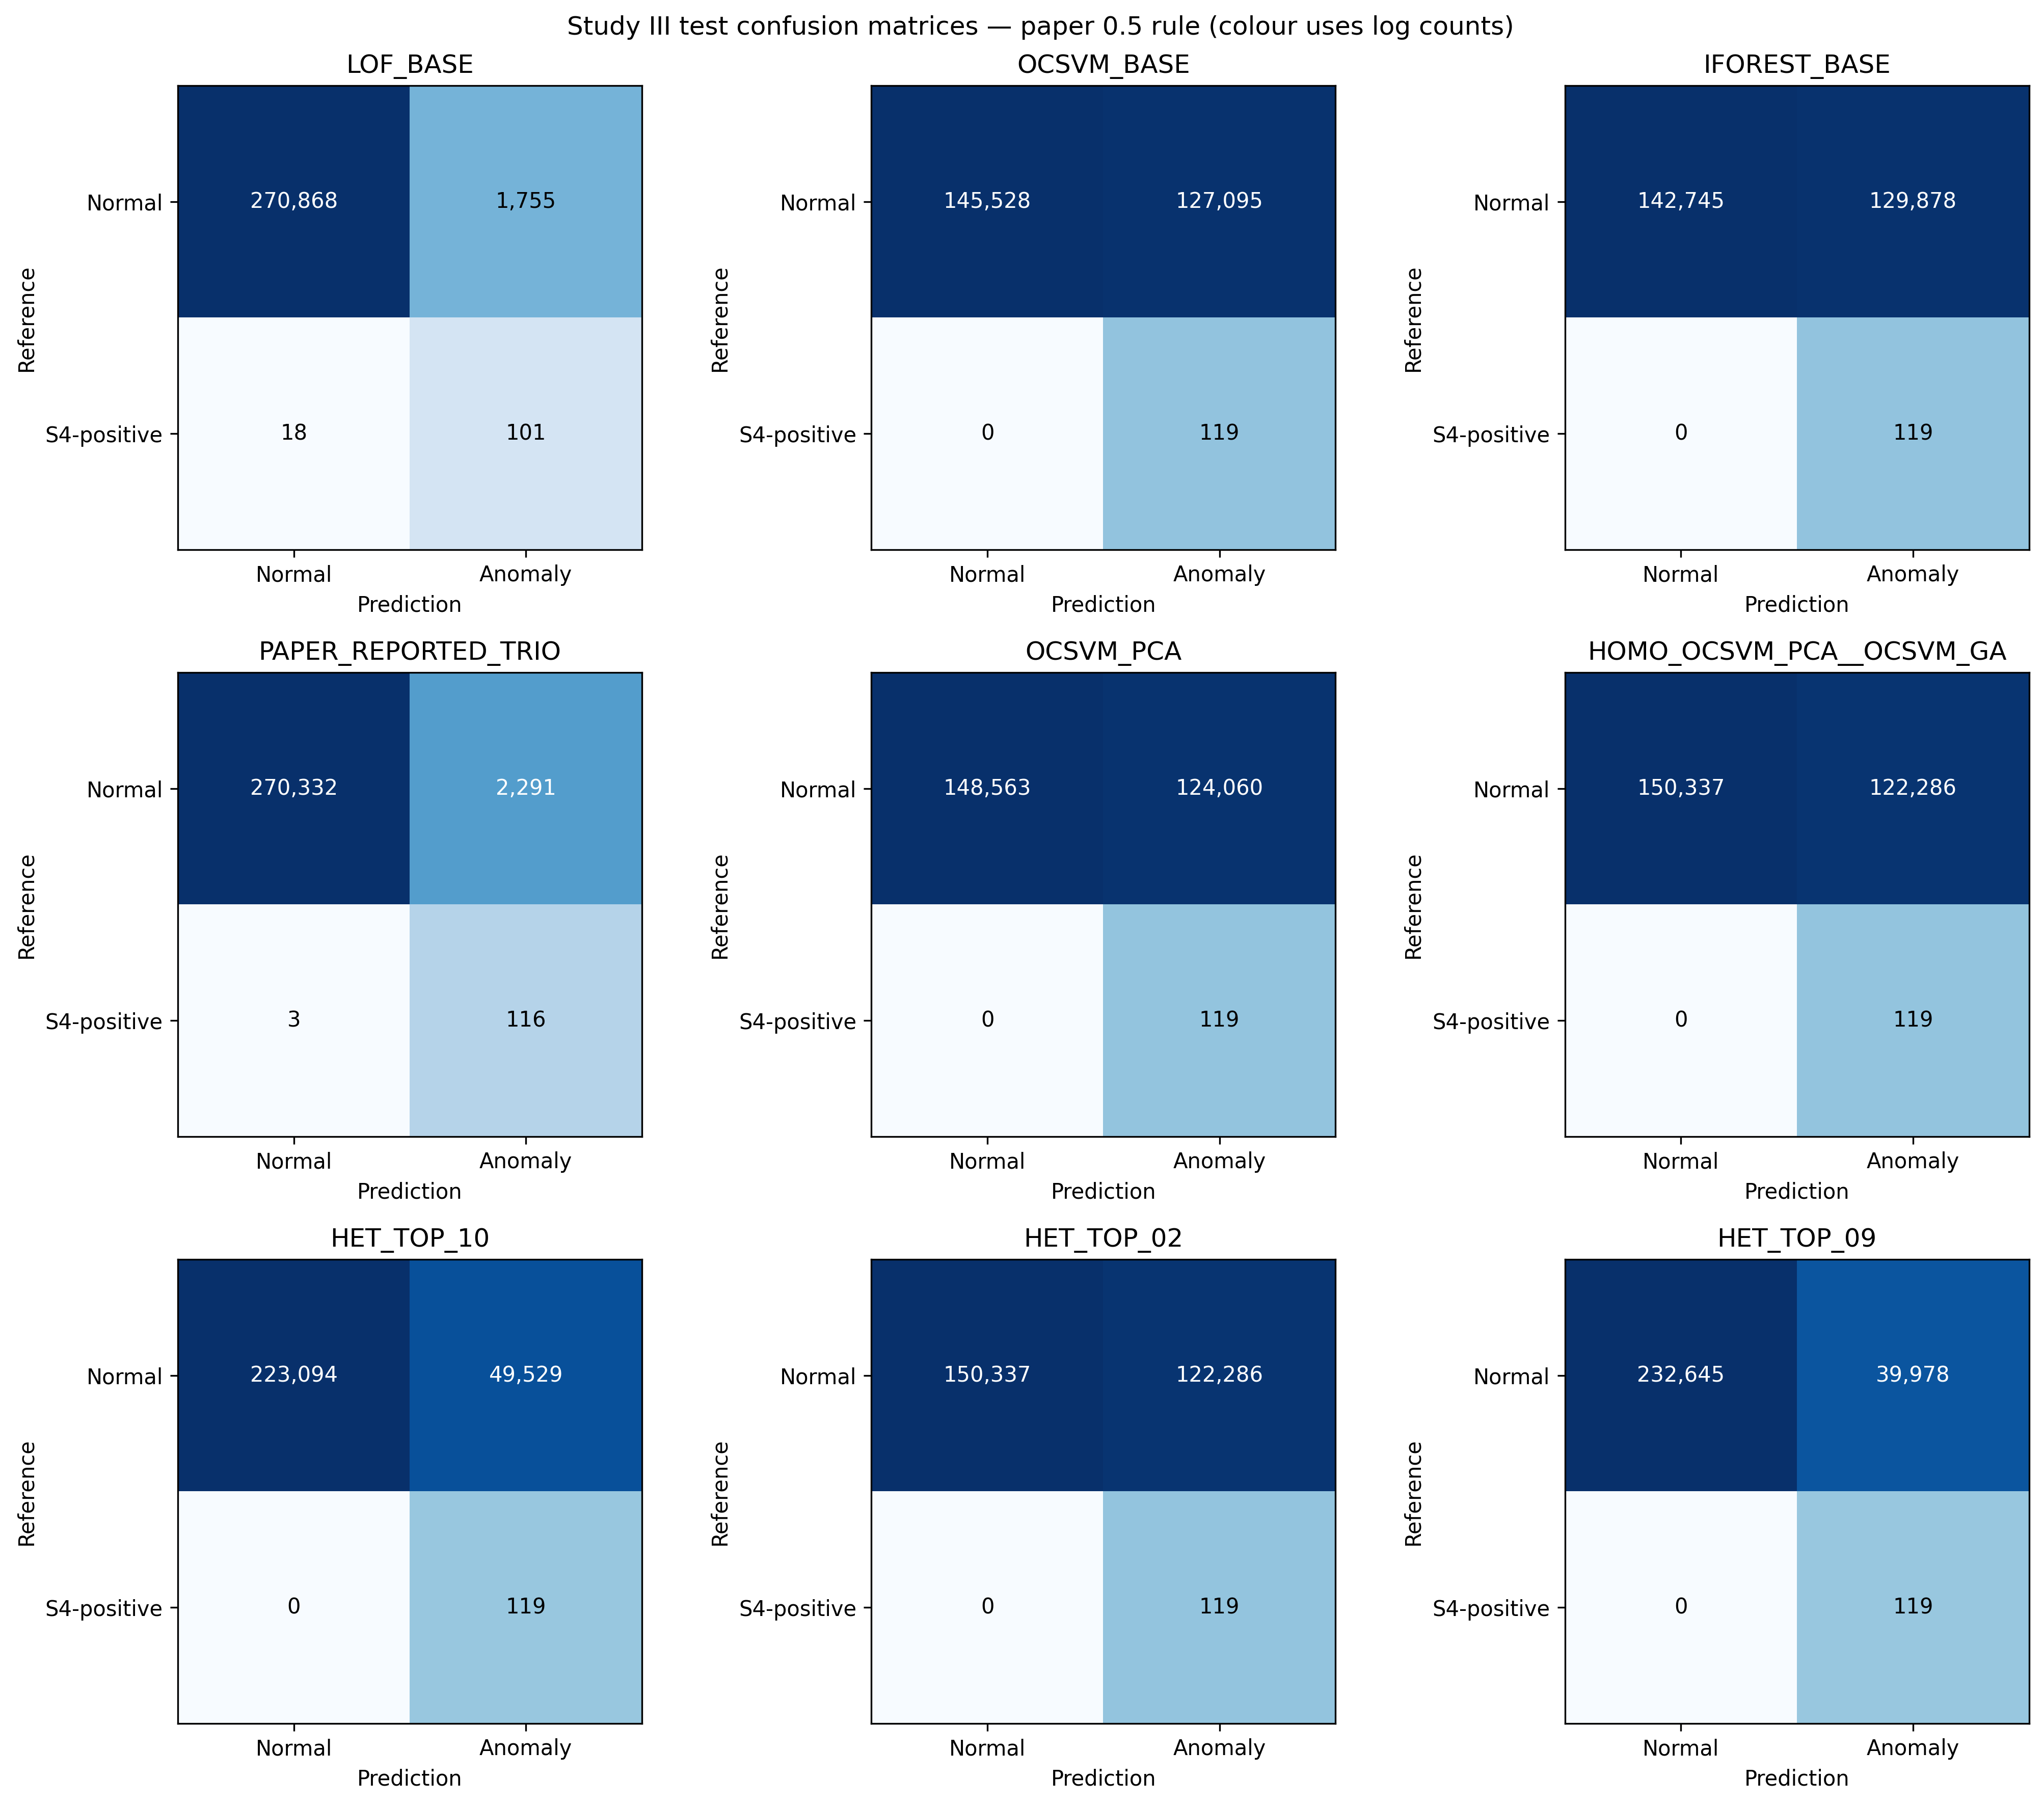

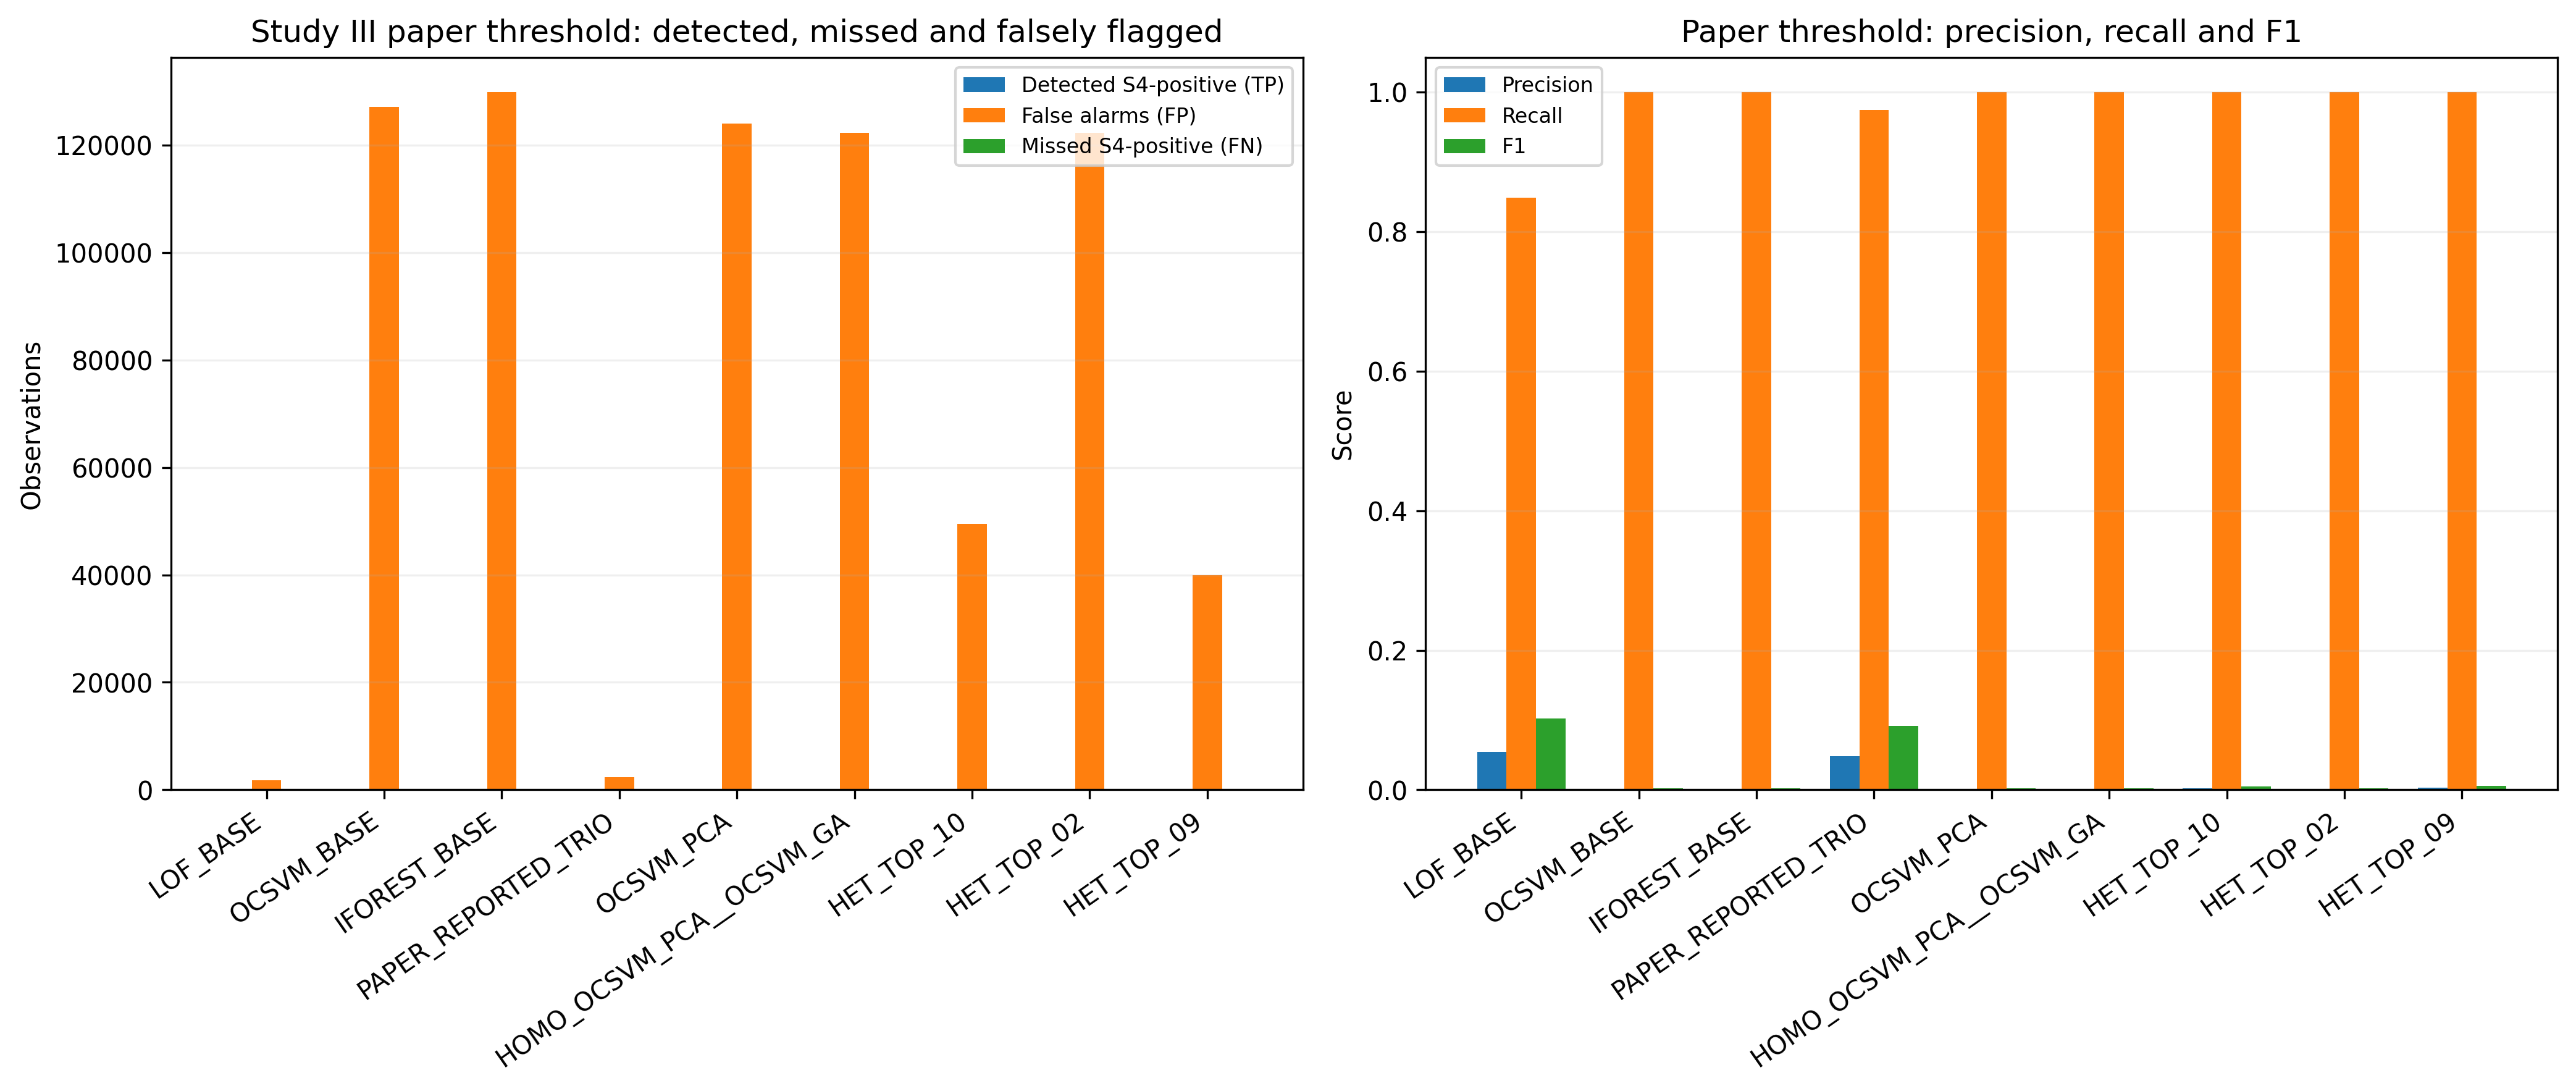

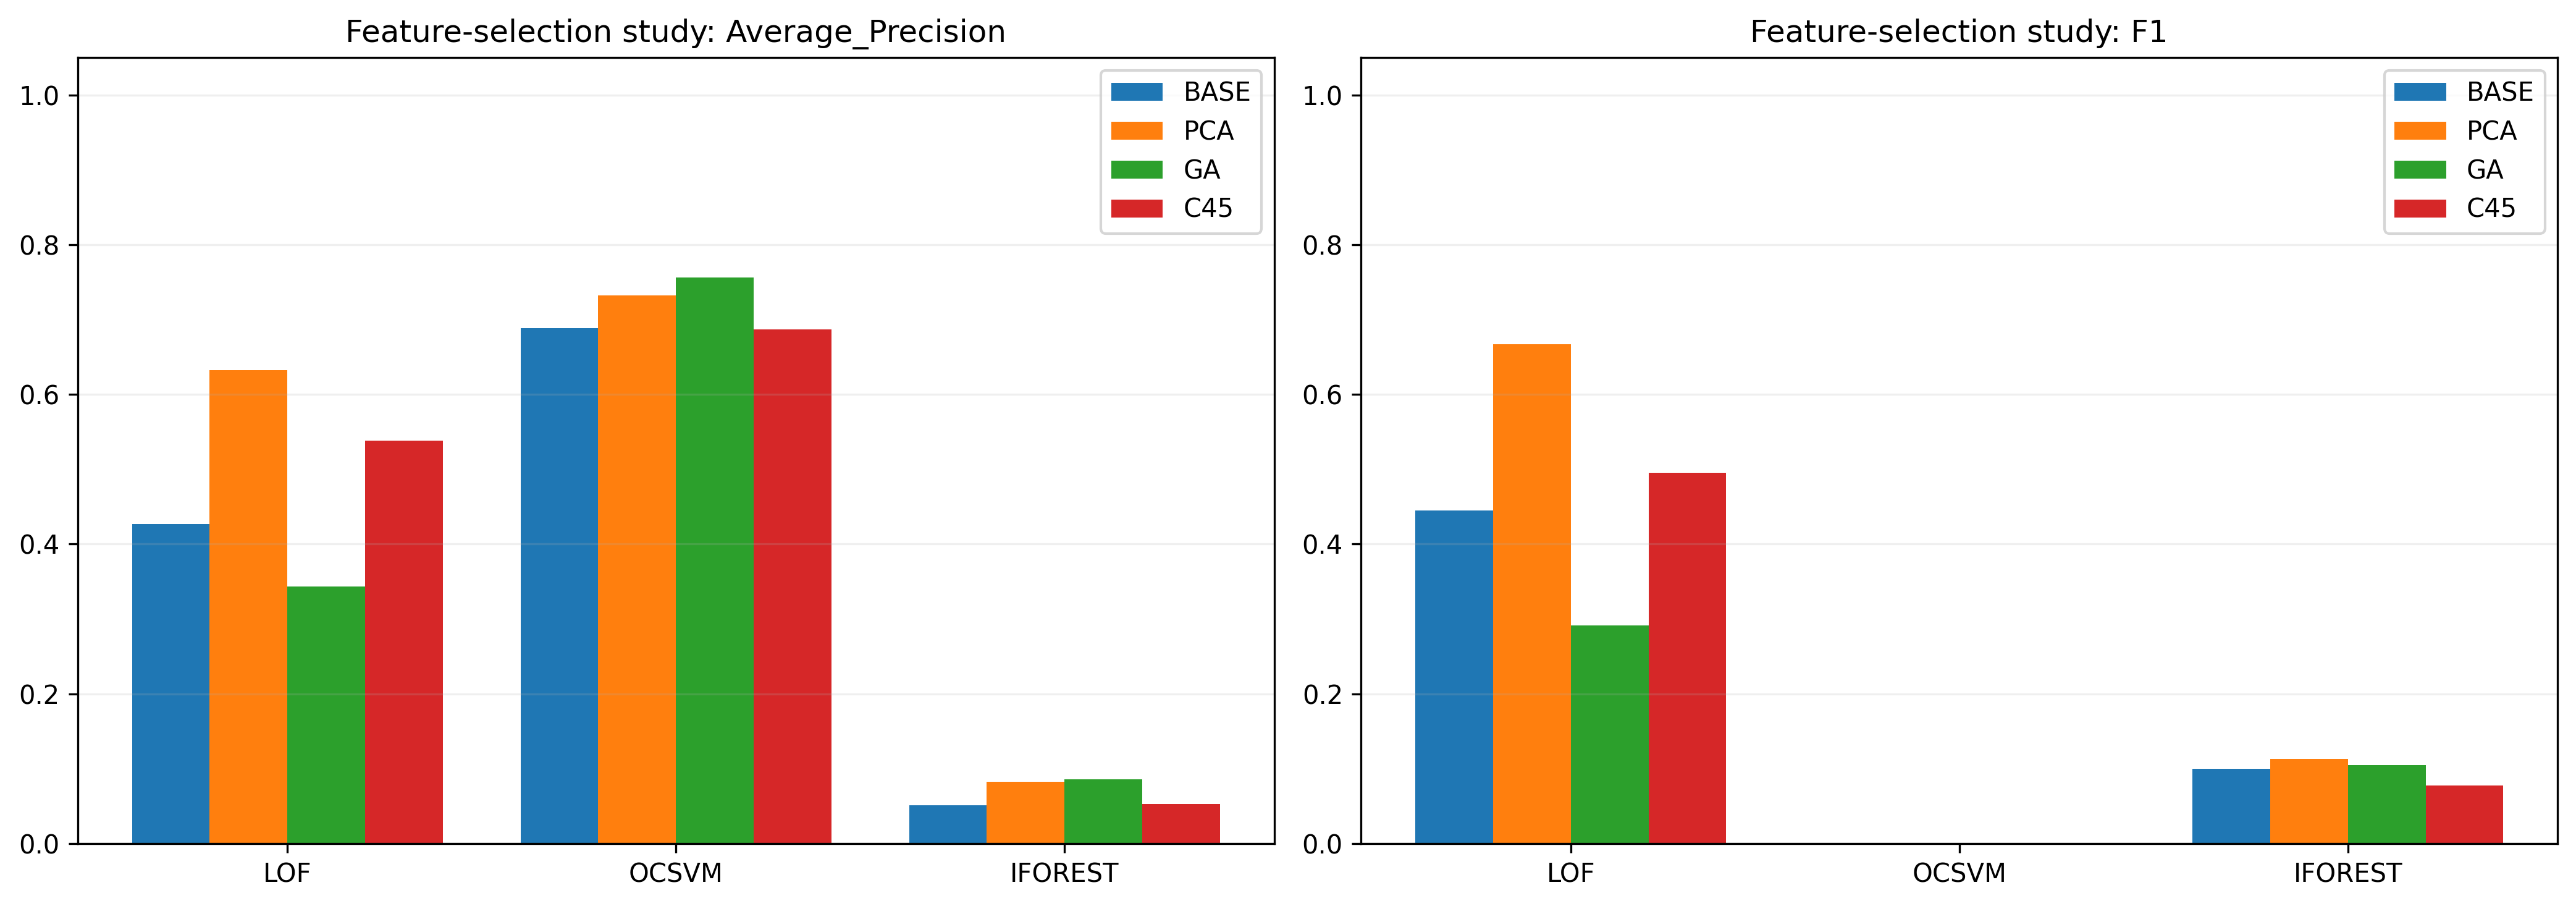

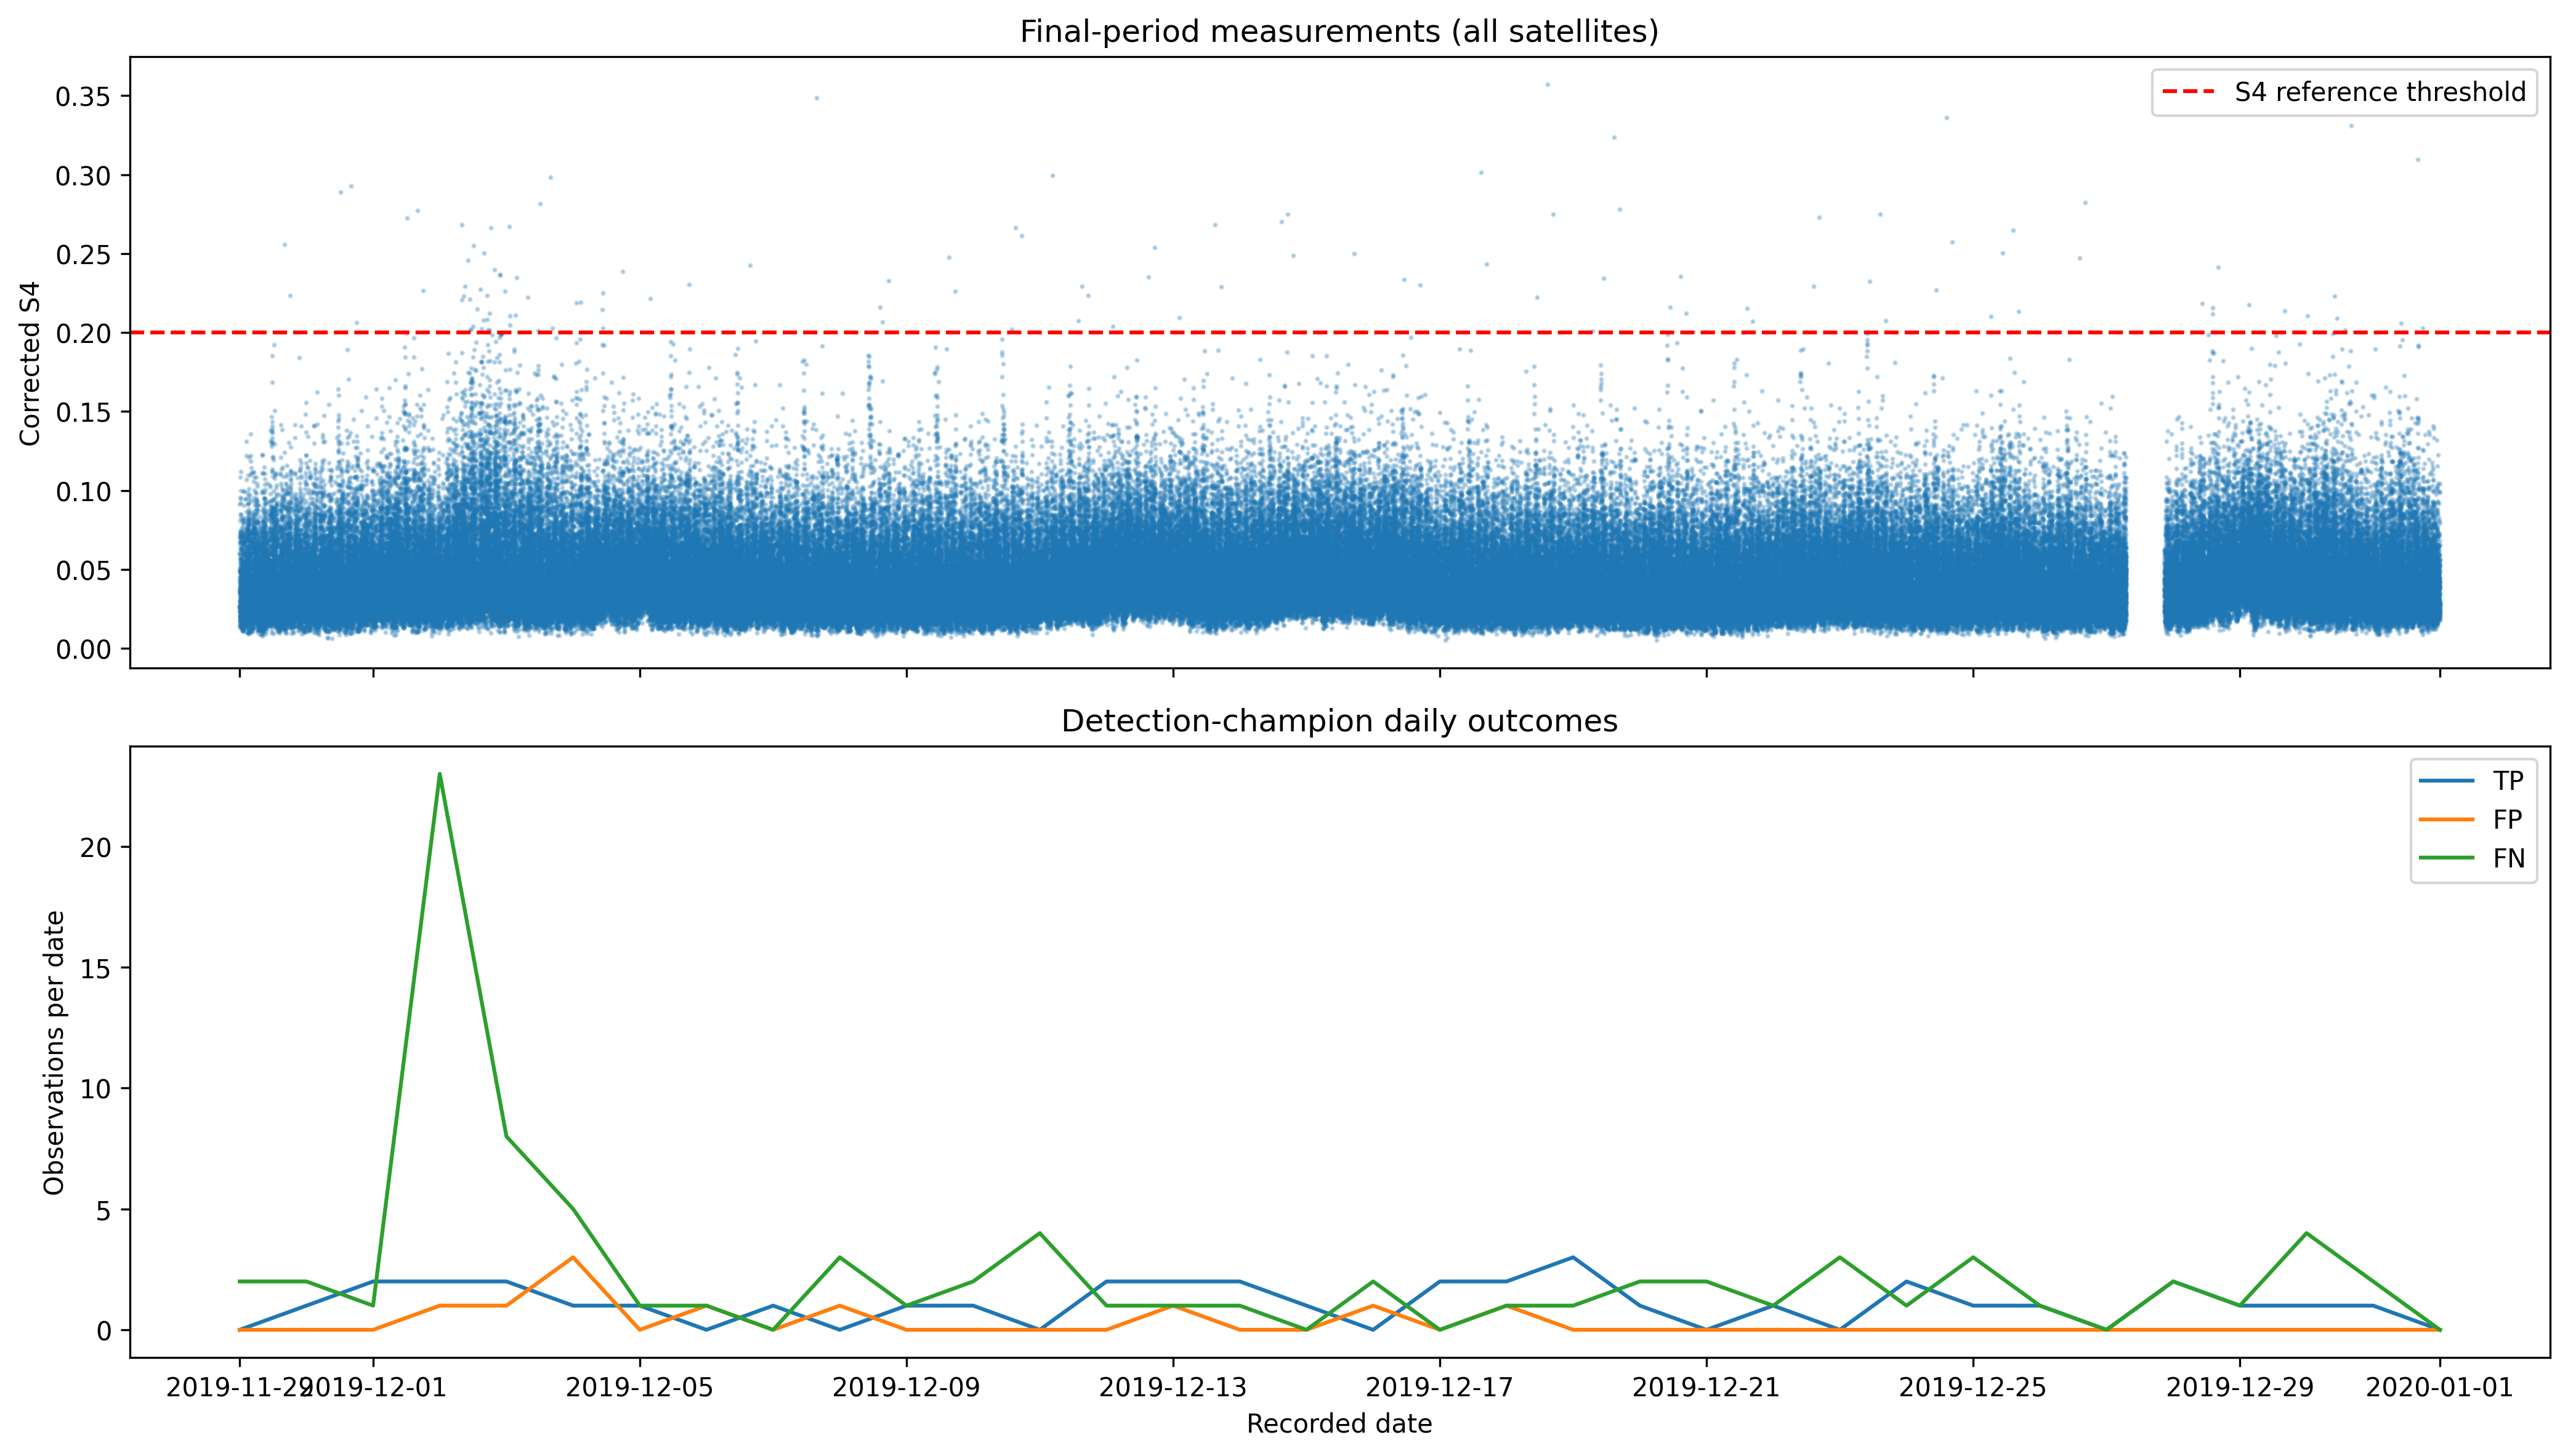

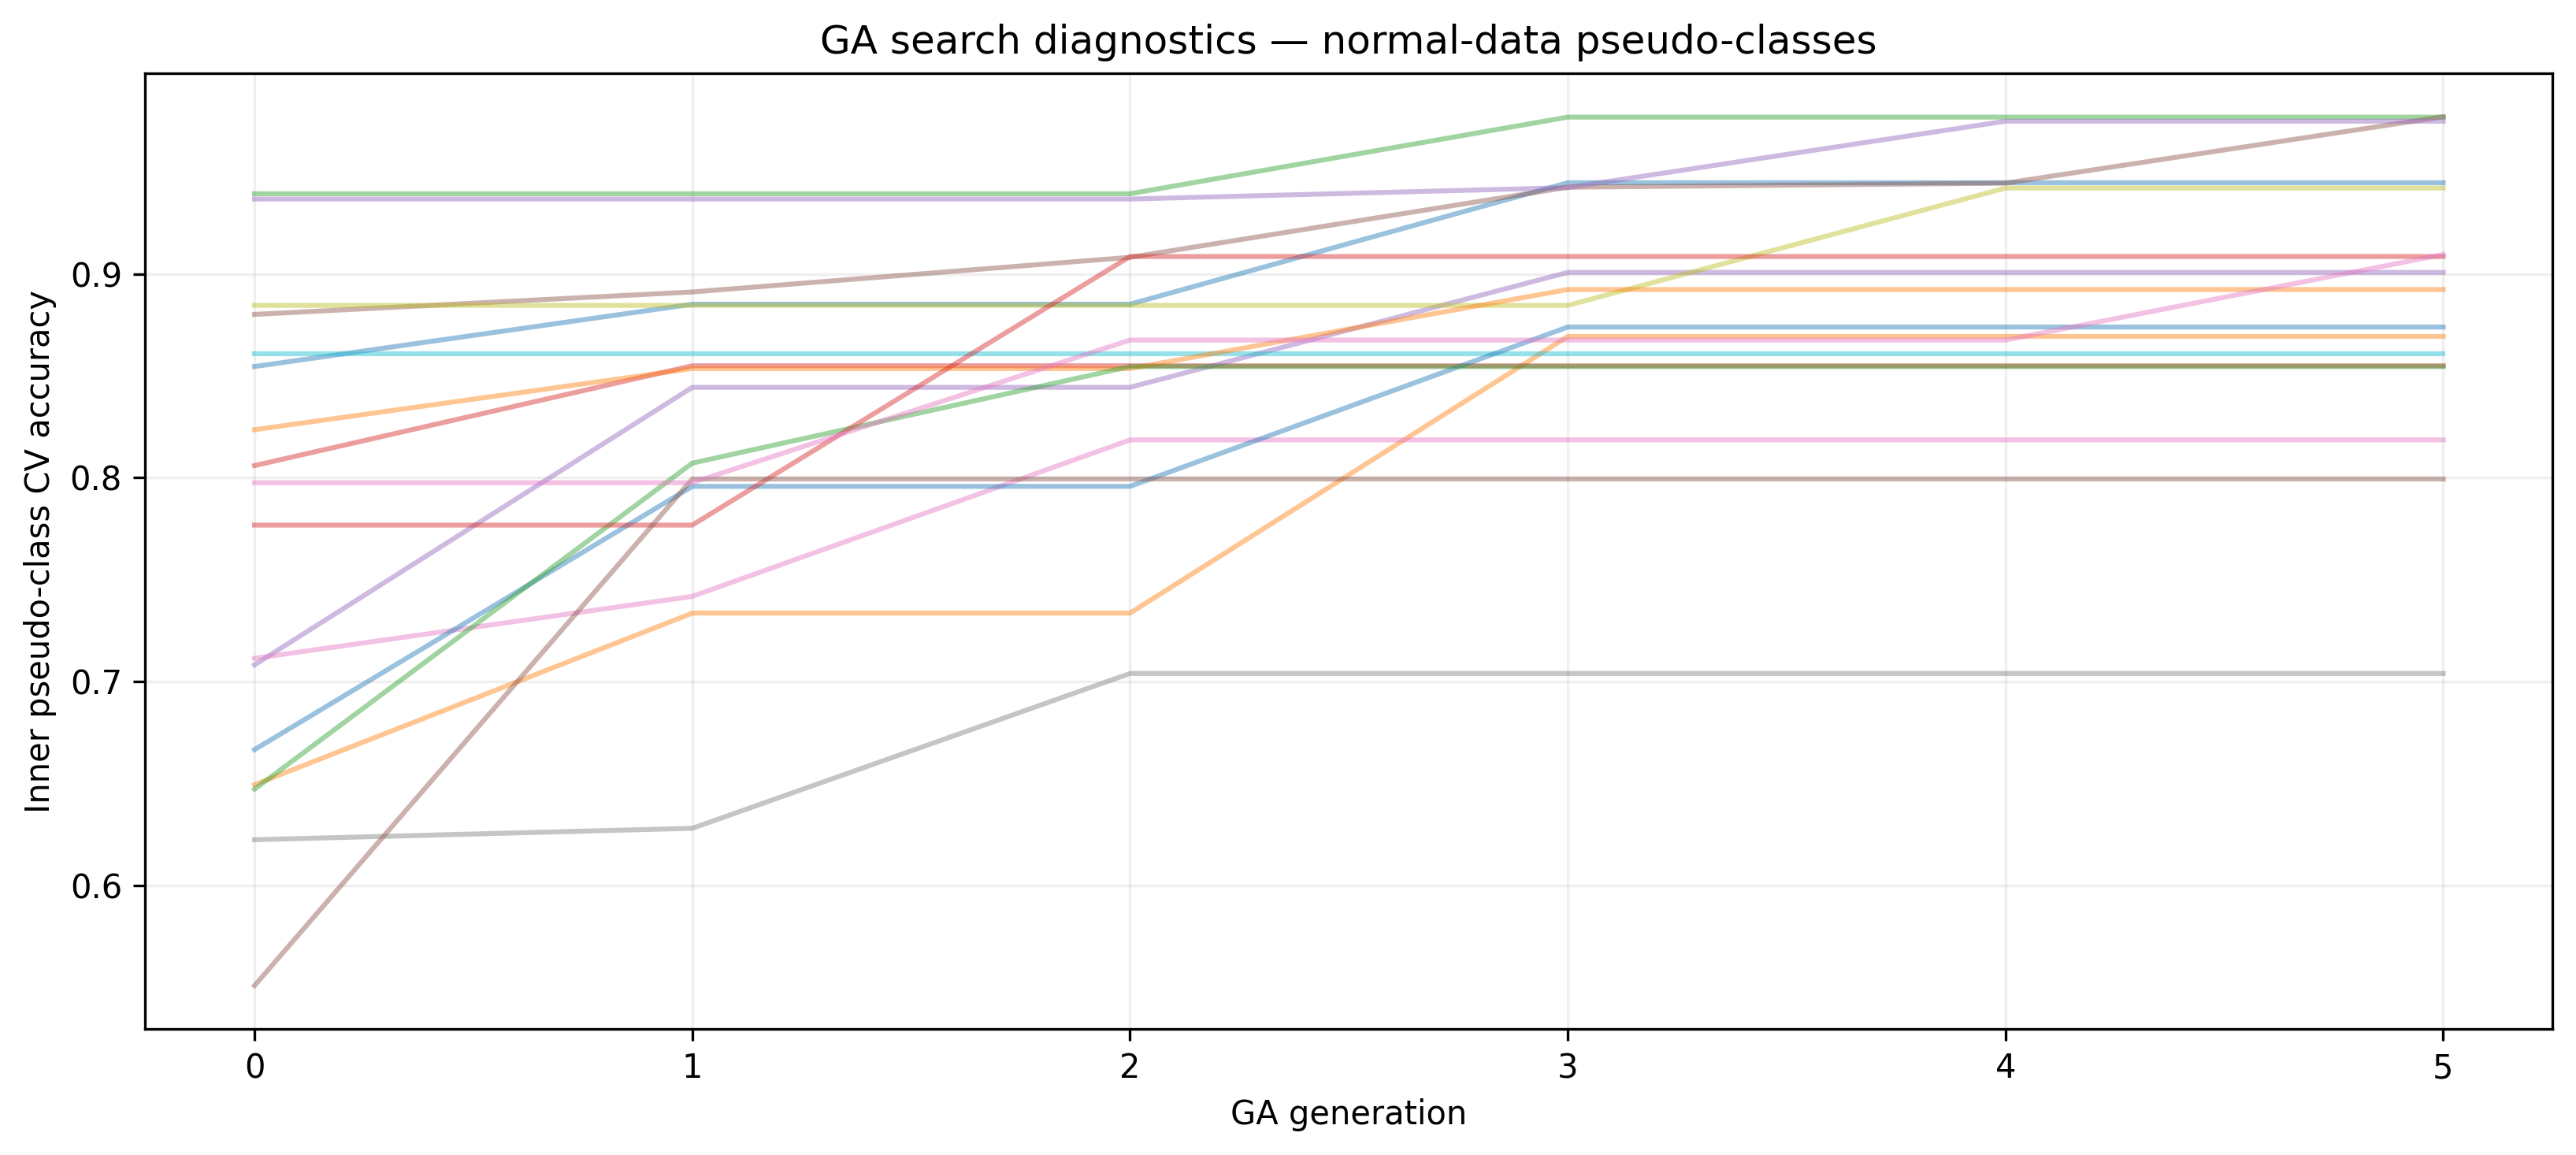

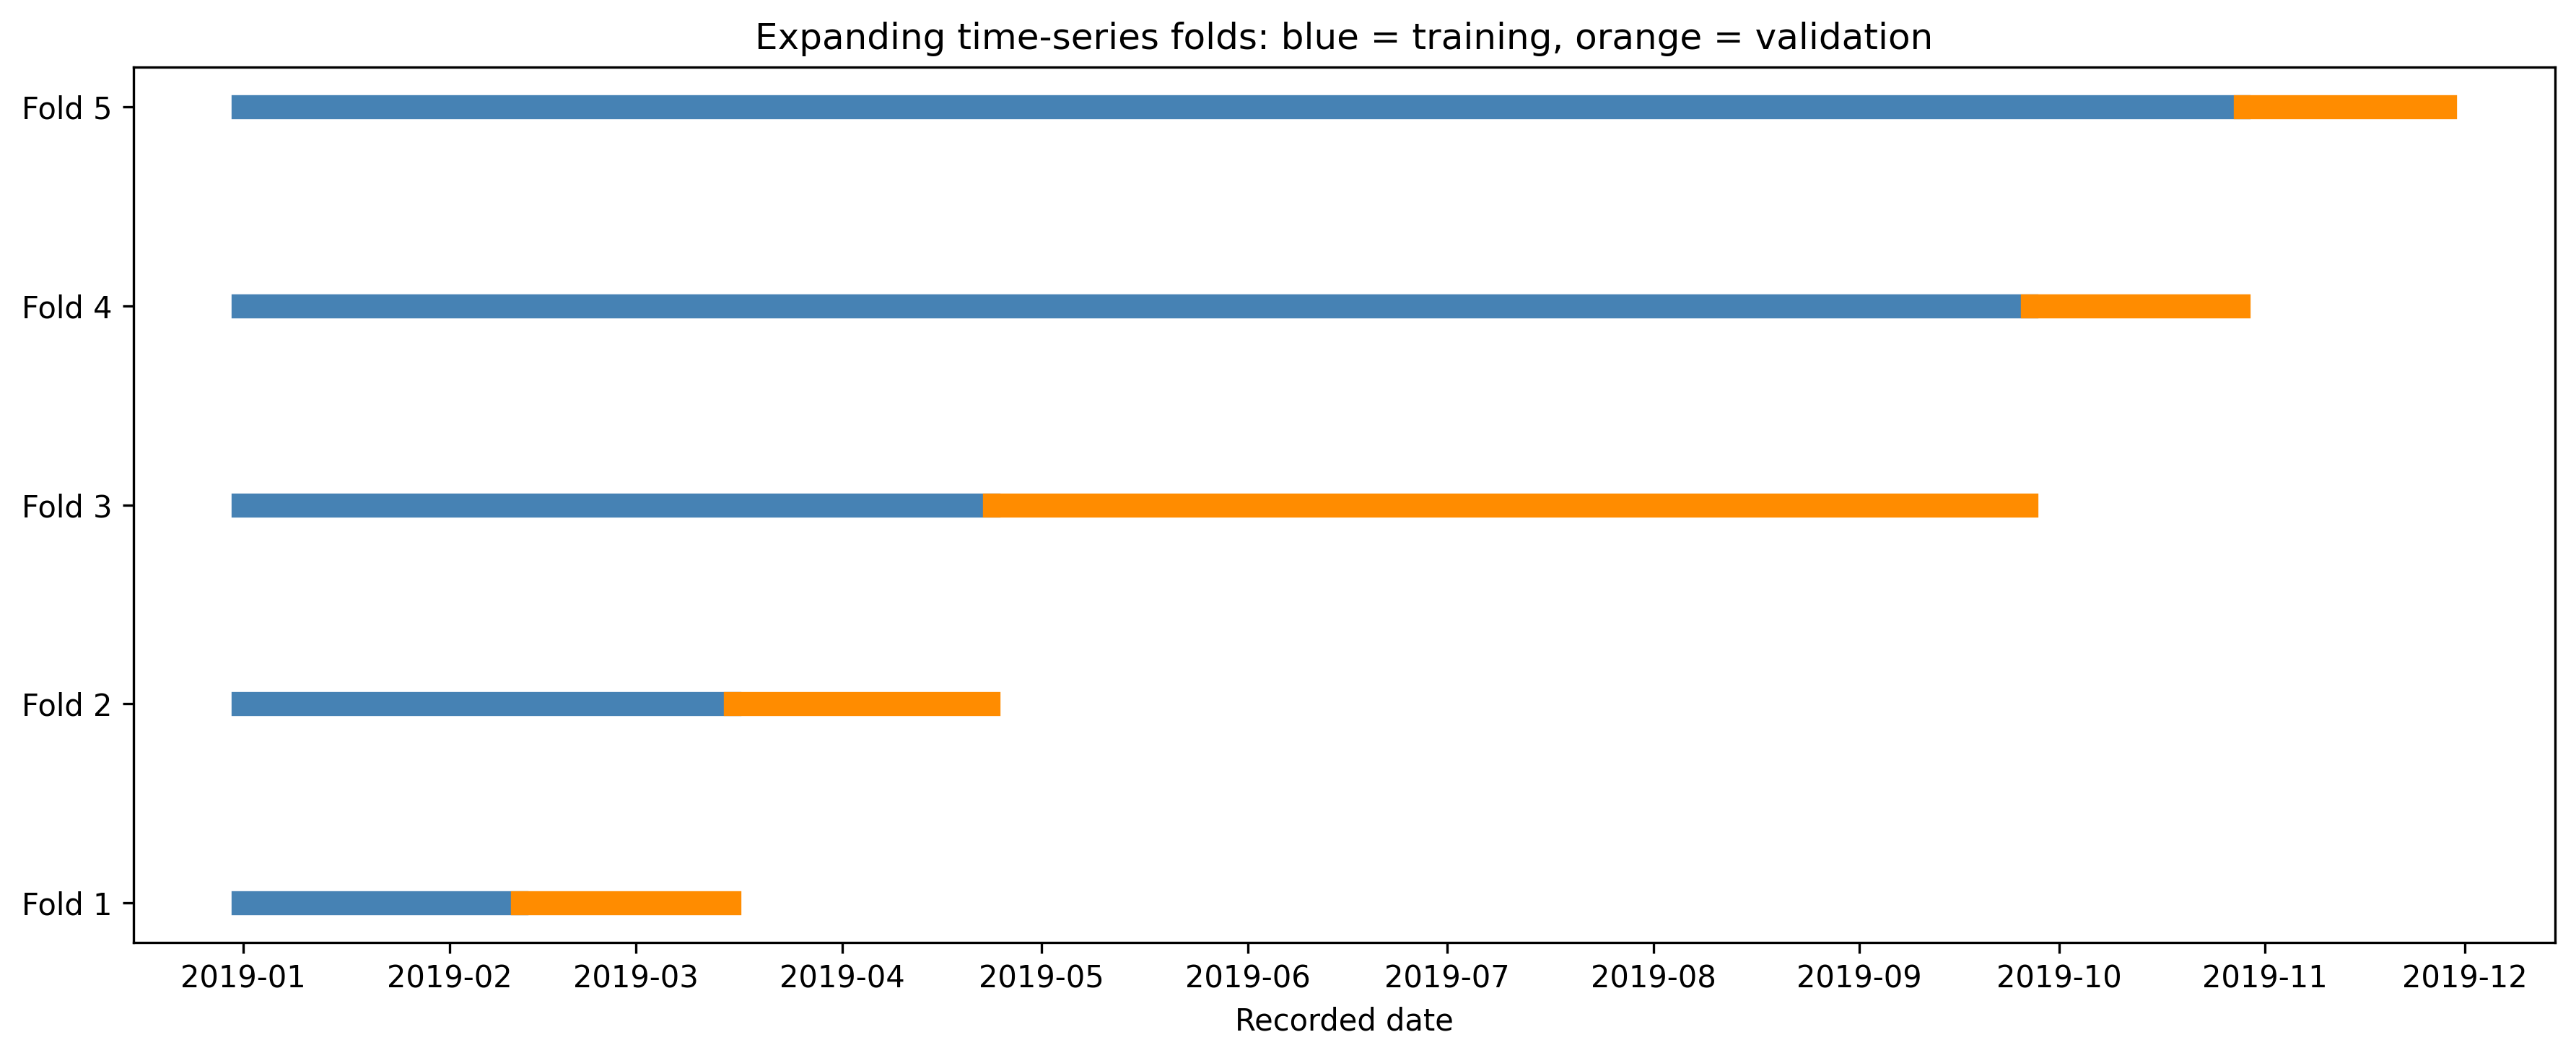

In [12]:
paper_results = run_paper_workflow()
